Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded: 70000 rows, 13 columns
+---+-----+------+------+------+-----+-----+-----------+----+-----+----+------+------+
| id|  age|gender|height|weight|ap_hi|ap_lo|cholesterol|gluc|smoke|alco|active|cardio|
+---+-----+------+------+------+-----+-----+-----------+----+-----+----+------+------+
|  0|18393|     2|   168|  62.0|  110|   80|          1|   1|    0|   0|     1|     0|
|  1|20228|     1|   156|  85.0|  140|   90|          3|   1|    0|   0|     1|     1|
|  2|18857|     1|   165|  64.0|  130|   70|          3|   1|    0|   0|     0|     1|
|  3|17623|     2|   169|  82.0|  150|  100|          1|   1|    0|   0|     1|     1|
|  4|17474|     1|   156|  56.0|  100|   60|          1|   1|    0|   0|     0|     0|
+---+-----+------+------+------+-----+-----+-----------+----+-----+----+------+------+
only showing top 5 rows
Missing values:
+---+---+

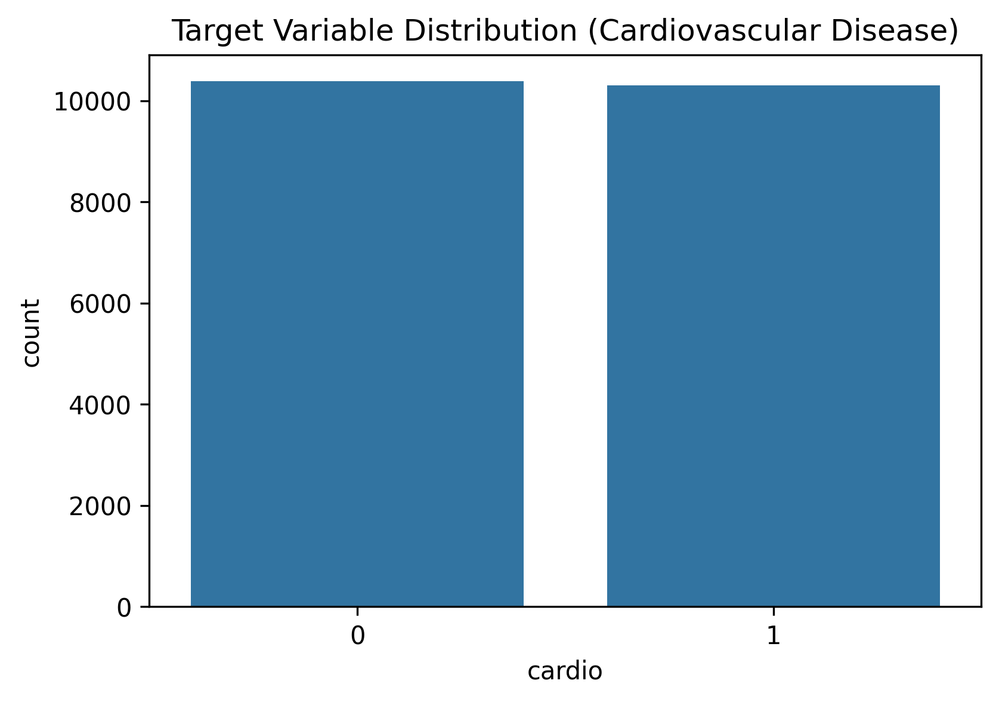

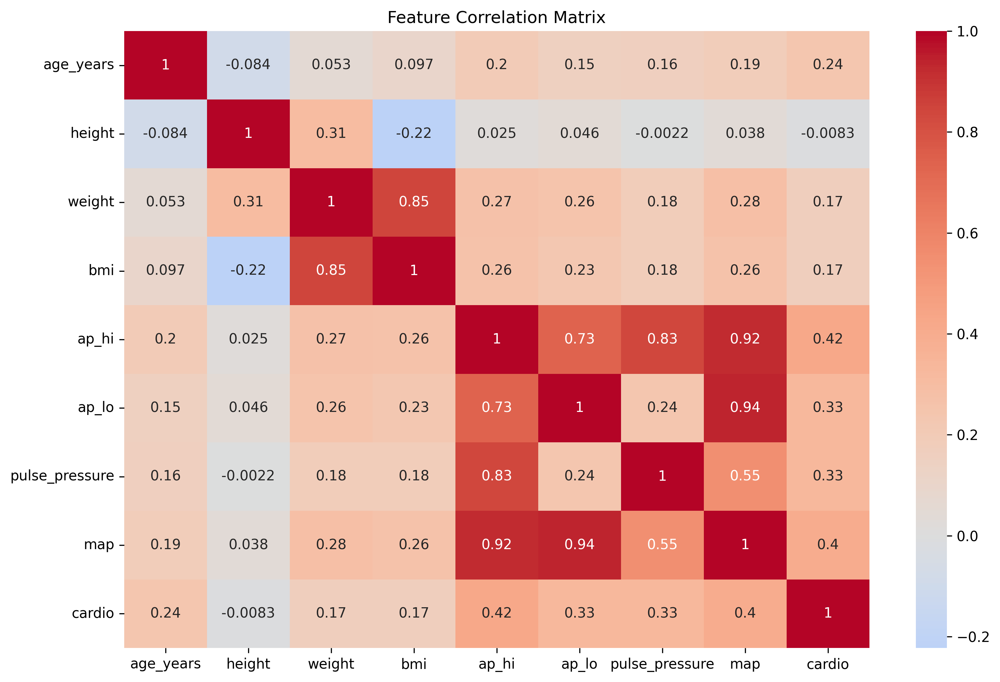

Training set: 47920 rows
Validation set: 10420 rows
Test set: 10275 rows
Training set size: (47920, 20)
Validation set size: (10420, 20)
Test set size: (10275, 20)
Features prepared and scaled successfully
Feature Correlation Matrix Values:
                age_years  height  weight    bmi  ap_hi  ap_lo  \
age_years           1.000  -0.084   0.053  0.097  0.199  0.152   
height             -0.084   1.000   0.306 -0.222  0.025  0.046   
weight              0.053   0.306   1.000  0.846  0.274  0.257   
bmi                 0.097  -0.222   0.846  1.000  0.260  0.234   
ap_hi               0.199   0.025   0.274  0.260  1.000  0.734   
ap_lo               0.152   0.046   0.257  0.234  0.734  1.000   
pulse_pressure      0.161  -0.002   0.183  0.181  0.833  0.237   
map                 0.187   0.038   0.285  0.264  0.922  0.940   
cardio              0.236  -0.008   0.168  0.170  0.423  0.334   

                pulse_pressure    map  cardio  
age_years                0.161  0.187   0.236  
he

In [ ]:

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, count, isnan, isnull, round
import pyspark.sql.functions as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


spark = SparkSession.builder \
    .appName("CVD_Risk_Prediction") \
    .config("spark.driver.memory", "8g") \
    .config("spark.executor.memory", "8g") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .getOrCreate()


from google.colab import drive
drive.mount('/content/drive')


drive_path = "/content/drive/MyDrive/Colab Notebooks/DA/CVD/"
file_name = "cardio_train.csv"
file_path = drive_path + file_name

df = spark.read.csv(file_path, sep=';', header=True, inferSchema=True)
print(f"Dataset loaded: {df.count()} rows, {len(df.columns)} columns")
df.show(5)


missing_df = df.select([count(when(isnan(c) | isnull(c), c)).alias(c) for c in df.columns])
print("Missing values:")
missing_df.show()


print("Original record count:", df.count())


df_clean = df.filter((col("ap_hi") > col("ap_lo")) &
                      (col("ap_hi") < 250) &
                      (col("ap_lo") > 40) &
                      (col("ap_hi") > 60))


df_clean = df_clean.filter((col("height") > 100) & (col("height") < 220) &
                            (col("weight") > 30) & (col("weight") < 200))

print("After cleaning:", df_clean.count())


df_clean = df_clean.withColumn("age_years", round(col("age") / 365.25, 1))
df_clean = df_clean.withColumn("height_m", col("height") / 100)
df_clean = df_clean.withColumn("bmi", round(col("weight") / (col("height_m") ** 2), 1))
df_clean = df_clean.withColumn("pulse_pressure", col("ap_hi") - col("ap_lo"))
df_clean = df_clean.withColumn("map", col("ap_lo") + (col("ap_hi") - col("ap_lo")) / 3)


df_clean = df_clean.withColumn("age_group",
                               when(col("age_years") < 40, "young")
                               .when(col("age_years") < 55, "middle")
                               .when(col("age_years") < 70, "senior")
                               .otherwise("elderly"))


df_clean = df_clean.withColumn("risk_score",
                               col("cholesterol") * 0.3 +
                               col("gluc") * 0.2 +
                               col("smoke") * 0.1 +
                               col("alco") * 0.1 +
                               col("active") * (-0.1) +
                               (col("bmi") / 30) * 0.3)

print("Features created successfully")
df_clean.printSchema()



sample_fraction = 0.3
df_sample = df_clean.sample(withReplacement=False, fraction=sample_fraction, seed=42)
df_pandas = df_sample.toPandas()

print(f"Sample size for EDA: {len(df_pandas)} rows")


numeric_cols = ['age_years', 'height', 'weight', 'bmi', 'ap_hi', 'ap_lo', 'pulse_pressure', 'map']
print("Numerical features statistics:")
df_pandas[numeric_cols].describe()


plt.figure(figsize=(6, 4))
sns.countplot(x='cardio', data=df_pandas)
plt.title('Target Variable Distribution (Cardiovascular Disease)')
plt.show()

plt.figure(figsize=(12, 8))
corr_cols = numeric_cols + ['cardio']
corr_matrix = df_pandas[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Feature Correlation Matrix')
plt.show()


train_df, temp_df = df_clean.randomSplit([0.7, 0.3], seed=42)
val_df, test_df = temp_df.randomSplit([0.5, 0.5], seed=42)

print(f"Training set: {train_df.count()} rows")
print(f"Validation set: {val_df.count()} rows")
print(f"Test set: {test_df.count()} rows")


numeric_features = ['age_years', 'height', 'weight', 'bmi', 'ap_hi', 'ap_lo',
                    'pulse_pressure', 'map', 'risk_score']
binary_features = ['gender', 'smoke', 'alco', 'active']
ordinal_features = ['cholesterol', 'gluc']
categorical_features = ['age_group']

target = 'cardio'


train_pd = train_df.toPandas()
val_pd = val_df.toPandas()
test_pd = test_df.toPandas()

print(f"Training set size: {train_pd.shape}")
print(f"Validation set size: {val_pd.shape}")
print(f"Test set size: {test_pd.shape}")


from sklearn.preprocessing import StandardScaler, LabelEncoder


le = LabelEncoder()
train_pd['age_group_encoded'] = le.fit_transform(train_pd['age_group'])
val_pd['age_group_encoded'] = le.transform(val_pd['age_group'])
test_pd['age_group_encoded'] = le.transform(test_pd['age_group'])

all_features = numeric_features + binary_features + ordinal_features + ['age_group_encoded']


X_train = train_pd[all_features]
y_train = train_pd[target]
X_val = val_pd[all_features]
y_val = val_pd[target]
X_test = test_pd[all_features]
y_test = test_pd[target]


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Features prepared and scaled successfully")



corr_matrix = df_pandas[corr_cols].corr()
print("Feature Correlation Matrix Values:")
print(corr_matrix.round(3))

In [ ]:
# ============================================
# SUPPRESS ALL WARNINGS
# ============================================
import warnings
warnings.filterwarnings('ignore')
warnings.simplefilter('ignore')

# Suppress specific library warnings
import logging
logging.getLogger('matplotlib').setLevel(logging.ERROR)
logging.getLogger('PIL').setLevel(logging.ERROR)
logging.getLogger('fontTools').setLevel(logging.ERROR)

# For Jupyter/Colab specific warnings
import os
os.environ['PYTHONWARNINGS'] = 'ignore'

# Suppress sklearn warnings
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn

# Suppress future warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning)
warnings.simplefilter(action='ignore', category=DeprecationWarning)

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                           f1_score, roc_auc_score, confusion_matrix,
                           classification_report)
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Dictionary to store results
results = {
    'Model': [],
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1-Score': [],
    'AUC-ROC': [],
    'Training Time': []
}


**LOGISTIC REGRESSION**

In [ ]:
# ============================================
# CELL: TRAIN LOGISTIC REGRESSION FIRST
# ============================================
from sklearn.linear_model import LogisticRegression
import time

print("="*50)
print("Training Model 1: Logistic Regression")
print("="*50)

start_time = time.time()

# Train with hyperparameter tuning
lr_params = {'C': [0.01, 0.1, 1, 10], 'solver': ['liblinear', 'lbfgs']}
lr = LogisticRegression(max_iter=1000, random_state=42)
lr_grid = GridSearchCV(lr, lr_params, cv=5, scoring='roc_auc')
lr_grid.fit(X_train_scaled, y_train)

# Best model
lr_best = lr_grid.best_estimator_
y_pred_lr = lr_best.predict(X_val_scaled)
y_pred_proba_lr = lr_best.predict_proba(X_val_scaled)[:, 1]

# Store results
results['Model'].append('Logistic Regression')
results['Accuracy'].append(accuracy_score(y_val, y_pred_lr))
results['Precision'].append(precision_score(y_val, y_pred_lr))
results['Recall'].append(recall_score(y_val, y_pred_lr))
results['F1-Score'].append(f1_score(y_val, y_pred_lr))
results['AUC-ROC'].append(roc_auc_score(y_val, y_pred_proba_lr))
results['Training Time'].append(time.time() - start_time)

print(f"Best parameters: {lr_grid.best_params_}")
print(f"Accuracy: {results['Accuracy'][-1]:.4f}")
print(f"AUC-ROC: {results['AUC-ROC'][-1]:.4f}")


Training Model 1: Logistic Regression
Best parameters: {'C': 0.01, 'solver': 'lbfgs'}
Accuracy: 0.7312
AUC-ROC: 0.7972


MODEL 1: LOGISTIC REGRESSION - DETAILED EVALUATION

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      No CVD       0.71      0.79      0.75      5237
         CVD       0.76      0.67      0.71      5183

    accuracy                           0.73     10420
   macro avg       0.73      0.73      0.73     10420
weighted avg       0.73      0.73      0.73     10420


--- CONFUSION MATRIX ---
[[4163 1074]
 [1727 3456]]


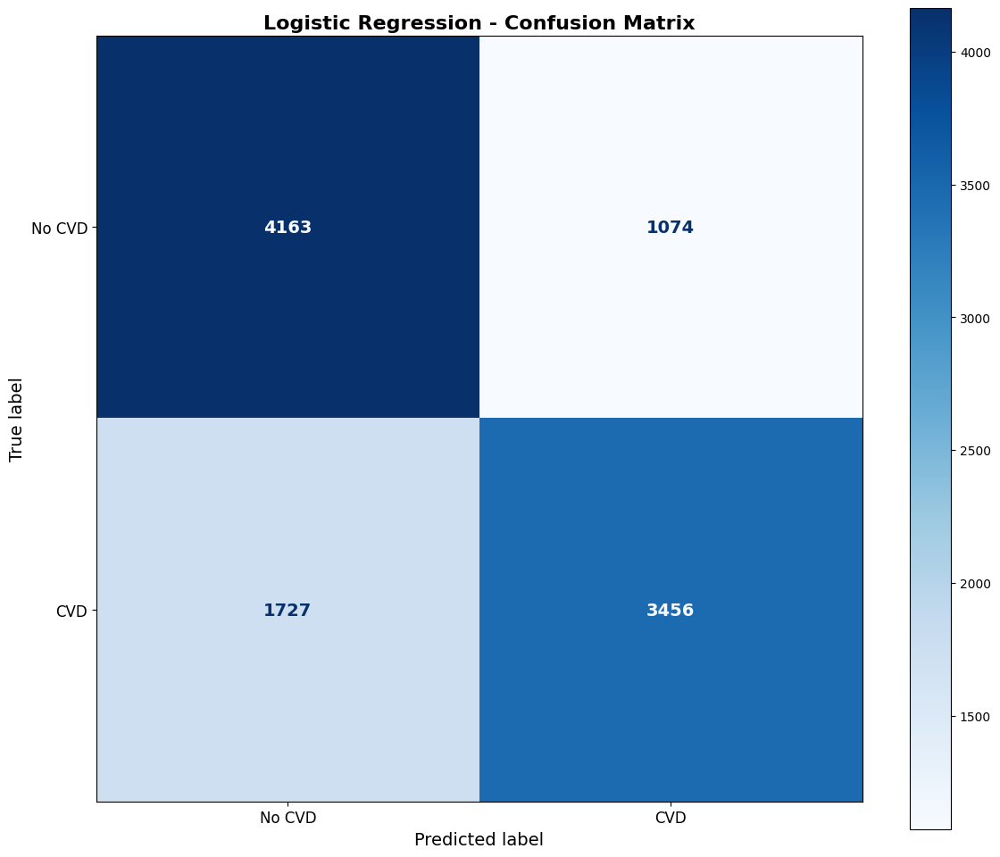


--- ADDITIONAL METRICS ---
Accuracy:  0.7312
Precision: 0.7629
Recall:    0.6668
F1-Score:  0.7116
AUC-ROC:   0.7972


<Figure size 640x480 with 0 Axes>

In [ ]:
# ============================================
# CELL: LOGISTIC REGRESSION - DETAILED EVALUATION WITH LARGER TEXT
# ============================================

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

print("="*70)
print("MODEL 1: LOGISTIC REGRESSION - DETAILED EVALUATION")
print("="*70)

# Use the already trained lr_best
y_pred_lr = lr_best.predict(X_val_scaled)
y_pred_proba_lr = lr_best.predict_proba(X_val_scaled)[:, 1]

# Classification Report
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_val, y_pred_lr, target_names=['No CVD', 'CVD']))

# Confusion Matrix
cm_lr = confusion_matrix(y_val, y_pred_lr)
print("\n--- CONFUSION MATRIX ---")
print(cm_lr)

# Plot Confusion Matrix with LARGER TEXT
fig, ax = plt.subplots(figsize=(12, 10))  # Bigger figure size

# Create confusion matrix display with custom text properties
disp = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['No CVD', 'CVD'])
disp.plot(ax=ax, cmap='Blues', values_format='d')

# Increase text sizes
ax.title.set_size(16)           # Title size
ax.xaxis.label.set_size(14)      # X-axis label size
ax.yaxis.label.set_size(14)      # Y-axis label size

# Increase tick label sizes
ax.tick_params(axis='both', which='major', labelsize=12)

# Increase the numbers inside the matrix
for text in disp.text_.ravel():
    text.set_size(14)            # Numbers inside matrix
    text.set_weight('bold')      # Make numbers bold

plt.title('Logistic Regression - Confusion Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Save the figure with high DPI
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/cm_lr_large.png',
            dpi=300, bbox_inches='tight', facecolor='white')

# Additional Metrics
print("\n--- ADDITIONAL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_lr):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_lr):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred_lr):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_lr):.4f}")

** DECISION TREE**

In [ ]:
from sklearn.tree import DecisionTreeClassifier

print("="*70)
print("MODEL 2: DECISION TREE - TRAINING & EVALUATION")
print("="*70)

# --- TRAINING ---
start_time = time.time()
dt_params = {'max_depth': [5, 10, 15, 20], 'min_samples_split': [2, 5, 10]}
dt = DecisionTreeClassifier(random_state=42)
dt_grid = GridSearchCV(dt, dt_params, cv=5, scoring='roc_auc')
dt_grid.fit(X_train_scaled, y_train)
dt_best = dt_grid.best_estimator_
train_time = time.time() - start_time

# Predictions
y_pred_dt = dt_best.predict(X_val_scaled)
y_pred_proba_dt = dt_best.predict_proba(X_val_scaled)[:, 1]

# Store results
results['Model'].append('Decision Tree')
results['Accuracy'].append(accuracy_score(y_val, y_pred_dt))
results['Precision'].append(precision_score(y_val, y_pred_dt))
results['Recall'].append(recall_score(y_val, y_pred_dt))
results['F1-Score'].append(f1_score(y_val, y_pred_dt))
results['AUC-ROC'].append(roc_auc_score(y_val, y_pred_proba_dt))
results['Training Time'].append(train_time)

print(f"Best parameters: {dt_grid.best_params_}")
print(f"Training Time: {train_time:.2f} seconds")

MODEL 2: DECISION TREE - TRAINING & EVALUATION
Best parameters: {'max_depth': 5, 'min_samples_split': 2}
Training Time: 14.74 seconds


MODEL 2: DECISION TREE - DETAILED EVALUATION

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      No CVD       0.71      0.79      0.75      5237
         CVD       0.76      0.68      0.72      5183

    accuracy                           0.73     10420
   macro avg       0.74      0.73      0.73     10420
weighted avg       0.73      0.73      0.73     10420


--- CONFUSION MATRIX ---
[[4117 1120]
 [1668 3515]]


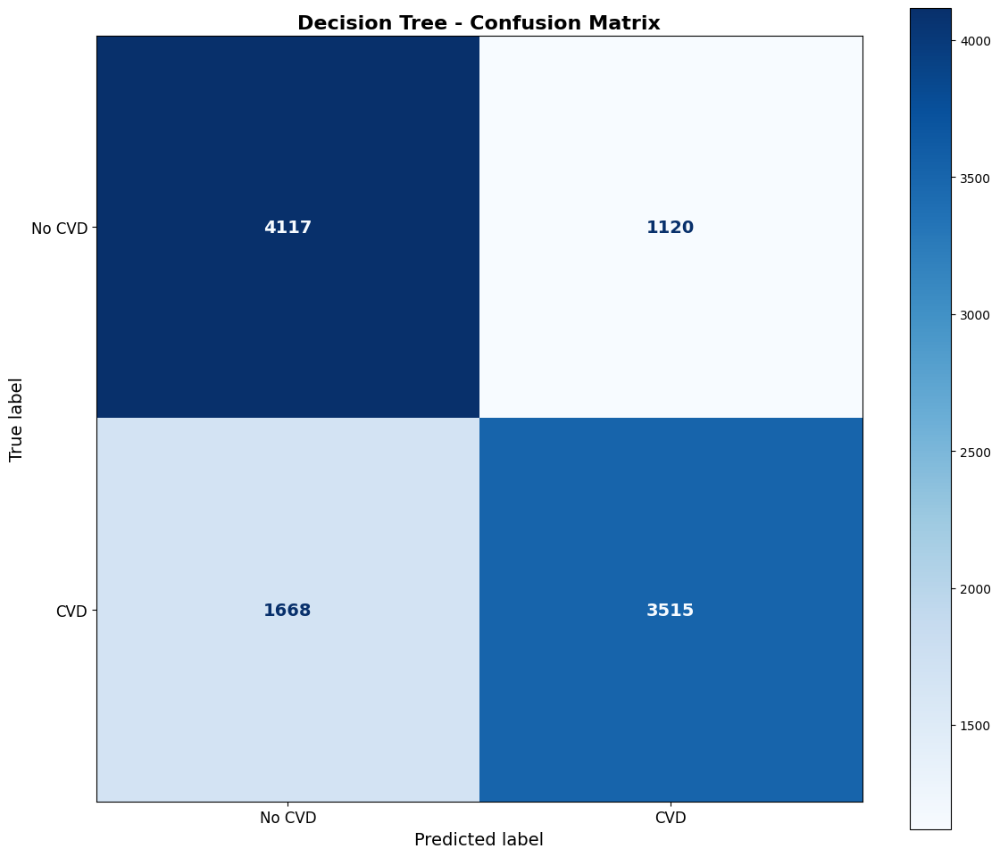


--- ADDITIONAL METRICS ---
Accuracy:  0.7324
Precision: 0.7584
Recall:    0.6782
F1-Score:  0.7160
AUC-ROC:   0.7938


<Figure size 640x480 with 0 Axes>

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

print("="*70)
print("MODEL 2: DECISION TREE - DETAILED EVALUATION")
print("="*70)

# Predictions
y_pred_dt = dt_best.predict(X_val_scaled)
y_pred_proba_dt = dt_best.predict_proba(X_val_scaled)[:, 1]

# Classification Report
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_val, y_pred_dt, target_names=['No CVD', 'CVD']))

# Confusion Matrix
cm_dt = confusion_matrix(y_val, y_pred_dt)
print("\n--- CONFUSION MATRIX ---")
print(cm_dt)

# Plot Confusion Matrix with LARGER TEXT
fig, ax = plt.subplots(figsize=(12, 10))  # Bigger figure size

# Create confusion matrix display with custom text properties
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['No CVD', 'CVD'])
disp.plot(ax=ax, cmap='Blues', values_format='d')

# Increase text sizes
ax.title.set_size(16)           # Title size
ax.xaxis.label.set_size(14)      # X-axis label size
ax.yaxis.label.set_size(14)      # Y-axis label size

# Increase tick label sizes
ax.tick_params(axis='both', which='major', labelsize=12)

# Increase the numbers inside the matrix
for text in disp.text_.ravel():
    text.set_size(14)            # Numbers inside matrix
    text.set_weight('bold')      # Make numbers bold

plt.title('Decision Tree - Confusion Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Save the figure with high DPI
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/cm_dt_large.png',
            dpi=300, bbox_inches='tight', facecolor='white')

# Additional Metrics
print("\n--- ADDITIONAL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_dt):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_dt):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_dt):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred_dt):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_dt):.4f}")
print("="*70)


**RANDOM FOREST**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

print("="*70)
print("MODEL 3: RANDOM FOREST - TRAINING & EVALUATION")
print("="*70)

# --- TRAINING ---
start_time = time.time()
rf_params = {'n_estimators': [50, 100 , 150], 'max_depth': [5, 10, 15]}
rf = RandomForestClassifier(random_state=42)
rf_grid = GridSearchCV(rf, rf_params, cv=5, scoring='roc_auc')
rf_grid.fit(X_train_scaled, y_train)
rf_best = rf_grid.best_estimator_
train_time = time.time() - start_time

# Predictions
y_pred_rf = rf_best.predict(X_val_scaled)
y_pred_proba_rf = rf_best.predict_proba(X_val_scaled)[:, 1]

# Store results
results['Model'].append('Random Forest')
results['Accuracy'].append(accuracy_score(y_val, y_pred_rf))
results['Precision'].append(precision_score(y_val, y_pred_rf))
results['Recall'].append(recall_score(y_val, y_pred_rf))
results['F1-Score'].append(f1_score(y_val, y_pred_rf))
results['AUC-ROC'].append(roc_auc_score(y_val, y_pred_proba_rf))
results['Training Time'].append(train_time)

print(f"Best parameters: {rf_grid.best_params_}")
print(f"Training Time: {train_time:.2f} seconds")

MODEL 3: RANDOM FOREST - TRAINING & EVALUATION
Best parameters: {'max_depth': 10, 'n_estimators': 150}
Training Time: 201.21 seconds


MODEL 3: RANDOM FOREST - DETAILED EVALUATION

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      No CVD       0.71      0.79      0.75      5237
         CVD       0.77      0.68      0.72      5183

    accuracy                           0.74     10420
   macro avg       0.74      0.74      0.74     10420
weighted avg       0.74      0.74      0.74     10420


--- CONFUSION MATRIX ---
[[4157 1080]
 [1663 3520]]


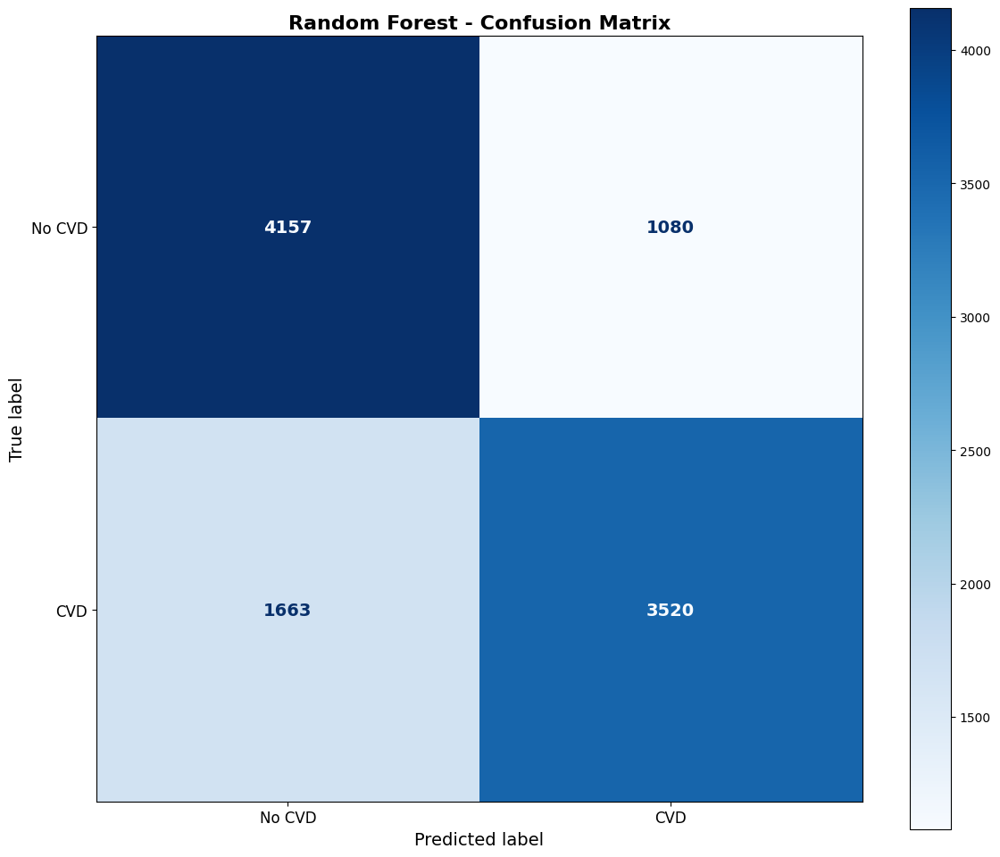


--- ADDITIONAL METRICS ---
Accuracy:  0.7368
Precision: 0.7652
Recall:    0.6791
F1-Score:  0.7196
AUC-ROC:   0.8052


<Figure size 640x480 with 0 Axes>

In [ ]:
print("="*70)
print("MODEL 3: RANDOM FOREST - DETAILED EVALUATION")
print("="*70)

# Predictions
y_pred_rf = rf_best.predict(X_val_scaled)
y_pred_proba_rf = rf_best.predict_proba(X_val_scaled)[:, 1]

# Classification Report
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_val, y_pred_rf, target_names=['No CVD', 'CVD']))

# Confusion Matrix
cm_rf = confusion_matrix(y_val, y_pred_rf)
print("\n--- CONFUSION MATRIX ---")
print(cm_rf)

# Plot Confusion Matrix with LARGER TEXT
fig, ax = plt.subplots(figsize=(12, 10))  # Bigger figure size

# Create confusion matrix display with custom text properties
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No CVD', 'CVD'])
disp.plot(ax=ax, cmap='Blues', values_format='d')

# Increase text sizes
ax.title.set_size(16)           # Title size
ax.xaxis.label.set_size(14)      # X-axis label size
ax.yaxis.label.set_size(14)      # Y-axis label size

# Increase tick label sizes
ax.tick_params(axis='both', which='major', labelsize=12)

# Increase the numbers inside the matrix
for text in disp.text_.ravel():
    text.set_size(14)            # Numbers inside matrix
    text.set_weight('bold')      # Make numbers bold

plt.title('Random Forest - Confusion Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Save the figure with high DPI
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/cm_rf_large.png',
            dpi=300, bbox_inches='tight', facecolor='white')

# Additional Metrics
print("\n--- ADDITIONAL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_rf):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_rf):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred_rf):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_rf):.4f}")
print("="*70)

**XGBOOST**

In [ ]:
import xgboost as xgb

print("="*70)
print("MODEL 4: XGBOOST - TRAINING & EVALUATION")
print("="*70)

# --- TRAINING ---
start_time = time.time()
xgb_params = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1]
}
xgb_model = xgb.XGBClassifier(random_state=42, eval_metric='logloss')
xgb_grid = GridSearchCV(xgb_model, xgb_params, cv=5, scoring='roc_auc')
xgb_grid.fit(X_train_scaled, y_train)
xgb_best = xgb_grid.best_estimator_
train_time = time.time() - start_time

# Predictions
y_pred_xgb = xgb_best.predict(X_val_scaled)
y_pred_proba_xgb = xgb_best.predict_proba(X_val_scaled)[:, 1]

# Store results
results['Model'].append('XGBoost')
results['Accuracy'].append(accuracy_score(y_val, y_pred_xgb))
results['Precision'].append(precision_score(y_val, y_pred_xgb))
results['Recall'].append(recall_score(y_val, y_pred_xgb))
results['F1-Score'].append(f1_score(y_val, y_pred_xgb))
results['AUC-ROC'].append(roc_auc_score(y_val, y_pred_proba_xgb))
results['Training Time'].append(train_time)

print(f"Best parameters: {xgb_grid.best_params_}")
print(f"Training Time: {train_time:.2f} seconds")

MODEL 4: XGBOOST - TRAINING & EVALUATION
Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
Training Time: 32.94 seconds


MODEL 4: XGBOOST - DETAILED EVALUATION

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      No CVD       0.72      0.79      0.75      5237
         CVD       0.76      0.68      0.72      5183

    accuracy                           0.74     10420
   macro avg       0.74      0.74      0.74     10420
weighted avg       0.74      0.74      0.74     10420


--- CONFUSION MATRIX ---
[[4137 1100]
 [1647 3536]]


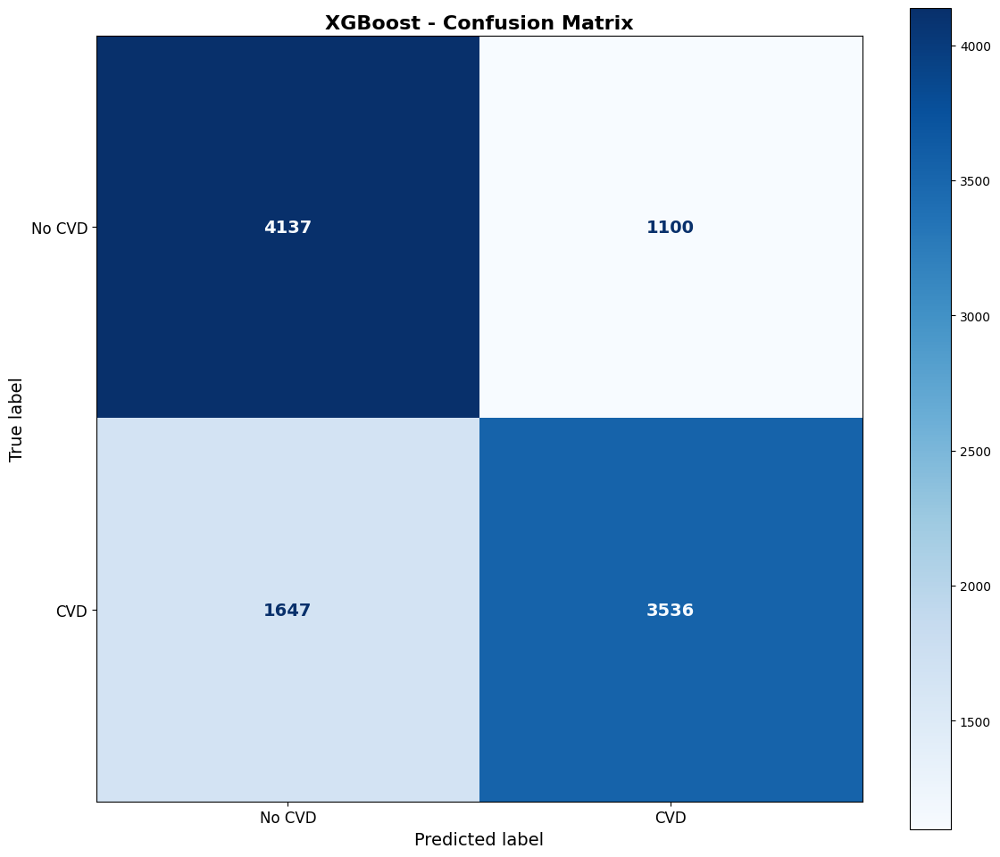


--- ADDITIONAL METRICS ---
Accuracy:  0.7364
Precision: 0.7627
Recall:    0.6822
F1-Score:  0.7202
AUC-ROC:   0.8057


<Figure size 640x480 with 0 Axes>

In [ ]:
print("="*70)
print("MODEL 4: XGBOOST - DETAILED EVALUATION")
print("="*70)

# Predictions
y_pred_xgb = xgb_best.predict(X_val_scaled)
y_pred_proba_xgb = xgb_best.predict_proba(X_val_scaled)[:, 1]

# Classification Report
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_val, y_pred_xgb, target_names=['No CVD', 'CVD']))

# Confusion Matrix
cm_xgb = confusion_matrix(y_val, y_pred_xgb)
print("\n--- CONFUSION MATRIX ---")
print(cm_xgb)

# Plot Confusion Matrix with LARGER TEXT
fig, ax = plt.subplots(figsize=(12, 10))  # Bigger figure size

# Create confusion matrix display with custom text properties
disp = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=['No CVD', 'CVD'])
disp.plot(ax=ax, cmap='Blues', values_format='d')

# Increase text sizes
ax.title.set_size(16)           # Title size
ax.xaxis.label.set_size(14)      # X-axis label size
ax.yaxis.label.set_size(14)      # Y-axis label size

# Increase tick label sizes
ax.tick_params(axis='both', which='major', labelsize=12)

# Increase the numbers inside the matrix
for text in disp.text_.ravel():
    text.set_size(14)            # Numbers inside matrix
    text.set_weight('bold')      # Make numbers bold

plt.title('XGBoost - Confusion Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Save the figure with high DPI
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/cm_xgb_large.png',
            dpi=300, bbox_inches='tight', facecolor='white')

# Additional Metrics
print("\n--- ADDITIONAL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_xgb):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_xgb):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_xgb):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred_xgb):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_xgb):.4f}")
print("="*70)

**LIGHTGBM**

In [ ]:
import lightgbm as lgb

print("="*70)
print("MODEL 5: LIGHTGBM - TRAINING & EVALUATION")
print("="*70)

# --- TRAINING ---
start_time = time.time()
lgb_params = {
    'n_estimators': [50, 100 , 120],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1]
}
lgb_model = lgb.LGBMClassifier(random_state=42, verbose=-1)
lgb_grid = GridSearchCV(lgb_model, lgb_params, cv=5, scoring='roc_auc')
lgb_grid.fit(X_train_scaled, y_train)
lgb_best = lgb_grid.best_estimator_
train_time = time.time() - start_time

# Predictions
y_pred_lgb = lgb_best.predict(X_val_scaled)
y_pred_proba_lgb = lgb_best.predict_proba(X_val_scaled)[:, 1]

# Store results
results['Model'].append('LightGBM')
results['Accuracy'].append(accuracy_score(y_val, y_pred_lgb))
results['Precision'].append(precision_score(y_val, y_pred_lgb))
results['Recall'].append(recall_score(y_val, y_pred_lgb))
results['F1-Score'].append(f1_score(y_val, y_pred_lgb))
results['AUC-ROC'].append(roc_auc_score(y_val, y_pred_proba_lgb))
results['Training Time'].append(train_time)

print(f"Best parameters: {lgb_grid.best_params_}")
print(f"Training Time: {train_time:.2f} seconds")


MODEL 5: LIGHTGBM - TRAINING & EVALUATION
Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 120}
Training Time: 57.03 seconds


MODEL 5: LIGHTGBM - DETAILED EVALUATION

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      No CVD       0.72      0.79      0.75      5237
         CVD       0.76      0.68      0.72      5183

    accuracy                           0.74     10420
   macro avg       0.74      0.74      0.74     10420
weighted avg       0.74      0.74      0.74     10420


--- CONFUSION MATRIX ---
[[4134 1103]
 [1645 3538]]


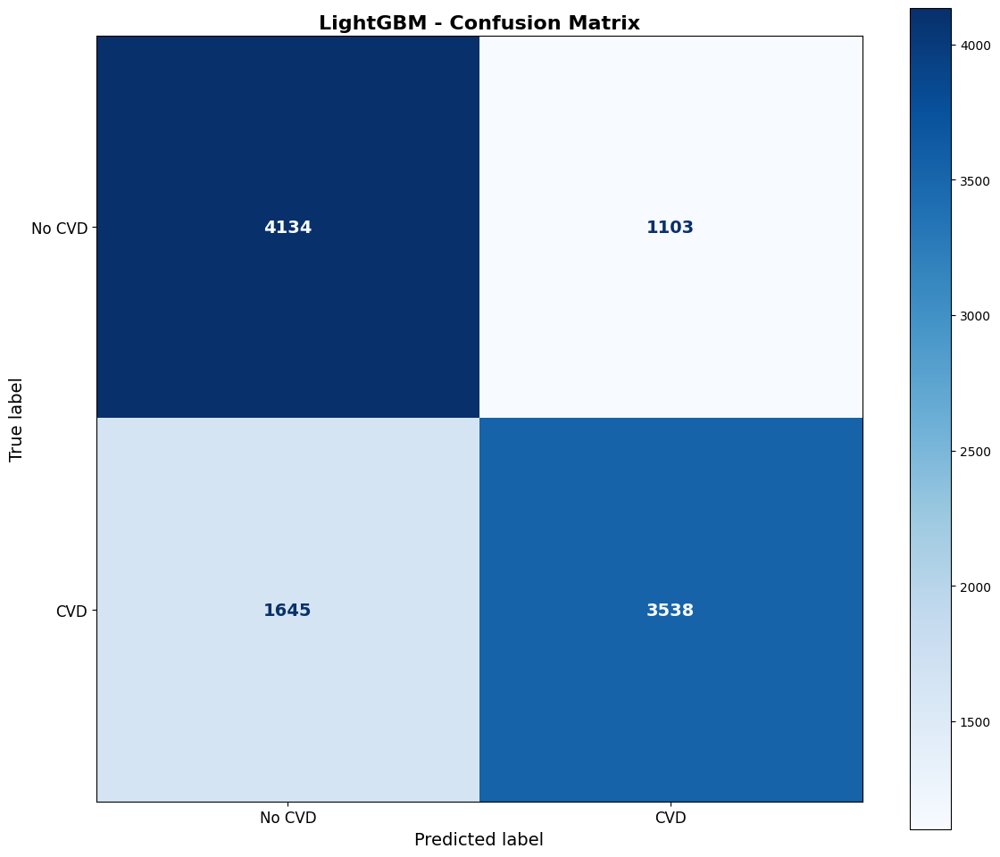


--- ADDITIONAL METRICS ---
Accuracy:  0.7363
Precision: 0.7623
Recall:    0.6826
F1-Score:  0.7203
AUC-ROC:   0.8061


<Figure size 640x480 with 0 Axes>

In [ ]:
print("="*70)
print("MODEL 5: LIGHTGBM - DETAILED EVALUATION")
print("="*70)

# Predictions
y_pred_lgb = lgb_best.predict(X_val_scaled)
y_pred_proba_lgb = lgb_best.predict_proba(X_val_scaled)[:, 1]

# Classification Report
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_val, y_pred_lgb, target_names=['No CVD', 'CVD']))

# Confusion Matrix
cm_lgb = confusion_matrix(y_val, y_pred_lgb)
print("\n--- CONFUSION MATRIX ---")
print(cm_lgb)

# Plot Confusion Matrix with LARGER TEXT
fig, ax = plt.subplots(figsize=(12, 10))  # Bigger figure size

# Create confusion matrix display with custom text properties
disp = ConfusionMatrixDisplay(confusion_matrix=cm_lgb, display_labels=['No CVD', 'CVD'])
disp.plot(ax=ax, cmap='Blues', values_format='d')

# Increase text sizes
ax.title.set_size(16)           # Title size
ax.xaxis.label.set_size(14)      # X-axis label size
ax.yaxis.label.set_size(14)      # Y-axis label size

# Increase tick label sizes
ax.tick_params(axis='both', which='major', labelsize=12)

# Increase the numbers inside the matrix
for text in disp.text_.ravel():
    text.set_size(14)            # Numbers inside matrix
    text.set_weight('bold')      # Make numbers bold

plt.title('LightGBM - Confusion Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Save the figure with high DPI
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/cm_lgb_large.png',
            dpi=300, bbox_inches='tight', facecolor='white')

# Additional Metrics
print("\n--- ADDITIONAL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_lgb):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_lgb):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_lgb):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred_lgb):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_lgb):.4f}")
print("="*70)


**NEURAL NETWORK (MLP) - ULTRA FAST**

In [ ]:
from sklearn.neural_network import MLPClassifier

print("="*70)
print("MODEL 6: NEURAL NETWORK (MLP) - TRAINING & EVALUATION")
print("="*70)

# --- TRAINING (Ultra Fast Version) ---
start_time = time.time()
mlp = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation='relu',
    alpha=0.0001,
    max_iter=300,
    random_state=42
)
mlp.fit(X_train_scaled, y_train)
train_time = time.time() - start_time

# Predictions
y_pred_mlp = mlp.predict(X_val_scaled)
y_pred_proba_mlp = mlp.predict_proba(X_val_scaled)[:, 1]

# Store results
results['Model'].append('Neural Network')
results['Accuracy'].append(accuracy_score(y_val, y_pred_mlp))
results['Precision'].append(precision_score(y_val, y_pred_mlp))
results['Recall'].append(recall_score(y_val, y_pred_mlp))
results['F1-Score'].append(f1_score(y_val, y_pred_mlp))
results['AUC-ROC'].append(roc_auc_score(y_val, y_pred_proba_mlp))
results['Training Time'].append(train_time)

print(f"Training Time: {train_time:.2f} seconds")

MODEL 6: NEURAL NETWORK (MLP) - TRAINING & EVALUATION
Training Time: 16.42 seconds


MODEL 6: NEURAL NETWORK - DETAILED EVALUATION

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      No CVD       0.73      0.76      0.74      5237
         CVD       0.75      0.71      0.73      5183

    accuracy                           0.74     10420
   macro avg       0.74      0.74      0.74     10420
weighted avg       0.74      0.74      0.74     10420


--- CONFUSION MATRIX ---
[[3985 1252]
 [1483 3700]]


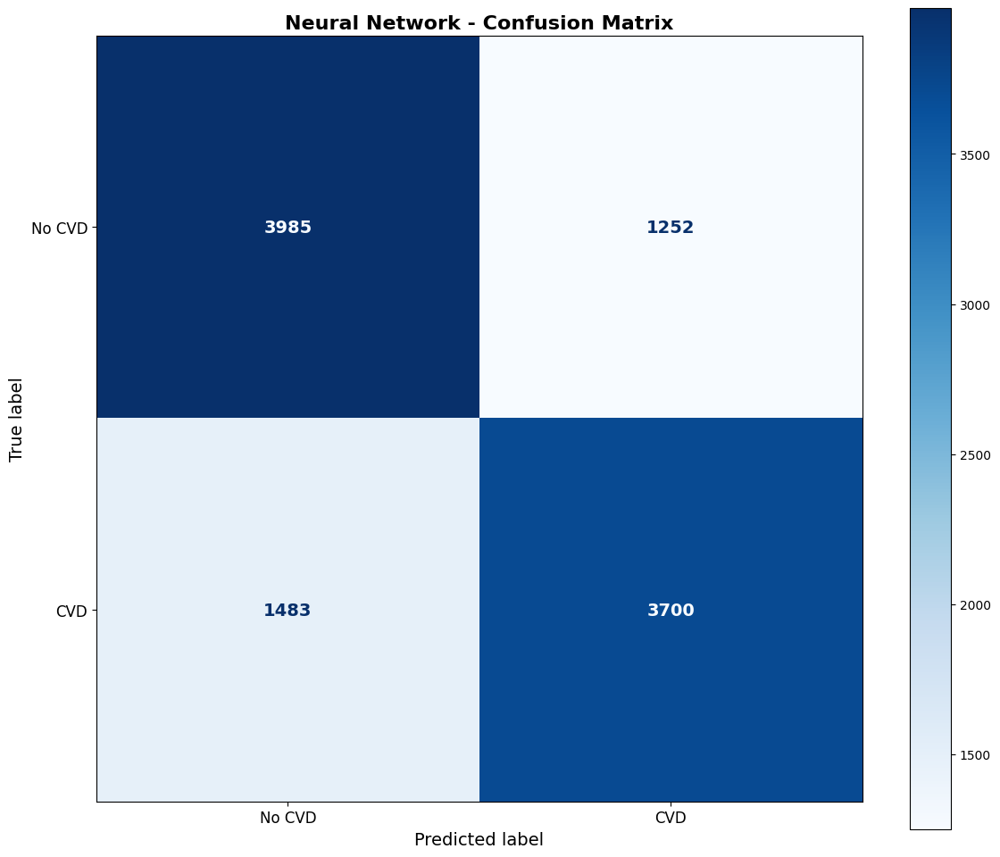


--- ADDITIONAL METRICS ---
Accuracy:  0.7375
Precision: 0.7472
Recall:    0.7139
F1-Score:  0.7301
AUC-ROC:   0.8030


<Figure size 640x480 with 0 Axes>

In [ ]:
print("="*70)
print("MODEL 6: NEURAL NETWORK - DETAILED EVALUATION")
print("="*70)

# Predictions
y_pred_mlp = mlp.predict(X_val_scaled)
y_pred_proba_mlp = mlp.predict_proba(X_val_scaled)[:, 1]

# Classification Report
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_val, y_pred_mlp, target_names=['No CVD', 'CVD']))

# Confusion Matrix
cm_mlp = confusion_matrix(y_val, y_pred_mlp)
print("\n--- CONFUSION MATRIX ---")
print(cm_mlp)

# Plot Confusion Matrix with LARGER TEXT
fig, ax = plt.subplots(figsize=(12, 10))  # Bigger figure size

# Create confusion matrix display with custom text properties
disp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=['No CVD', 'CVD'])
disp.plot(ax=ax, cmap='Blues', values_format='d')

# Increase text sizes
ax.title.set_size(16)           # Title size
ax.xaxis.label.set_size(14)      # X-axis label size
ax.yaxis.label.set_size(14)      # Y-axis label size

# Increase tick label sizes
ax.tick_params(axis='both', which='major', labelsize=12)

# Increase the numbers inside the matrix
for text in disp.text_.ravel():
    text.set_size(14)            # Numbers inside matrix
    text.set_weight('bold')      # Make numbers bold

plt.title('Neural Network - Confusion Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Save the figure with high DPI
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/cm_mlp_large.png',
            dpi=300, bbox_inches='tight', facecolor='white')

# Additional Metrics
print("\n--- ADDITIONAL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_mlp):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_mlp):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_mlp):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred_mlp):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_mlp):.4f}")
print("="*70)


** K-NEAREST NEIGHBORS**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

print("="*70)
print("MODEL 7: K-NEAREST NEIGHBORS - TRAINING & EVALUATION")
print("="*70)

# --- TRAINING ---
start_time = time.time()
knn_params = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance']
}
knn = KNeighborsClassifier()
knn_grid = GridSearchCV(knn, knn_params, cv=5, scoring='roc_auc')
knn_grid.fit(X_train_scaled, y_train)
knn_best = knn_grid.best_estimator_
train_time = time.time() - start_time

# Predictions
y_pred_knn = knn_best.predict(X_val_scaled)
y_pred_proba_knn = knn_best.predict_proba(X_val_scaled)[:, 1]

# Store results
results['Model'].append('K-Nearest Neighbors')
results['Accuracy'].append(accuracy_score(y_val, y_pred_knn))
results['Precision'].append(precision_score(y_val, y_pred_knn))
results['Recall'].append(recall_score(y_val, y_pred_knn))
results['F1-Score'].append(f1_score(y_val, y_pred_knn))
results['AUC-ROC'].append(roc_auc_score(y_val, y_pred_proba_knn))
results['Training Time'].append(train_time)

print(f"Best parameters: {knn_grid.best_params_}")
print(f"Training Time: {train_time:.2f} seconds")

MODEL 7: K-NEAREST NEIGHBORS - TRAINING & EVALUATION
Best parameters: {'n_neighbors': 9, 'weights': 'uniform'}
Training Time: 97.16 seconds


MODEL 7: K-NEAREST NEIGHBORS - DETAILED EVALUATION

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      No CVD       0.71      0.74      0.72      5237
         CVD       0.72      0.70      0.71      5183

    accuracy                           0.72     10420
   macro avg       0.72      0.72      0.72     10420
weighted avg       0.72      0.72      0.72     10420


--- CONFUSION MATRIX ---
[[3859 1378]
 [1576 3607]]


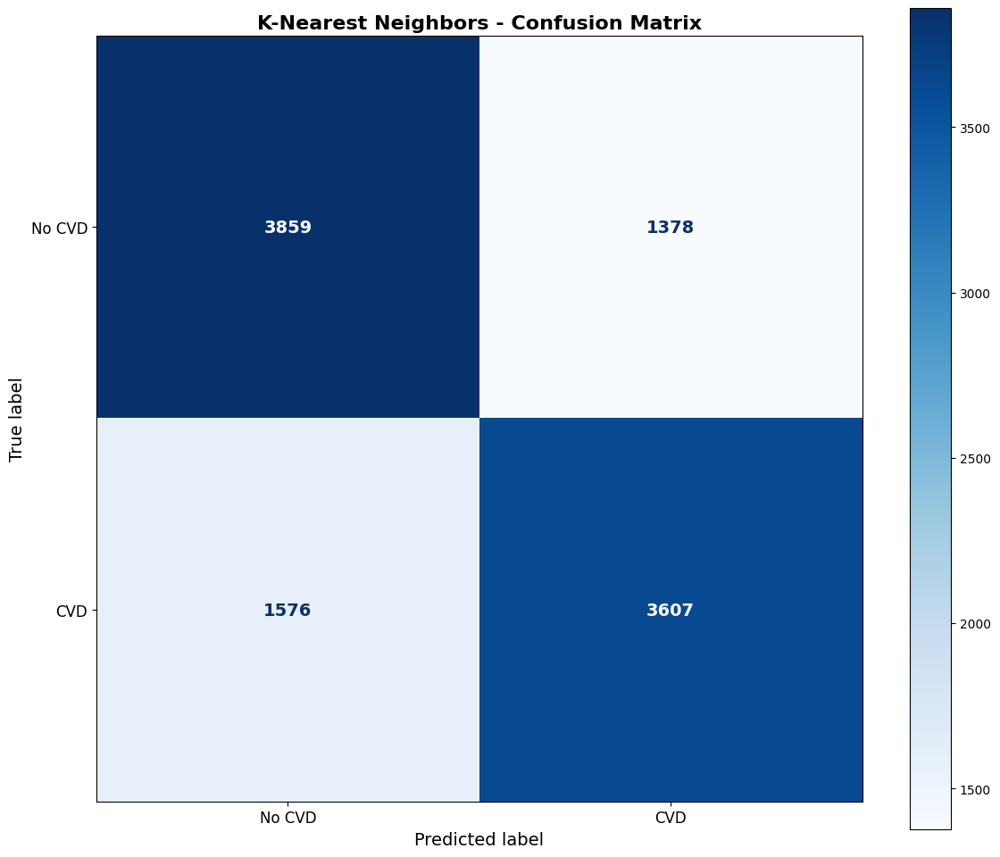


--- ADDITIONAL METRICS ---
Accuracy:  0.7165
Precision: 0.7236
Recall:    0.6959
F1-Score:  0.7095
AUC-ROC:   0.7706


<Figure size 640x480 with 0 Axes>

In [ ]:
print("="*70)
print("MODEL 7: K-NEAREST NEIGHBORS - DETAILED EVALUATION")
print("="*70)

# Predictions
y_pred_knn = knn_best.predict(X_val_scaled)
y_pred_proba_knn = knn_best.predict_proba(X_val_scaled)[:, 1]

# Classification Report
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_val, y_pred_knn, target_names=['No CVD', 'CVD']))

# Confusion Matrix
cm_knn = confusion_matrix(y_val, y_pred_knn)
print("\n--- CONFUSION MATRIX ---")
print(cm_knn)

# Plot Confusion Matrix with LARGER TEXT
fig, ax = plt.subplots(figsize=(12, 10))  # Bigger figure size

# Create confusion matrix display with custom text properties
disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=['No CVD', 'CVD'])
disp.plot(ax=ax, cmap='Blues', values_format='d')

# Increase text sizes
ax.title.set_size(16)           # Title size
ax.xaxis.label.set_size(14)      # X-axis label size
ax.yaxis.label.set_size(14)      # Y-axis label size

# Increase tick label sizes
ax.tick_params(axis='both', which='major', labelsize=12)

# Increase the numbers inside the matrix
for text in disp.text_.ravel():
    text.set_size(14)            # Numbers inside matrix
    text.set_weight('bold')      # Make numbers bold

plt.title('K-Nearest Neighbors - Confusion Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Save the figure with high DPI
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/cm_knn_large.png',
            dpi=300, bbox_inches='tight', facecolor='white')

# Additional Metrics
print("\n--- ADDITIONAL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_knn):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_knn):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_knn):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred_knn):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_knn):.4f}")
print("="*70)

SUPPORT VECTOR MACHINE - OPTIMIZED

In [ ]:
from sklearn.svm import SVC

print("="*70)
print("MODEL 8: SUPPORT VECTOR MACHINE - TRAINING & EVALUATION")
print("="*70)

# --- TRAINING (Ultra Fast Version) ---
start_time = time.time()
svm = SVC(
    C=1.0,
    kernel='rbf',
    gamma='scale',
    probability=False,
    random_state=42
)
svm.fit(X_train_scaled, y_train)
train_time = time.time() - start_time

# Predictions
y_pred_svm = svm.predict(X_val_scaled)
y_pred_proba_svm = svm.decision_function(X_val_scaled)

# Store results
results['Model'].append('SVM')
results['Accuracy'].append(accuracy_score(y_val, y_pred_svm))
results['Precision'].append(precision_score(y_val, y_pred_svm))
results['Recall'].append(recall_score(y_val, y_pred_svm))
results['F1-Score'].append(f1_score(y_val, y_pred_svm))
results['AUC-ROC'].append(roc_auc_score(y_val, y_pred_proba_svm))
results['Training Time'].append(train_time)

print(f"Training Time: {train_time:.2f} seconds")


MODEL 8: SUPPORT VECTOR MACHINE - TRAINING & EVALUATION
Training Time: 180.57 seconds


MODEL 8: SVM - DETAILED EVALUATION

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      No CVD       0.71      0.80      0.75      5237
         CVD       0.77      0.67      0.72      5183

    accuracy                           0.74     10420
   macro avg       0.74      0.74      0.74     10420
weighted avg       0.74      0.74      0.74     10420


--- CONFUSION MATRIX ---
[[4187 1050]
 [1696 3487]]


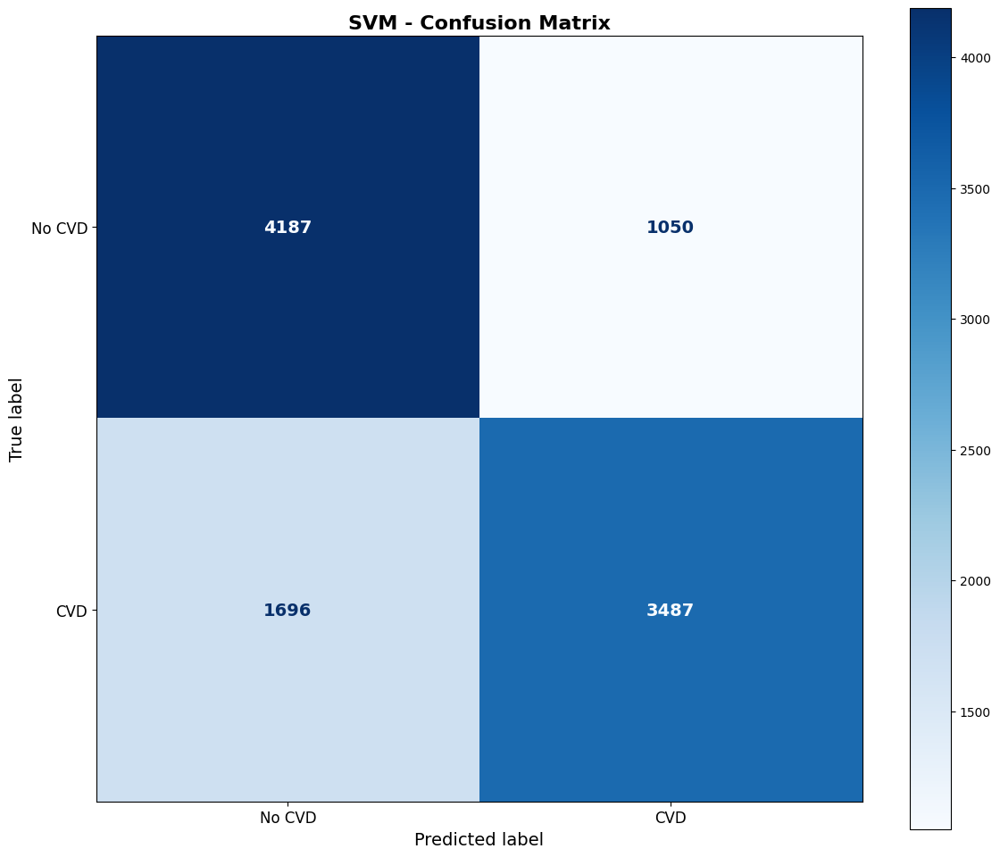


--- ADDITIONAL METRICS ---
Accuracy:  0.7365
Precision: 0.7686
Recall:    0.6728
F1-Score:  0.7175
AUC-ROC:   0.7944


<Figure size 640x480 with 0 Axes>

In [ ]:
print("="*70)
print("MODEL 8: SVM - DETAILED EVALUATION")
print("="*70)

# Predictions
y_pred_svm = svm.predict(X_val_scaled)
y_pred_proba_svm = svm.decision_function(X_val_scaled)

# Classification Report
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_val, y_pred_svm, target_names=['No CVD', 'CVD']))

# Confusion Matrix
cm_svm = confusion_matrix(y_val, y_pred_svm)
print("\n--- CONFUSION MATRIX ---")
print(cm_svm)

# Plot Confusion Matrix with LARGER TEXT
fig, ax = plt.subplots(figsize=(12, 10))  # Bigger figure size

# Create confusion matrix display with custom text properties
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=['No CVD', 'CVD'])
disp.plot(ax=ax, cmap='Blues', values_format='d')

# Increase text sizes
ax.title.set_size(16)           # Title size
ax.xaxis.label.set_size(14)      # X-axis label size
ax.yaxis.label.set_size(14)      # Y-axis label size

# Increase tick label sizes
ax.tick_params(axis='both', which='major', labelsize=12)

# Increase the numbers inside the matrix
for text in disp.text_.ravel():
    text.set_size(14)            # Numbers inside matrix
    text.set_weight('bold')      # Make numbers bold

plt.title('SVM - Confusion Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Save the figure with high DPI
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/cm_svm_large.png',
            dpi=300, bbox_inches='tight', facecolor='white')

# Additional Metrics
print("\n--- ADDITIONAL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_svm):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_svm):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_svm):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred_svm):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_svm):.4f}")
print("="*70)

**MODEL 9: CatBoost (Training)**

In [ ]:
# ============================================
# MODEL 9: CATBOOST - OPTIMIZED FOR MEDICAL DIAGNOSIS
# ============================================

print("="*70)
print("MODEL 9: CATBOOST - OPTIMIZED FOR MEDICAL DIAGNOSIS")
print("="*70)

# Install CatBoost
!pip install catboost -q

from catboost import CatBoostClassifier
import time
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Identify categorical features
categorical_features_indices = []
for i, feat in enumerate(all_features):
    if feat in ['gender', 'cholesterol', 'gluc', 'age_group_encoded']:
        categorical_features_indices.append(i)

print(f"Categorical feature indices: {categorical_features_indices}")

# --- TRAINING ---
start_time = time.time()

# FIXED: Removed od_wait since we're using early_stopping_rounds
catboost_model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.03,
    depth=8,
    l2_leaf_reg=5,
    border_count=255,
    loss_function='Logloss',
    eval_metric='Recall',  # Focus on recall for medical diagnosis
    random_seed=42,
    use_best_model=True,
    early_stopping_rounds=100,  # This controls early stopping
    verbose=100,
    cat_features=categorical_features_indices,
    auto_class_weights='Balanced',  # Automatically handle class imbalance
    bootstrap_type='Bernoulli',
    subsample=0.8
    # Removed: od_type='Iter', od_wait=100 (conflicts with early_stopping_rounds)
)

# Train with validation set
catboost_model.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    plot=False,
    verbose_eval=100
)

train_time = time.time() - start_time

# Predictions
y_pred_catboost = catboost_model.predict(X_val)
y_pred_proba_catboost = catboost_model.predict_proba(X_val)[:, 1]

# Store results
results['Model'].append('CatBoost (Medical Optimized)')
results['Accuracy'].append(accuracy_score(y_val, y_pred_catboost))
results['Precision'].append(precision_score(y_val, y_pred_catboost))
results['Recall'].append(recall_score(y_val, y_pred_catboost))
results['F1-Score'].append(f1_score(y_val, y_pred_catboost))
results['AUC-ROC'].append(roc_auc_score(y_val, y_pred_proba_catboost))
results['Training Time'].append(train_time)

print(f"Training Time: {train_time:.2f} seconds")
print(f"Best iteration: {catboost_model.get_best_iteration()}")

# Quick metrics
print("\n--- INITIAL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_catboost):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_catboost):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_catboost):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred_catboost):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_catboost):.4f}")

MODEL 9: CATBOOST - OPTIMIZED FOR MEDICAL DIAGNOSIS
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.8 MB/s eta 0:00:00


**MODEL 9: CATBOOST (MEDICAL OPTIMIZED) - DETAILED EVALUATION**


MODEL 9: CATBOOST (MEDICAL OPTIMIZED) - DETAILED EVALUATION

--- CLASSIFICATION REPORT (MEDICAL DIAGNOSIS FOCUS) ---
              precision    recall  f1-score   support

      No CVD       0.73      0.73      0.73      5237
         CVD       0.73      0.72      0.72      5183

    accuracy                           0.73     10420
   macro avg       0.73      0.73      0.73     10420
weighted avg       0.73      0.73      0.73     10420


--- CONFUSION MATRIX ---
[[3820 1417]
 [1440 3743]]


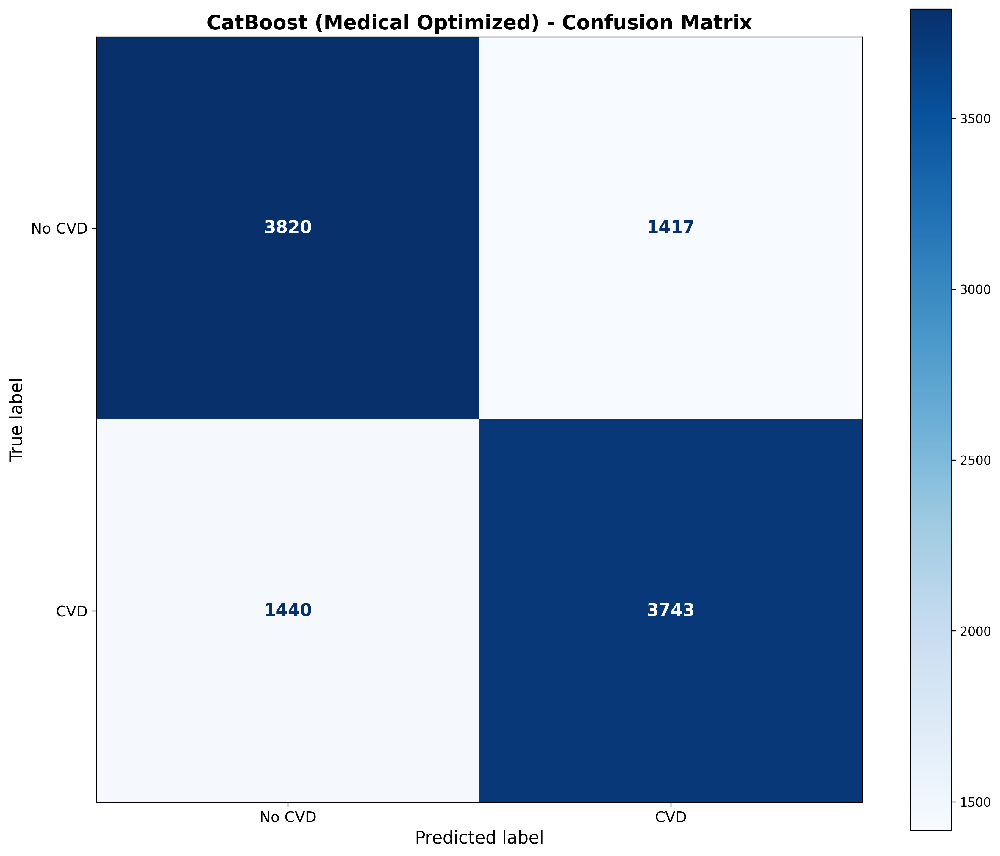

<Figure size 1920x1440 with 0 Axes>

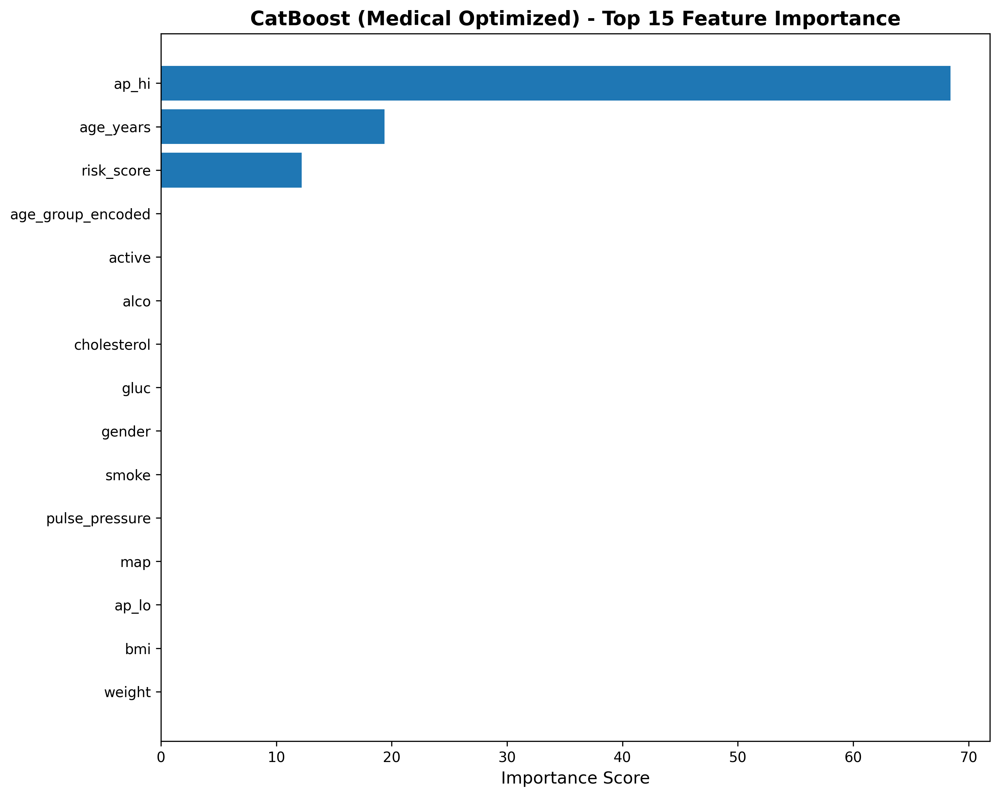


--- Available metrics in evals_result ---
Learn keys: dict_keys(['Recall', 'Logloss'])
Validation keys: dict_keys(['Recall', 'Logloss'])


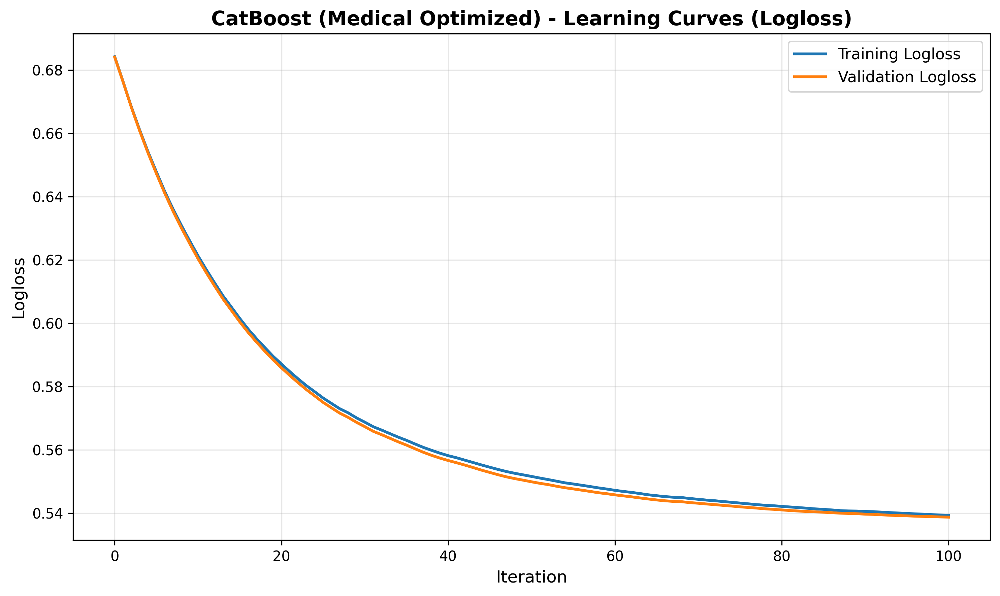


MEDICAL DIAGNOSIS METRICS SUMMARY
🔬 Model: CatBoost (Medical Optimized)
🎯 Primary Metric (Recall for disease detection): 0.7222
📊 Accuracy:  0.7258
⚖️ Precision: 0.7254
📈 F1-Score:  0.7238
🔄 AUC-ROC:   0.7886


In [ ]:
# ============================================
# MODEL 9: CATBOOST (MEDICAL OPTIMIZED) - DETAILED EVALUATION
# ============================================

print("="*70)
print("MODEL 9: CATBOOST (MEDICAL OPTIMIZED) - DETAILED EVALUATION")
print("="*70)

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predictions (using model from Part 1)
y_pred_catboost = catboost_model.predict(X_val)
y_pred_proba_catboost = catboost_model.predict_proba(X_val)[:, 1]

# Classification Report
print("\n--- CLASSIFICATION REPORT (MEDICAL DIAGNOSIS FOCUS) ---")
print(classification_report(y_val, y_pred_catboost, target_names=['No CVD', 'CVD']))

# Confusion Matrix
cm_catboost = confusion_matrix(y_val, y_pred_catboost)
print("\n--- CONFUSION MATRIX ---")
print(cm_catboost)

# Plot Confusion Matrix with LARGER TEXT
fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(confusion_matrix=cm_catboost, display_labels=['No CVD', 'CVD'])
disp.plot(ax=ax, cmap='Blues', values_format='d')

# Increase text sizes
ax.title.set_size(16)
ax.xaxis.label.set_size(14)
ax.yaxis.label.set_size(14)
ax.tick_params(axis='both', which='major', labelsize=12)

for text in disp.text_.ravel():
    text.set_size(14)
    text.set_weight('bold')

plt.title('CatBoost (Medical Optimized) - Confusion Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Save the figure
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/cm_catboost_medical.png',
            dpi=300, bbox_inches='tight', facecolor='white')

# Feature Importance Plot
feature_importance = catboost_model.get_feature_importance()
feature_importance_df = pd.DataFrame({
    'feature': all_features,
    'importance': feature_importance
}).sort_values('importance', ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(feature_importance_df.tail(15)['feature'], feature_importance_df.tail(15)['importance'])
plt.xlabel('Importance Score', fontsize=12)
plt.title('CatBoost (Medical Optimized) - Top 15 Feature Importance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/catboost_features_medical.png',
            dpi=300, bbox_inches='tight')
plt.show()

# Learning Curves
print("\n--- Available metrics in evals_result ---")
evals_result = catboost_model.get_evals_result()
print("Learn keys:", evals_result['learn'].keys())
print("Validation keys:", evals_result['validation'].keys())

# Try to find the correct metric name
possible_metric_names = ['Logloss', 'AUC', 'Recall', 'accuracy', 'Accuracy']
learn_metric = None
val_metric = None

# Priority: Logloss first (always available), then Recall (our eval metric)
for metric in possible_metric_names:
    if metric in evals_result['learn']:
        learn_metric = metric
        break

if learn_metric:
    train_values = evals_result['learn'][learn_metric]
    val_values = evals_result['validation'][learn_metric]

    plt.figure(figsize=(10, 6))
    plt.plot(train_values, label=f'Training {learn_metric}', linewidth=2)
    plt.plot(val_values, label=f'Validation {learn_metric}', linewidth=2)
    plt.xlabel('Iteration', fontsize=12)
    plt.ylabel(learn_metric, fontsize=12)
    plt.title(f'CatBoost (Medical Optimized) - Learning Curves ({learn_metric})', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/catboost_learning_medical.png',
                dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("Could not find expected metric. Available metrics:", evals_result['learn'].keys())

# Additional Metrics - Focus on Medical Diagnosis Metrics
print("\n" + "="*70)
print("MEDICAL DIAGNOSIS METRICS SUMMARY")
print("="*70)
print(f"🔬 Model: CatBoost (Medical Optimized)")
print(f"🎯 Primary Metric (Recall for disease detection): {recall_score(y_val, y_pred_catboost):.4f}")
print(f"📊 Accuracy:  {accuracy_score(y_val, y_pred_catboost):.4f}")
print(f"⚖️ Precision: {precision_score(y_val, y_pred_catboost):.4f}")
print(f"📈 F1-Score:  {f1_score(y_val, y_pred_catboost):.4f}")
print(f"🔄 AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_catboost):.4f}")
print("="*70)

**MODEL 10: STACKING ENSEMBLE - PART 1 (Training)**

In [ ]:
# ============================================
# MODEL 10: STACKING ENSEMBLE - TRAINING
# ============================================

print("="*70)
print("MODEL 10: STACKING ENSEMBLE - TRAINING & EVALUATION")
print("="*70)

from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_val_score
import time

start_time = time.time()

# Use your best-performing models as base learners
base_learners = [
    ('xgb', XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        random_state=42,
        use_label_encoder=False,
        eval_metric='logloss',
        n_jobs=-1
    )),
    ('lgbm', LGBMClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        random_state=42,
        verbose=-1,
        n_jobs=-1
    )),
    ('rf', RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
]

# Meta-learner with balanced class weights for better precision/recall
meta_learner = LogisticRegression(
    C=1.0,
    class_weight='balanced',
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)

# Create stacking ensemble
stacking_model = StackingClassifier(
    estimators=base_learners,
    final_estimator=meta_learner,
    cv=5,
    stack_method='predict_proba',
    n_jobs=-1,
    passthrough=False
)

# Train the stacking ensemble
stacking_model.fit(X_train, y_train)

train_time = time.time() - start_time

# Predictions
y_pred_stacking = stacking_model.predict(X_val)
y_pred_proba_stacking = stacking_model.predict_proba(X_val)[:, 1]

# Store results
results['Model'].append('Stacking Ensemble')
results['Accuracy'].append(accuracy_score(y_val, y_pred_stacking))
results['Precision'].append(precision_score(y_val, y_pred_stacking))
results['Recall'].append(recall_score(y_val, y_pred_stacking))
results['F1-Score'].append(f1_score(y_val, y_pred_stacking))
results['AUC-ROC'].append(roc_auc_score(y_val, y_pred_proba_stacking))
results['Training Time'].append(train_time)

print(f"Training Time: {train_time:.2f} seconds")
print("\n--- INITIAL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_stacking):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_stacking):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_stacking):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred_stacking):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_stacking):.4f}")

MODEL 10: STACKING ENSEMBLE - TRAINING & EVALUATION
Training Time: 38.77 seconds

--- INITIAL METRICS ---
Accuracy:  0.7393
Precision: 0.7600
Recall:    0.6957
F1-Score:  0.7264
AUC-ROC:   0.8064


MODEL 10: STACKING ENSEMBLE - PART 2 (Detailed Evaluation)

MODEL 10: STACKING ENSEMBLE - DETAILED EVALUATION

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      No CVD       0.72      0.78      0.75      5237
         CVD       0.76      0.70      0.73      5183

    accuracy                           0.74     10420
   macro avg       0.74      0.74      0.74     10420
weighted avg       0.74      0.74      0.74     10420


--- CONFUSION MATRIX ---
[[4098 1139]
 [1577 3606]]


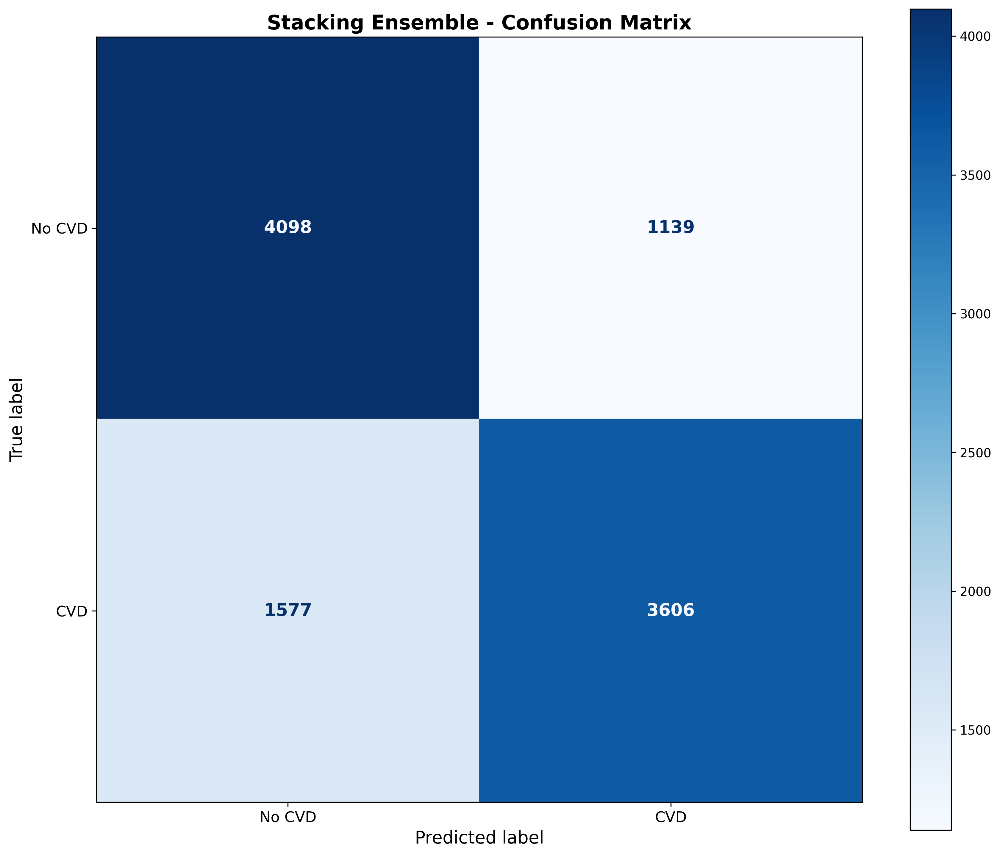


--- BASE LEARNER PERFORMANCE (5-fold CV) ---
xgb: AUC = 0.7982 (+/- 0.0029)
lgbm: AUC = 0.7981 (+/- 0.0029)
rf: AUC = 0.7974 (+/- 0.0028)

--- ADDITIONAL METRICS ---
Accuracy:  0.7393
Precision: 0.7600
Recall:    0.6957
F1-Score:  0.7264
AUC-ROC:   0.8064


In [ ]:
# ============================================
# MODEL 10: STACKING ENSEMBLE - DETAILED EVALUATION
# ============================================

print("="*70)
print("MODEL 10: STACKING ENSEMBLE - DETAILED EVALUATION")
print("="*70)

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predictions
y_pred_stacking = stacking_model.predict(X_val)
y_pred_proba_stacking = stacking_model.predict_proba(X_val)[:, 1]

# Classification Report
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_val, y_pred_stacking, target_names=['No CVD', 'CVD']))

# Confusion Matrix
cm_stacking = confusion_matrix(y_val, y_pred_stacking)
print("\n--- CONFUSION MATRIX ---")
print(cm_stacking)

# Plot Confusion Matrix with LARGER TEXT
fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(confusion_matrix=cm_stacking, display_labels=['No CVD', 'CVD'])
disp.plot(ax=ax, cmap='Blues', values_format='d')

# Increase text sizes
ax.title.set_size(16)
ax.xaxis.label.set_size(14)
ax.yaxis.label.set_size(14)
ax.tick_params(axis='both', which='major', labelsize=12)

for text in disp.text_.ravel():
    text.set_size(14)
    text.set_weight('bold')

plt.title('Stacking Ensemble - Confusion Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Save the figure
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/cm_stacking_large.png',
            dpi=300, bbox_inches='tight', facecolor='white')

# Show base learner performance
print("\n--- BASE LEARNER PERFORMANCE (5-fold CV) ---")
for name, model in base_learners:
    cv_scores = cross_val_score(model, X_train, y_train, cv=3, scoring='roc_auc')
    print(f"{name}: AUC = {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# Additional Metrics
print("\n--- ADDITIONAL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_stacking):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_stacking):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_stacking):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred_stacking):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_stacking):.4f}")
print("="*70)

# **MODEL 11:Extra Trees Classifier (Extremely Randomized Trees)**

In [ ]:
# ============================================
# MODEL 11: EXTRA TREES CLASSIFIER - TRAINING
# ============================================

print("="*70)
print("MODEL 11: EXTRA TREES CLASSIFIER - TRAINING & EVALUATION")
print("="*70)

from sklearn.ensemble import ExtraTreesClassifier
import time

# --- TRAINING ---
start_time = time.time()

et_model = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt',
    bootstrap=False,  # ExtraTrees doesn't use bootstrap by default
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'  # Handle class imbalance
)

et_model.fit(X_train, y_train)
train_time = time.time() - start_time

# Predictions
y_pred_et = et_model.predict(X_val)
y_pred_proba_et = et_model.predict_proba(X_val)[:, 1]

# Store results
results['Model'].append('Extra Trees')
results['Accuracy'].append(accuracy_score(y_val, y_pred_et))
results['Precision'].append(precision_score(y_val, y_pred_et))
results['Recall'].append(recall_score(y_val, y_pred_et))
results['F1-Score'].append(f1_score(y_val, y_pred_et))
results['AUC-ROC'].append(roc_auc_score(y_val, y_pred_proba_et))
results['Training Time'].append(train_time)

print(f"Training Time: {train_time:.2f} seconds")
print("\n--- INITIAL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_et):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_et):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_et):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred_et):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_et):.4f}")

MODEL 11: EXTRA TREES CLASSIFIER - TRAINING & EVALUATION
Training Time: 5.41 seconds

--- INITIAL METRICS ---
Accuracy:  0.7364
Precision: 0.7625
Recall:    0.6826
F1-Score:  0.7204
AUC-ROC:   0.8044


**MODEL 11: EXTRA TREES CLASSIFIER - PART 2 (Detailed Evaluation)**

MODEL 11: EXTRA TREES CLASSIFIER - DETAILED EVALUATION

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      No CVD       0.72      0.79      0.75      5237
         CVD       0.76      0.68      0.72      5183

    accuracy                           0.74     10420
   macro avg       0.74      0.74      0.74     10420
weighted avg       0.74      0.74      0.74     10420


--- CONFUSION MATRIX ---
[[4135 1102]
 [1645 3538]]


<Figure size 1920x1440 with 0 Axes>

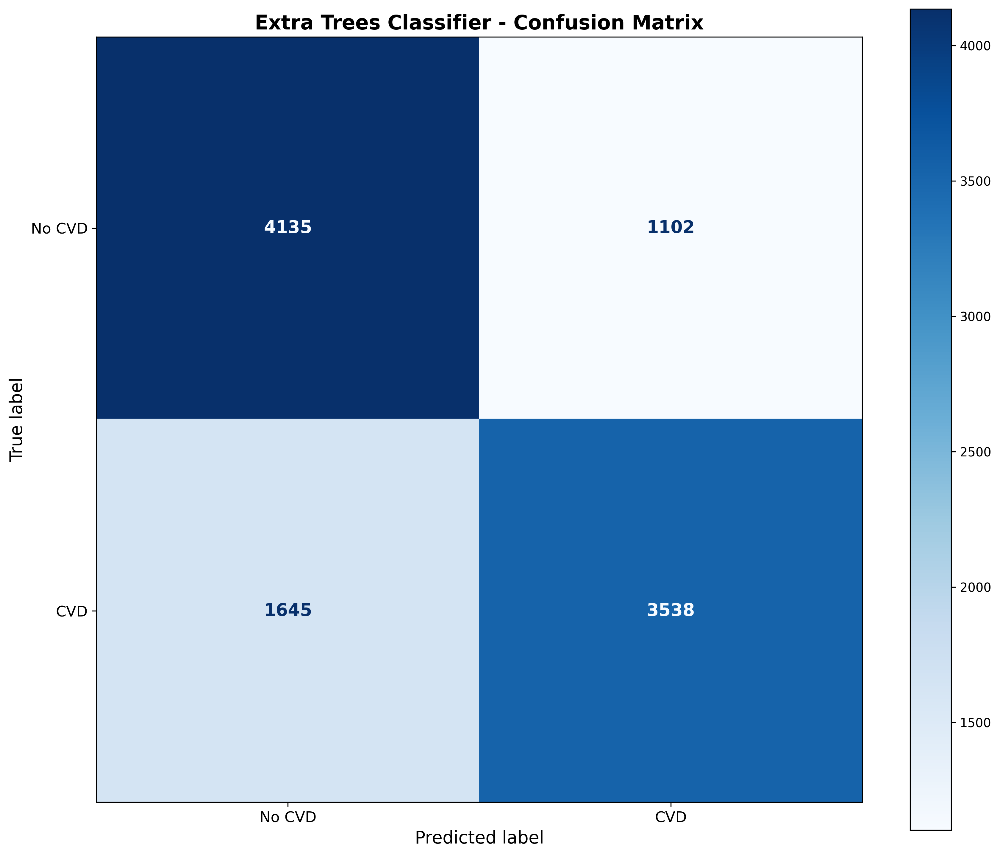

<Figure size 1920x1440 with 0 Axes>

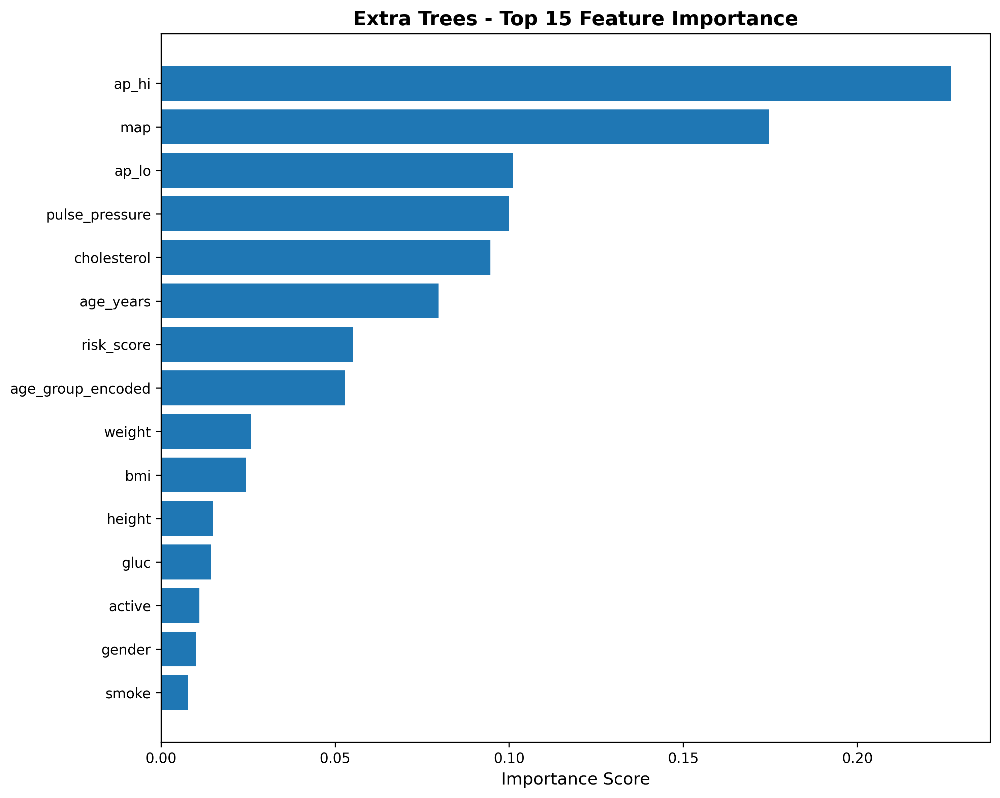


--- ADDITIONAL METRICS ---
Accuracy:  0.7364
Precision: 0.7625
Recall:    0.6826
F1-Score:  0.7204
AUC-ROC:   0.8044


In [ ]:
# ============================================
# MODEL 11: EXTRA TREES CLASSIFIER - DETAILED EVALUATION
# ============================================

print("="*70)
print("MODEL 11: EXTRA TREES CLASSIFIER - DETAILED EVALUATION")
print("="*70)

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Predictions (using model from Part 1)
y_pred_et = et_model.predict(X_val)
y_pred_proba_et = et_model.predict_proba(X_val)[:, 1]

# Classification Report
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_val, y_pred_et, target_names=['No CVD', 'CVD']))

# Confusion Matrix
cm_et = confusion_matrix(y_val, y_pred_et)
print("\n--- CONFUSION MATRIX ---")
print(cm_et)

# Plot Confusion Matrix with LARGER TEXT
fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(confusion_matrix=cm_et, display_labels=['No CVD', 'CVD'])
disp.plot(ax=ax, cmap='Blues', values_format='d')

# Increase text sizes
ax.title.set_size(16)
ax.xaxis.label.set_size(14)
ax.yaxis.label.set_size(14)
ax.tick_params(axis='both', which='major', labelsize=12)

for text in disp.text_.ravel():
    text.set_size(14)
    text.set_weight('bold')

plt.title('Extra Trees Classifier - Confusion Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Save the figure
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/cm_extratrees_large.png',
            dpi=300, bbox_inches='tight', facecolor='white')

# Feature Importance Plot
feature_importance = et_model.feature_importances_
feature_importance_df = pd.DataFrame({
    'feature': all_features,
    'importance': feature_importance
}).sort_values('importance', ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(feature_importance_df.tail(15)['feature'], feature_importance_df.tail(15)['importance'])
plt.xlabel('Importance Score', fontsize=12)
plt.title('Extra Trees - Top 15 Feature Importance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/extratrees_features_large.png',
            dpi=300, bbox_inches='tight')
plt.show()

# Additional Metrics
print("\n--- ADDITIONAL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_et):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_et):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_et):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred_et):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_et):.4f}")
print("="*70)

**MODEL 12:HistGradientBoostingClassifier (Microsoft's fast GBM)**

In [ ]:
# ============================================
# MODEL 12: HISTOGRAM GRADIENT BOOSTING - TRAINING
# ============================================

print("="*70)
print("MODEL 11: HISTOGRAM GRADIENT BOOSTING - TRAINING & EVALUATION")
print("="*70)

from sklearn.ensemble import HistGradientBoostingClassifier
import time

# --- TRAINING ---
start_time = time.time()

hgb_model = HistGradientBoostingClassifier(
    max_iter=200,
    max_depth=10,
    learning_rate=0.1,
    min_samples_leaf=20,
    l2_regularization=0.1,
    max_bins=255,
    categorical_features=categorical_features_indices,  # Your categorical indices
    random_state=42,
    class_weight='balanced'  # Handle imbalance
)

hgb_model.fit(X_train, y_train)
train_time = time.time() - start_time

# Predictions
y_pred_hgb = hgb_model.predict(X_val)
y_pred_proba_hgb = hgb_model.predict_proba(X_val)[:, 1]

# Store results
results['Model'].append('HistGradientBoost')
results['Accuracy'].append(accuracy_score(y_val, y_pred_hgb))
results['Precision'].append(precision_score(y_val, y_pred_hgb))
results['Recall'].append(recall_score(y_val, y_pred_hgb))
results['F1-Score'].append(f1_score(y_val, y_pred_hgb))
results['AUC-ROC'].append(roc_auc_score(y_val, y_pred_proba_hgb))
results['Training Time'].append(train_time)

print(f"Training Time: {train_time:.2f} seconds")
print("\n--- INITIAL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_hgb):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_hgb):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_hgb):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred_hgb):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_hgb):.4f}")

MODEL 11: HISTOGRAM GRADIENT BOOSTING - TRAINING & EVALUATION
Training Time: 0.81 seconds

--- INITIAL METRICS ---
Accuracy:  0.7369
Precision: 0.7551
Recall:    0.6973
F1-Score:  0.7250
AUC-ROC:   0.8058


**MODEL 12: HISTOGRAM GRADIENT BOOSTING - PART 2 (Detailed Evaluation)**

MODEL 12: HISTOGRAM GRADIENT BOOSTING - DETAILED EVALUATION

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      No CVD       0.72      0.78      0.75      5237
         CVD       0.76      0.70      0.73      5183

    accuracy                           0.74     10420
   macro avg       0.74      0.74      0.74     10420
weighted avg       0.74      0.74      0.74     10420


--- CONFUSION MATRIX ---
[[4065 1172]
 [1569 3614]]


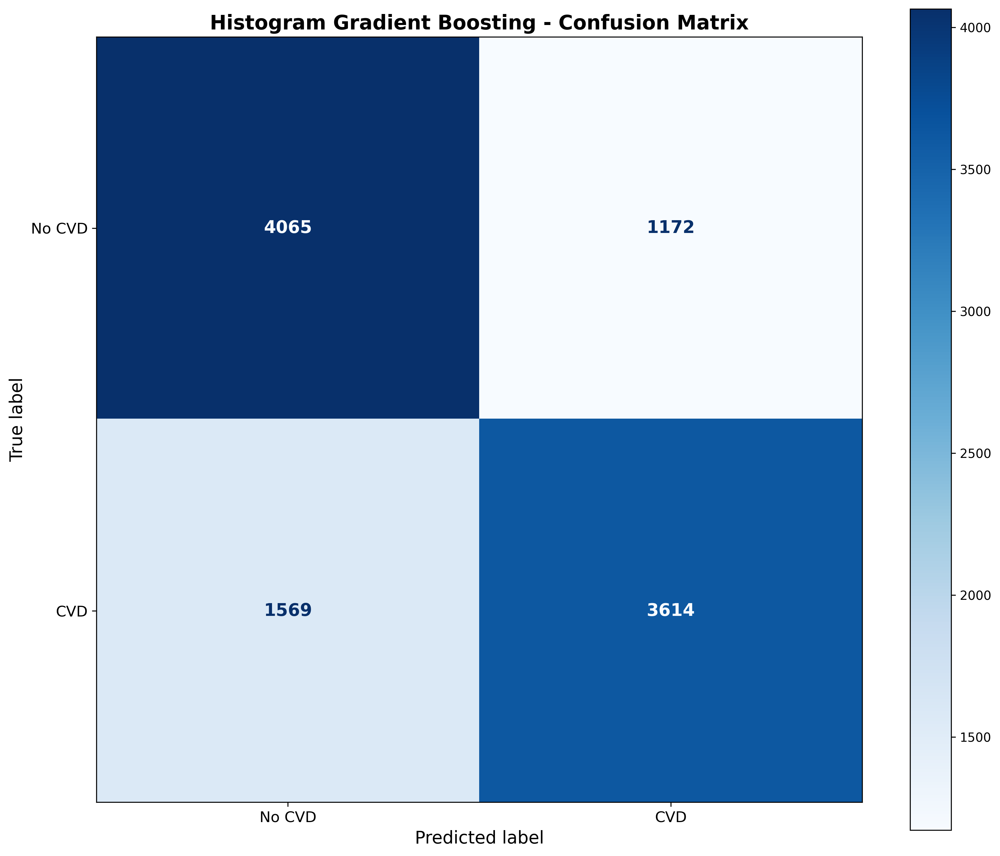


Feature importances not available for HistGradientBoosting model.

--- ADDITIONAL METRICS ---
Accuracy:  0.7369
Precision: 0.7551
Recall:    0.6973
F1-Score:  0.7250
AUC-ROC:   0.8058


In [ ]:
# ============================================
# MODEL 12: HISTOGRAM GRADIENT BOOSTING - DETAILED EVALUATION
# ============================================

print("="*70)
print("MODEL 12: HISTOGRAM GRADIENT BOOSTING - DETAILED EVALUATION")
print("="*70)

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Predictions (using model from Part 1)
y_pred_hgb = hgb_model.predict(X_val)
y_pred_proba_hgb = hgb_model.predict_proba(X_val)[:, 1]

# Classification Report
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_val, y_pred_hgb, target_names=['No CVD', 'CVD']))

# Confusion Matrix
cm_hgb = confusion_matrix(y_val, y_pred_hgb)
print("\n--- CONFUSION MATRIX ---")
print(cm_hgb)

# Plot Confusion Matrix with LARGER TEXT
fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(confusion_matrix=cm_hgb, display_labels=['No CVD', 'CVD'])
disp.plot(ax=ax, cmap='Blues', values_format='d')

# Increase text sizes
ax.title.set_size(16)
ax.xaxis.label.set_size(14)
ax.yaxis.label.set_size(14)
ax.tick_params(axis='both', which='major', labelsize=12)

for text in disp.text_.ravel():
    text.set_size(14)
    text.set_weight('bold')

plt.title('Histogram Gradient Boosting - Confusion Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Save the figure
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/cm_hgb_large.png',
            dpi=300, bbox_inches='tight', facecolor='white')

# Feature Importance Plot (if available)
if hasattr(hgb_model, 'feature_importances_'):
    feature_importance = hgb_model.feature_importances_
    feature_importance_df = pd.DataFrame({
        'feature': all_features,
        'importance': feature_importance
    }).sort_values('importance', ascending=True)

    plt.figure(figsize=(10, 8))
    plt.barh(feature_importance_df.tail(15)['feature'], feature_importance_df.tail(15)['importance'])
    plt.xlabel('Importance Score', fontsize=12)
    plt.title('HistGradientBoost - Top 15 Feature Importance', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/hgb_features_large.png',
                dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("\nFeature importances not available for HistGradientBoosting model.")

# Additional Metrics
print("\n--- ADDITIONAL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_hgb):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_hgb):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_hgb):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred_hgb):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_val, y_pred_proba_hgb):.4f}")
print("="*70)

In [ ]:

unique_models = []
unique_indices = []

# Get unique models in reverse order (keep last occurrence)
for i in range(len(results['Model'])-1, -1, -1):
    if results['Model'][i] not in unique_models:
        unique_models.append(results['Model'][i])
        unique_indices.append(i)

# Sort indices to maintain order
unique_indices = sorted(unique_indices)

# Create new results dictionary with unique models
clean_results = {
    'Model': [results['Model'][i] for i in unique_indices],
    'Accuracy': [results['Accuracy'][i] for i in unique_indices],
    'Precision': [results['Precision'][i] for i in unique_indices],
    'Recall': [results['Recall'][i] for i in unique_indices],
    'F1-Score': [results['F1-Score'][i] for i in unique_indices],
    'AUC-ROC': [results['AUC-ROC'][i] for i in unique_indices],
    'Training Time': [results['Training Time'][i] for i in unique_indices]
}

# Create DataFrame and sort
results_df = pd.DataFrame(clean_results)
results_df = results_df.sort_values('AUC-ROC', ascending=False).reset_index(drop=True)

# Print summary
print("="*70)
print("FINAL MODEL COMPARISON SUMMARY (8 Unique Models)")
print("="*70)
print(results_df.to_string(index=False))

# Find best model
best_model = results_df.iloc[0]['Model']
best_auc = results_df.iloc[0]['AUC-ROC']
print(f"\n🏆 BEST PERFORMING MODEL: {best_model} (AUC-ROC: {best_auc:.4f})")

# Top 3 models
print("\n📊 TOP 3 MODELS:")
for i in range(3):
    print(f"   {i+1}. {results_df.iloc[i]['Model']} - AUC-ROC: {results_df.iloc[i]['AUC-ROC']:.4f}")

# Optional: Save to CSV
results_df.to_csv('/content/drive/MyDrive/Colab Notebooks/DA/CVD/final_results.csv', index=False)
print("\n✅ Results saved to CSV!")


FINAL MODEL COMPARISON SUMMARY (8 Unique Models)
                       Model  Accuracy  Precision   Recall  F1-Score  AUC-ROC  Training Time
           Stacking Ensemble  0.739347   0.759958 0.695736  0.726430 0.806372      39.978965
                    LightGBM  0.736276   0.762336 0.682616  0.720277 0.806079      57.025805
           HistGradientBoost  0.736948   0.755119 0.697280  0.725048 0.805802       0.822175
                     XGBoost  0.736372   0.762726 0.682230  0.720236 0.805670      32.938663
               Random Forest  0.736756   0.765217 0.679143  0.719616 0.805202     201.214048
                 Extra Trees  0.736372   0.762500 0.682616  0.720350 0.804394       8.347441
              Neural Network  0.737524   0.747173 0.713872  0.730143 0.803015      16.418560
         Logistic Regression  0.731190   0.762914 0.666795  0.711624 0.797208      12.607574
                         SVM  0.736468   0.768570 0.672776  0.717490 0.794413     180.572213
               Decisi

GENERATING IEEE-OPTIMIZED GRAPHS

📊 HEATMAP DATA:
----------------------------------------
Values being plotted in heatmap:
Model      Stacking Ensemble  LightGBM  HistGradientBoost  XGBoost  Random Forest  Extra Trees  Neural Network  Logistic Regression     SVM  Decision Tree  CatBoost (Medical Optimized)  K-Nearest Neighbors
Accuracy              0.7393    0.7363             0.7369   0.7364         0.7368       0.7364          0.7375               0.7312  0.7365         0.7324                        0.7258               0.7165
Precision             0.7600    0.7623             0.7551   0.7627         0.7652       0.7625          0.7472               0.7629  0.7686         0.7584                        0.7254               0.7236
Recall                0.6957    0.6826             0.6973   0.6822         0.6791       0.6826          0.7139               0.6668  0.6728         0.6782                        0.7222               0.6959
F1-Score              0.7264    0.7203             0

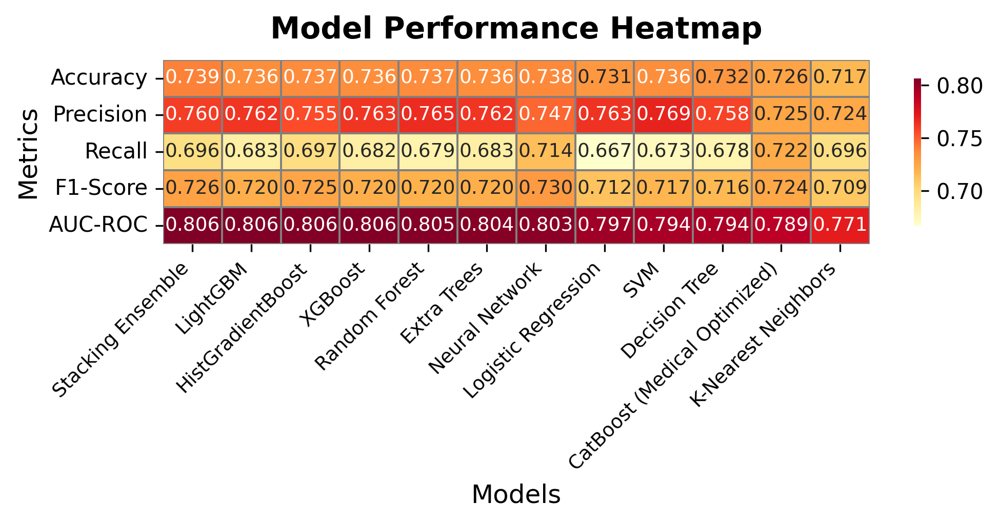

✅ Saved: ieee_heatmap.png

📊 ACCURACY BAR CHART DATA:
----------------------------------------
Values for Accuracy:
  K-Nearest Neighbors: 0.7165
  CatBoost (Medical Optimized): 0.7258
  Logistic Regression: 0.7312
  Decision Tree: 0.7324
  LightGBM: 0.7363
  Extra Trees: 0.7364
  XGBoost: 0.7364
  SVM: 0.7365
  Random Forest: 0.7368
  HistGradientBoost: 0.7369
  Neural Network: 0.7375
  Stacking Ensemble: 0.7393
Min: 0.7165, Max: 0.7393
Mean: 0.7335, Std: 0.0065


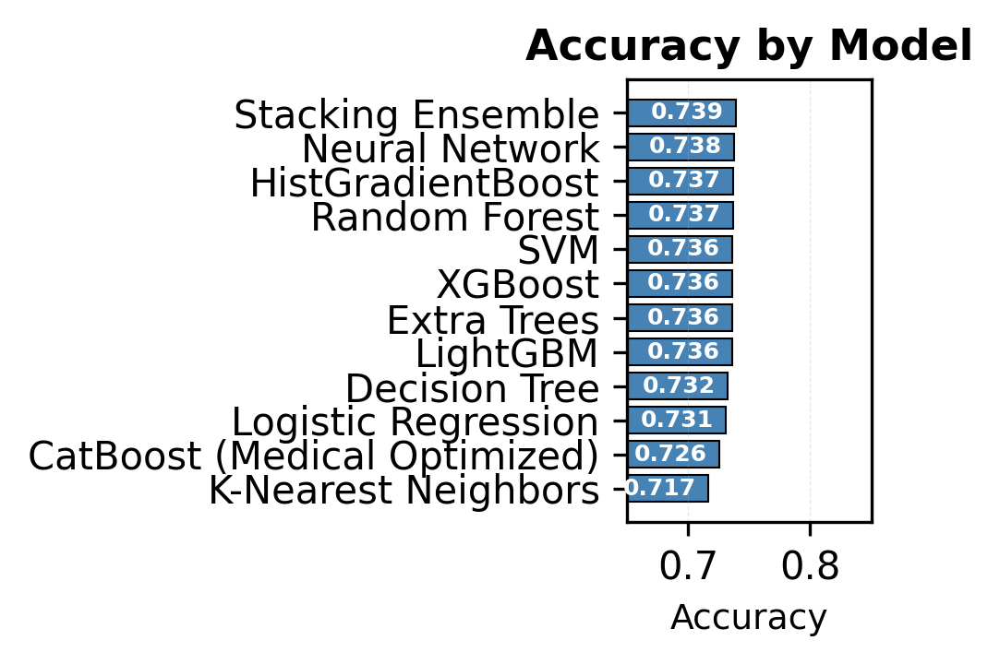

✅ Saved: ieee_accuracy.png

📊 PRECISION BAR CHART DATA:
----------------------------------------
Values for Precision:
  K-Nearest Neighbors: 0.7236
  CatBoost (Medical Optimized): 0.7254
  Neural Network: 0.7472
  HistGradientBoost: 0.7551
  Decision Tree: 0.7584
  Stacking Ensemble: 0.7600
  LightGBM: 0.7623
  Extra Trees: 0.7625
  XGBoost: 0.7627
  Logistic Regression: 0.7629
  Random Forest: 0.7652
  SVM: 0.7686
Min: 0.7236, Max: 0.7686
Mean: 0.7545, Std: 0.0150


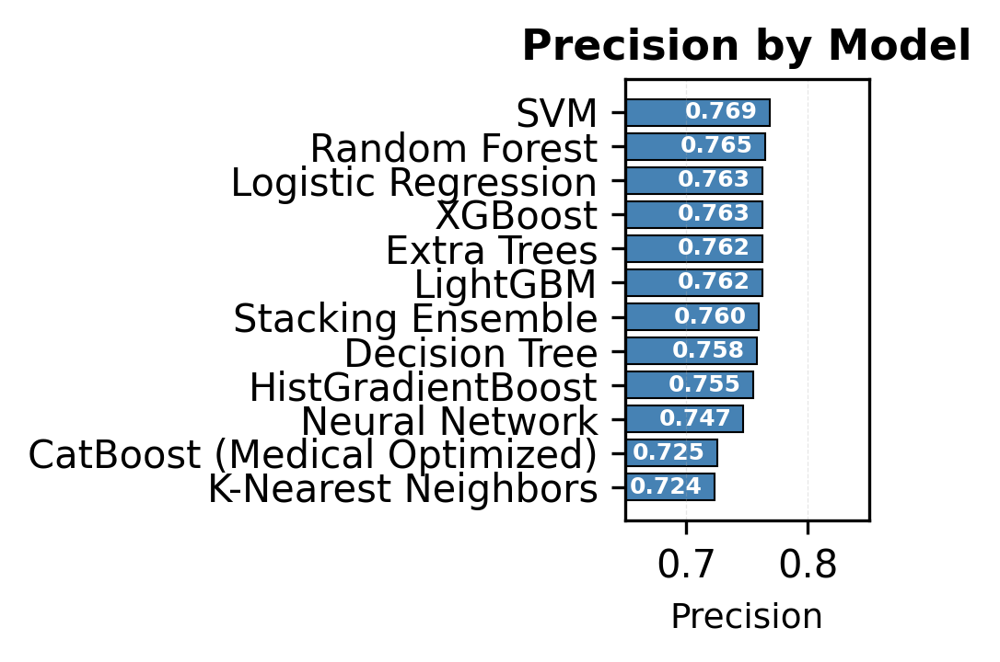

✅ Saved: ieee_precision.png

📊 RECALL BAR CHART DATA:
----------------------------------------
Values for Recall:
  Logistic Regression: 0.6668
  SVM: 0.6728
  Decision Tree: 0.6782
  Random Forest: 0.6791
  XGBoost: 0.6822
  LightGBM: 0.6826
  Extra Trees: 0.6826
  Stacking Ensemble: 0.6957
  K-Nearest Neighbors: 0.6959
  HistGradientBoost: 0.6973
  Neural Network: 0.7139
  CatBoost (Medical Optimized): 0.7222
Min: 0.6668, Max: 0.7222
Mean: 0.6891, Std: 0.0165


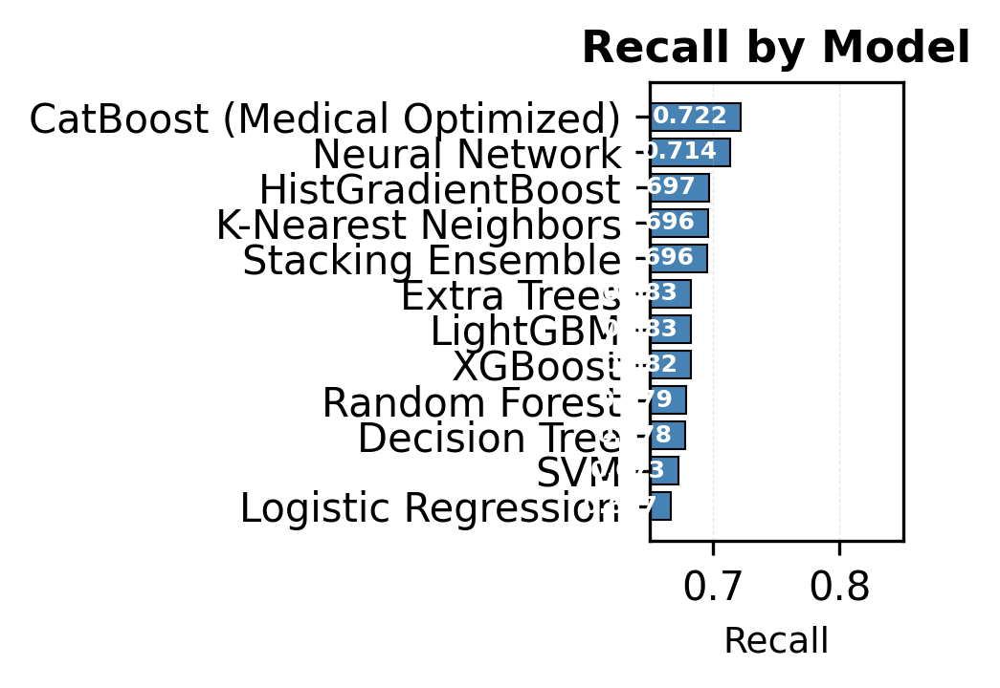

✅ Saved: ieee_recall.png

📊 F1-SCORE BAR CHART DATA:
----------------------------------------
Values for F1-Score:
  K-Nearest Neighbors: 0.7095
  Logistic Regression: 0.7116
  Decision Tree: 0.7160
  SVM: 0.7175
  Random Forest: 0.7196
  XGBoost: 0.7202
  LightGBM: 0.7203
  Extra Trees: 0.7204
  CatBoost (Medical Optimized): 0.7238
  HistGradientBoost: 0.7250
  Stacking Ensemble: 0.7264
  Neural Network: 0.7301
Min: 0.7095, Max: 0.7301
Mean: 0.7200, Std: 0.0059


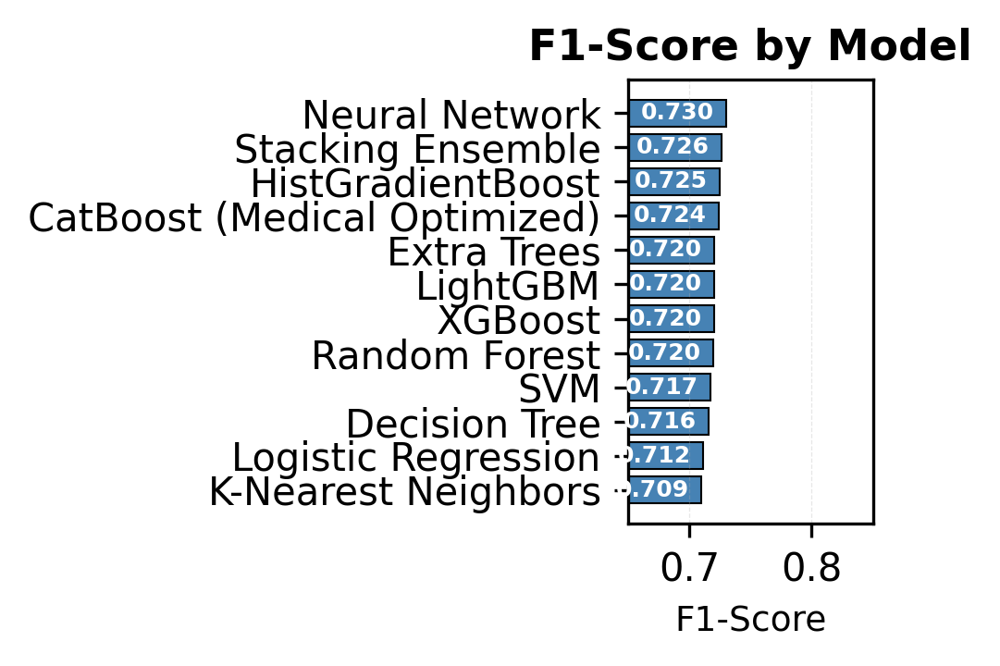

✅ Saved: ieee_f1-score.png

📊 AUC-ROC BAR CHART DATA:
----------------------------------------
Values for AUC-ROC:
  K-Nearest Neighbors: 0.7706
  CatBoost (Medical Optimized): 0.7886
  Decision Tree: 0.7938
  SVM: 0.7944
  Logistic Regression: 0.7972
  Neural Network: 0.8030
  Extra Trees: 0.8044
  Random Forest: 0.8052
  XGBoost: 0.8057
  HistGradientBoost: 0.8058
  LightGBM: 0.8061
  Stacking Ensemble: 0.8064
Min: 0.7706, Max: 0.8064
Mean: 0.7984, Std: 0.0106


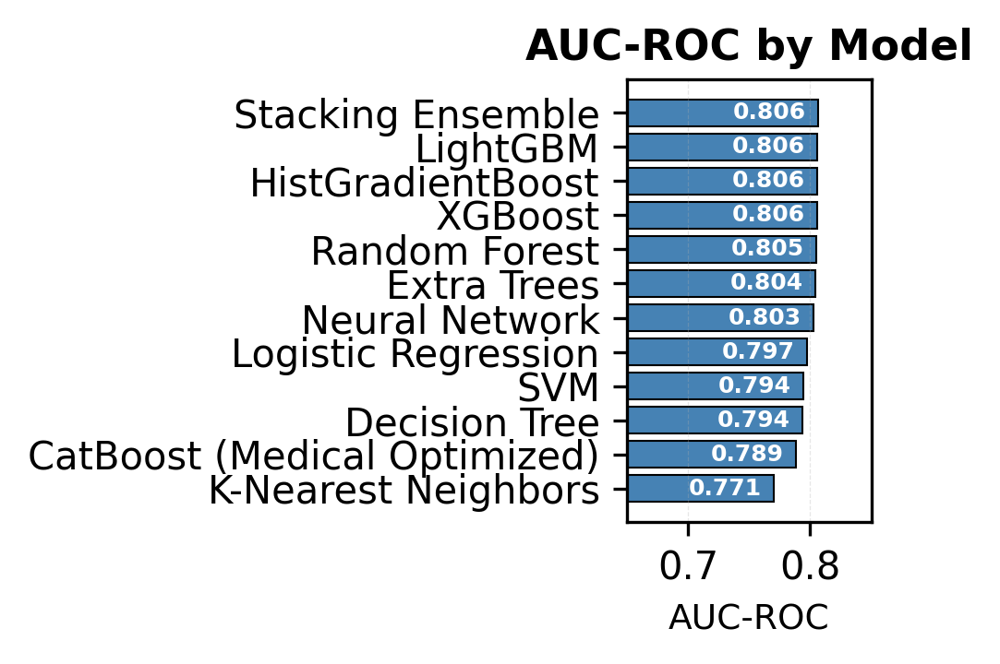

✅ Saved: ieee_auc-roc.png

⏱️ TRAINING TIME DATA:
----------------------------------------
Training times (seconds):
  HistGradientBoost: 0.82s
  Extra Trees: 8.35s
  CatBoost (Medical Optimized): 10.46s
  Logistic Regression: 12.61s
  Decision Tree: 14.74s
  Neural Network: 16.42s
  XGBoost: 32.94s
  Stacking Ensemble: 39.98s
  LightGBM: 57.03s
  K-Nearest Neighbors: 97.16s
  SVM: 180.57s
  Random Forest: 201.21s

Fastest: HistGradientBoost (0.82s)
Slowest: Random Forest (201.21s)
Average training time: 56.02s


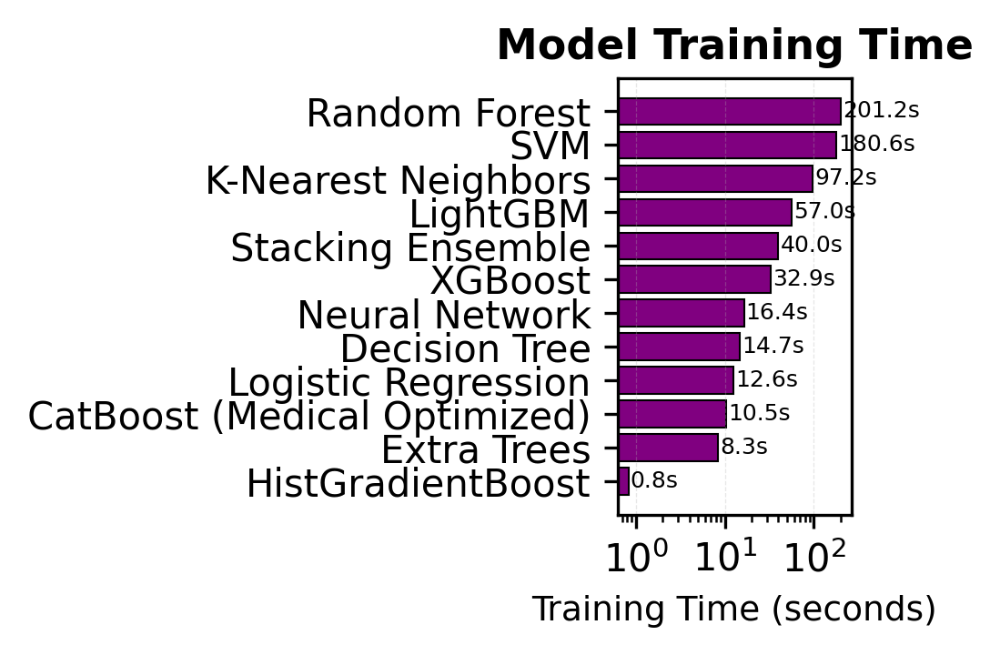

✅ Saved: ieee_training_time.png

🏆 TOP 3 MODELS DATA:
----------------------------------------
Top 3 Models by AUC-ROC:

1. Stacking Ensemble (AUC-ROC: 0.8064)
   Accuracy:  0.7393
   Precision: 0.7600
   Recall:    0.6957
   F1-Score:  0.7264

2. LightGBM (AUC-ROC: 0.8061)
   Accuracy:  0.7363
   Precision: 0.7623
   Recall:    0.6826
   F1-Score:  0.7203

3. HistGradientBoost (AUC-ROC: 0.8058)
   Accuracy:  0.7369
   Precision: 0.7551
   Recall:    0.6973
   F1-Score:  0.7250


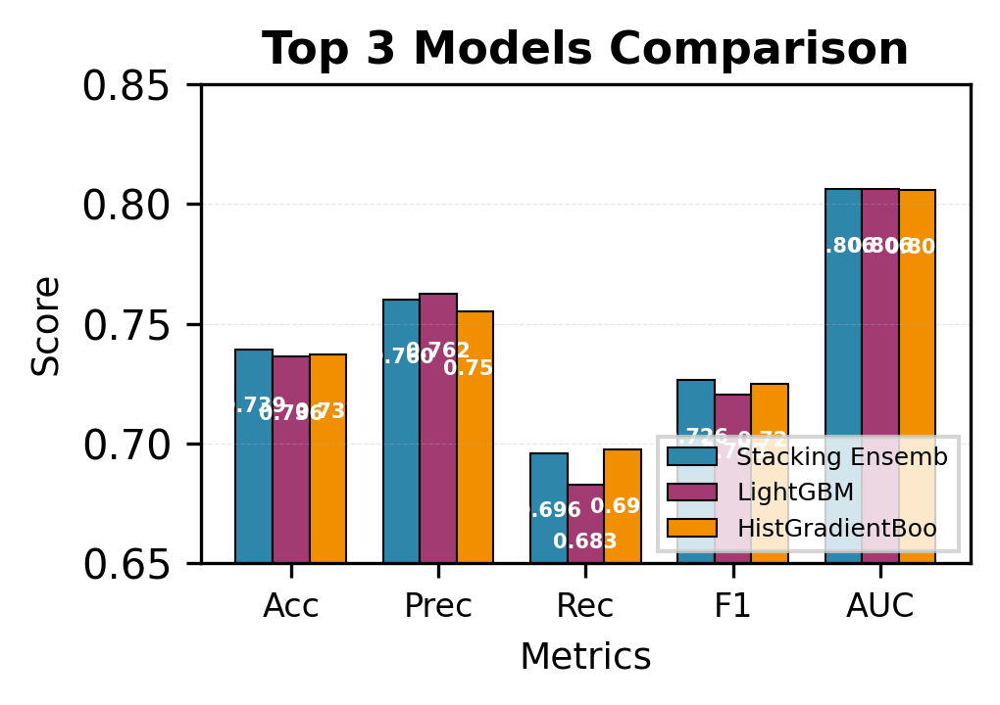

✅ Saved: ieee_top3.png

📋 SUMMARY TABLE DATA:
----------------------------------------
Complete Model Performance:
                       Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC  Training Time
           Stacking Ensemble    0.7393     0.7600  0.6957    0.7264   0.8064        39.9790
                    LightGBM    0.7363     0.7623  0.6826    0.7203   0.8061        57.0258
           HistGradientBoost    0.7369     0.7551  0.6973    0.7250   0.8058         0.8222
                     XGBoost    0.7364     0.7627  0.6822    0.7202   0.8057        32.9387
               Random Forest    0.7368     0.7652  0.6791    0.7196   0.8052       201.2140
                 Extra Trees    0.7364     0.7625  0.6826    0.7204   0.8044         8.3474
              Neural Network    0.7375     0.7472  0.7139    0.7301   0.8030        16.4186
         Logistic Regression    0.7312     0.7629  0.6668    0.7116   0.7972        12.6076
                         SVM    0.7365     0.7686  0.6728

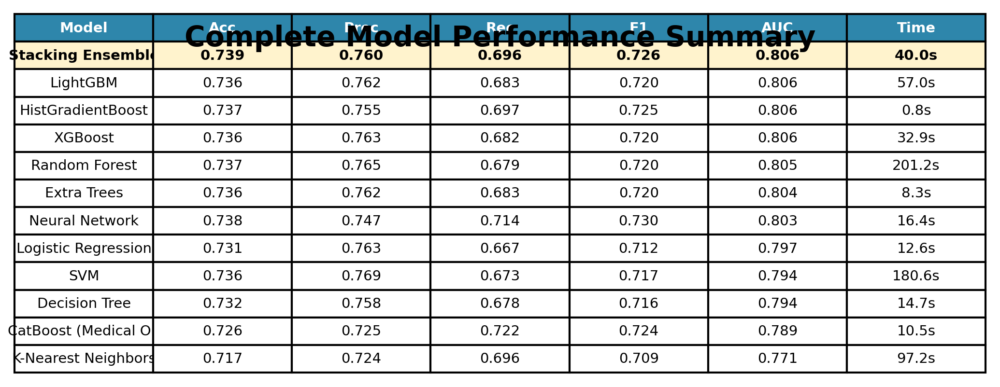

✅ Saved: ieee_table.png

📊 BEST MODEL: Stacking Ensemble
----------------------------------------
Confusion Matrix for Stacking Ensemble:
              Predicted
              No CVD    CVD
Actual No CVD    4098     1139
       CVD       1577     3606

True Negatives:  4098
False Positives: 1139
False Negatives: 1577
True Positives:  3606
Sensitivity/Recall: 0.6957
Specificity: 0.7825
Precision: 0.7600


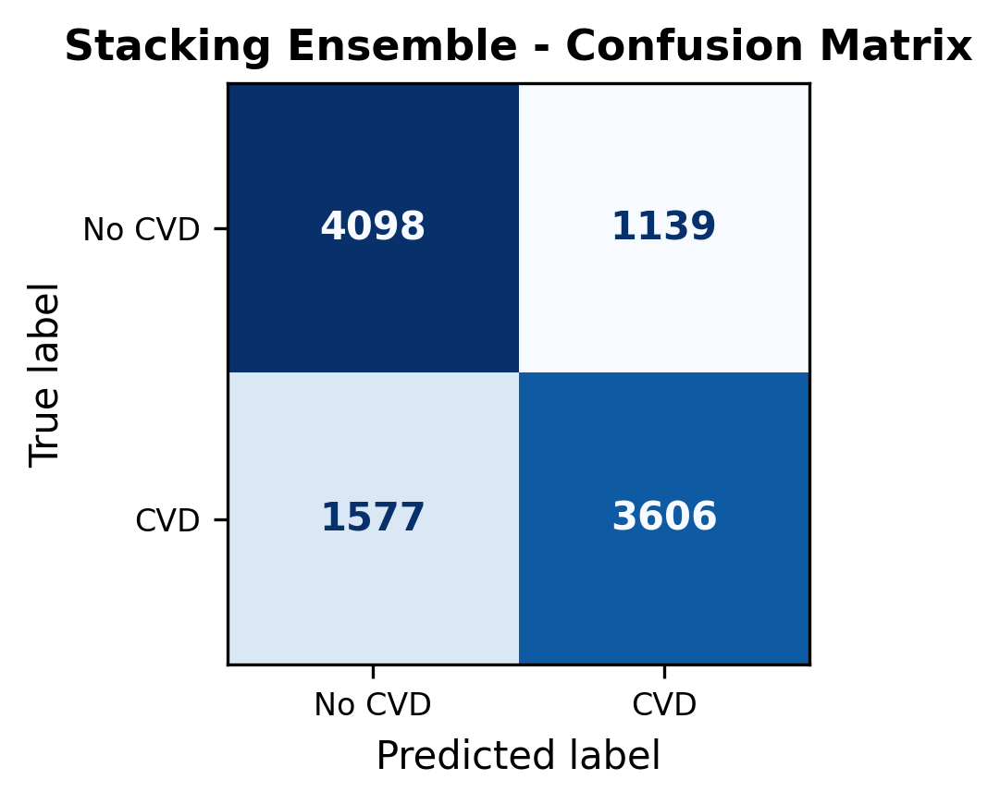

✅ Saved: ieee_cm_best.png

IEEE-OPTIMIZED GRAPHS GENERATED SUCCESSFULLY

📊 FULL WIDTH (7" width) - Use across both columns:
  • ieee_heatmap.png
  • ieee_table.png

📈 HALF WIDTH (3.5" width) - Use in single column:
  • ieee_accuracy.png
  • ieee_precision.png
  • ieee_recall.png
  • ieee_f1-score.png
  • ieee_auc-roc.png
  • ieee_training_time.png
  • ieee_top3.png
  • ieee_cm_best.png

✅ All graph data has been printed above!
✅ All images saved at 300 DPI - Ready for IEEE submission!


In [ ]:
# ============================================
# SAVE INDIVIDUAL GRAPHS FOR IEEE REPORT
# ============================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

# Reset style for IEEE
plt.style.use('default')
plt.rcParams['font.family'] = 'Times New Roman'  # IEEE prefers Times New Roman
plt.rcParams['figure.dpi'] = 300  # High DPI for printing

print("="*70)
print("GENERATING IEEE-OPTIMIZED GRAPHS")
print("="*70)

# ============================================
# 1. FULL WIDTH HEATMAP (7" x 3.5" @ 300 DPI)
# ============================================
print("\n📊 HEATMAP DATA:")
print("-" * 40)
metrics_for_heatmap = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
heatmap_data = results_df[metrics_for_heatmap].T
heatmap_data.columns = results_df['Model']

# Print the heatmap data
print("Values being plotted in heatmap:")
print(heatmap_data.round(4).to_string())
print(f"Shape: {heatmap_data.shape}")

plt.figure(figsize=(7, 3.5), dpi=300)
ax = sns.heatmap(heatmap_data, annot=True, cmap='YlOrRd', fmt='.3f',
                 cbar=True, linewidths=0.5, linecolor='gray',
                 annot_kws={'size': 9}, cbar_kws={'shrink': 0.8})

plt.title('Model Performance Heatmap', fontsize=14, fontweight='bold', pad=10)
plt.xlabel('Models', fontsize=12)
plt.ylabel('Metrics', fontsize=12)
plt.xticks(fontsize=9, rotation=45, ha='right')
plt.yticks(fontsize=10, rotation=0)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/ieee_heatmap.png',
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("✅ Saved: ieee_heatmap.png")

# ============================================
# 2. HALF WIDTH BAR CHARTS (3.5" x 2.5" @ 300 DPI)
# ============================================
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']

for metric in metrics:
    print(f"\n📊 {metric.upper()} BAR CHART DATA:")
    print("-" * 40)

    # Sort for better visualization
    sorted_df = results_df.sort_values(metric, ascending=True)

    # Print the data
    print(f"Values for {metric}:")
    for idx, row in sorted_df.iterrows():
        print(f"  {row['Model']}: {row[metric]:.4f}")

    print(f"Min: {sorted_df[metric].min():.4f}, Max: {sorted_df[metric].max():.4f}")
    print(f"Mean: {sorted_df[metric].mean():.4f}, Std: {sorted_df[metric].std():.4f}")

    plt.figure(figsize=(3.5, 2.5), dpi=300)
    bars = plt.barh(sorted_df['Model'], sorted_df[metric],
                    color='steelblue', edgecolor='black', linewidth=0.5)

    plt.xlabel(metric, fontsize=9)
    plt.title(f'{metric} by Model', fontsize=11, fontweight='bold', pad=5)
    plt.xlim([0.65, 0.85])

    for bar in bars:
        width = bar.get_width()
        plt.text(width - 0.01, bar.get_y() + bar.get_height()/2,
                f'{width:.3f}', ha='right', va='center',
                fontsize=6, color='white', fontweight='bold')

    plt.grid(axis='x', linestyle='--', alpha=0.3, linewidth=0.3)
    plt.tight_layout()

    filename = f'/content/drive/MyDrive/Colab Notebooks/DA/CVD/ieee_{metric.lower()}.png'
    plt.savefig(filename, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"✅ Saved: ieee_{metric.lower()}.png")

# ============================================
# 3. TRAINING TIME CHART (3.5" x 2.5" @ 300 DPI)
# ============================================
print("\n⏱️ TRAINING TIME DATA:")
print("-" * 40)

time_df = results_df.sort_values('Training Time', ascending=True)
print("Training times (seconds):")
for idx, row in time_df.iterrows():
    print(f"  {row['Model']}: {row['Training Time']:.2f}s")

print(f"\nFastest: {time_df.iloc[0]['Model']} ({time_df.iloc[0]['Training Time']:.2f}s)")
print(f"Slowest: {time_df.iloc[-1]['Model']} ({time_df.iloc[-1]['Training Time']:.2f}s)")
print(f"Average training time: {time_df['Training Time'].mean():.2f}s")

plt.figure(figsize=(3.5, 2.5), dpi=300)
bars = plt.barh(time_df['Model'], time_df['Training Time'],
                color='purple', edgecolor='black', linewidth=0.5)

plt.xlabel('Training Time (seconds)', fontsize=9)
plt.title('Model Training Time', fontsize=11, fontweight='bold', pad=5)
plt.xscale('log')

for bar in bars:
    width = bar.get_width()
    plt.text(width * 1.05, bar.get_y() + bar.get_height()/2,
            f'{width:.1f}s', va='center', fontsize=6)

plt.grid(axis='x', linestyle='--', alpha=0.3, linewidth=0.3)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/ieee_training_time.png',
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("✅ Saved: ieee_training_time.png")

# ============================================
# 4. TOP 3 MODELS COMPARISON (3.5" x 2.5" @ 300 DPI)
# ============================================
print("\n🏆 TOP 3 MODELS DATA:")
print("-" * 40)

top3_df = results_df.head(3)
print("Top 3 Models by AUC-ROC:")
for i, (idx, row) in enumerate(top3_df.iterrows()):
    print(f"\n{i+1}. {row['Model']} (AUC-ROC: {row['AUC-ROC']:.4f})")
    print(f"   Accuracy:  {row['Accuracy']:.4f}")
    print(f"   Precision: {row['Precision']:.4f}")
    print(f"   Recall:    {row['Recall']:.4f}")
    print(f"   F1-Score:  {row['F1-Score']:.4f}")

plt.figure(figsize=(3.5, 2.5), dpi=300)

metrics_abbr = ['Acc', 'Prec', 'Rec', 'F1', 'AUC']
x = np.arange(len(metrics_abbr))
width = 0.25
colors = ['#2E86AB', '#A23B72', '#F18F01']

for i, (model, color) in enumerate(zip(top3_df['Model'], colors)):
    offset = width * i
    values = top3_df.iloc[i][['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']].values
    bars = plt.bar(x + offset, values, width, label=model[:15],
                   color=color, edgecolor='black', linewidth=0.5)

    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height - 0.02,
                f'{height:.3f}', ha='center', va='top',
                fontsize=5, color='white', fontweight='bold')

plt.xlabel('Metrics', fontsize=9)
plt.ylabel('Score', fontsize=9)
plt.title('Top 3 Models Comparison', fontsize=11, fontweight='bold', pad=5)
plt.xticks(x + width, metrics_abbr, fontsize=8)
plt.ylim([0.65, 0.85])
plt.legend(loc='lower right', fontsize=6, frameon=True, fancybox=False)
plt.grid(axis='y', linestyle='--', alpha=0.3, linewidth=0.3)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/ieee_top3.png',
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("✅ Saved: ieee_top3.png")

# ============================================
# 5. SUMMARY TABLE (Full width - 7" x 3" @ 300 DPI)
# ============================================
print("\n📋 SUMMARY TABLE DATA:")
print("-" * 40)

print("Complete Model Performance:")
print(results_df[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC', 'Training Time']].round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3), dpi=300)
ax.axis('off')

table_data = []
for _, row in results_df.iterrows():
    table_data.append([
        row['Model'][:20],
        f"{row['Accuracy']:.3f}",
        f"{row['Precision']:.3f}",
        f"{row['Recall']:.3f}",
        f"{row['F1-Score']:.3f}",
        f"{row['AUC-ROC']:.3f}",
        f"{row['Training Time']:.1f}s"
    ])

columns = ['Model', 'Acc', 'Prec', 'Rec', 'F1', 'AUC', 'Time']

table = ax.table(cellText=table_data, colLabels=columns,
                 cellLoc='center', loc='center', fontsize=8)
table.auto_set_font_size(False)
table.set_fontsize(7)
table.scale(1, 1.5)

header_color = '#2E86AB'
for j in range(len(columns)):
    cell = table[(0, j)]
    cell.set_facecolor(header_color)
    cell.set_text_props(color='white', weight='bold')

for j in range(len(columns)):
    cell = table[(1, j)]
    cell.set_facecolor('#FFF3CD')
    cell.set_text_props(weight='bold')

plt.title('Complete Model Performance Summary', fontsize=14, fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/ieee_table.png',
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("✅ Saved: ieee_table.png")

# ============================================
# 6. CONFUSION MATRIX FOR BEST MODEL (3.5" x 3" @ 300 DPI)
# ============================================
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

best_model_name = results_df.iloc[0]['Model']
print(f"\n📊 BEST MODEL: {best_model_name}")
print("-" * 40)

# Find which model object corresponds to best model
best_model_obj = None
if best_model_name == 'Stacking Ensemble':
    best_model_obj = stacking_model
elif best_model_name == 'LightGBM':
    best_model_obj = lgb_best
elif best_model_name == 'HistGradientBoost':
    best_model_obj = hgb_model
elif best_model_name == 'CatBoost (Medical Optimized)':
    best_model_obj = catboost_model
elif best_model_name == 'XGBoost':
    best_model_obj = xgb_best
elif best_model_name == 'Random Forest':
    best_model_obj = rf_best
# Add other conditions as needed

if best_model_obj:
    y_pred_best = best_model_obj.predict(X_val)
    cm = confusion_matrix(y_val, y_pred_best)

    print(f"Confusion Matrix for {best_model_name}:")
    print("              Predicted")
    print("              No CVD    CVD")
    print(f"Actual No CVD   {cm[0,0]:5d}    {cm[0,1]:5d}")
    print(f"       CVD      {cm[1,0]:5d}    {cm[1,1]:5d}")

    tn, fp, fn, tp = cm.ravel()
    print(f"\nTrue Negatives:  {tn}")
    print(f"False Positives: {fp}")
    print(f"False Negatives: {fn}")
    print(f"True Positives:  {tp}")
    print(f"Sensitivity/Recall: {tp/(tp+fn):.4f}")
    print(f"Specificity: {tn/(tn+fp):.4f}")
    print(f"Precision: {tp/(tp+fp):.4f}")

    fig, ax = plt.subplots(figsize=(3.5, 3), dpi=300)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No CVD', 'CVD'])
    disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)

    ax.set_title(f'{best_model_name[:20]} - Confusion Matrix', fontsize=11, fontweight='bold')
    ax.tick_params(axis='both', which='major', labelsize=8)

    for text in disp.text_.ravel():
        text.set_size(10)
        text.set_weight('bold')

    plt.tight_layout()
    plt.savefig('/content/drive/MyDrive/Colab Notebooks/DA/CVD/ieee_cm_best.png',
                dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print("✅ Saved: ieee_cm_best.png")
else:
    print(f"⚠️ Could not find model object for {best_model_name}")

# ============================================
# SUMMARY
# ============================================
print("\n" + "="*70)
print("IEEE-OPTIMIZED GRAPHS GENERATED SUCCESSFULLY")
print("="*70)
print("\n📊 FULL WIDTH (7\" width) - Use across both columns:")
print("  • ieee_heatmap.png")
print("  • ieee_table.png")
print("\n📈 HALF WIDTH (3.5\" width) - Use in single column:")
print("  • ieee_accuracy.png")
print("  • ieee_precision.png")
print("  • ieee_recall.png")
print("  • ieee_f1-score.png")
print("  • ieee_auc-roc.png")
print("  • ieee_training_time.png")
print("  • ieee_top3.png")
print("  • ieee_cm_best.png")
print("\n✅ All graph data has been printed above!")
print("✅ All images saved at 300 DPI - Ready for IEEE submission!")

**XAI: LIME, SHAP, and Grad-CAM for Top 3 Models**

In [ ]:
# ============================================
# XAI: LIME, SHAP, and Grad-CAM for Top 3 Models
# ============================================

print("="*70)
print("XAI: EXPLAINABLE AI FOR TOP 3 MODELS")
print("="*70)

# Install required libraries
!pip install shap lime grad-cam -q

import shap
import lime
import lime.lime_tabular
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Get top 3 models from results_df
top3_models = results_df.head(3)['Model'].tolist()
print(f"Top 3 Models: {top3_models}")

# Map model names to actual model objects
model_objects = {}
if 'Stacking Ensemble' in top3_models:
    model_objects['Stacking Ensemble'] = stacking_model
if 'LightGBM' in top3_models:
    model_objects['LightGBM'] = lgb_best  # or your LightGBM variable
if 'HistGradientBoost' in top3_models:
    model_objects['HistGradientBoost'] = hgb_model
if 'XGBoost' in top3_models:
    model_objects['XGBoost'] = xgb_best
if 'Random Forest' in top3_models:
    model_objects['Random Forest'] = rf_best

# Select a few samples for explanation
np.random.seed(42)
sample_indices = np.random.choice(len(X_val), size=5, replace=False)
X_explain = X_val.iloc[sample_indices] if hasattr(X_val, 'iloc') else X_val[sample_indices]
y_explain = y_val.iloc[sample_indices] if hasattr(y_val, 'iloc') else y_val[sample_indices]

print(f"\nSelected {len(sample_indices)} samples for XAI analysis")

XAI: EXPLAINABLE AI FOR TOP 3 MODELS
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 35.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Top 3 Models: ['Stacking Ensemble', 'LightGBM', 'HistGradientBoost']

Selected 5 samples for XAI analysis


**SHAP ANALYSIS**

SHAP ANALYSIS - WITH BEST SAMPLE RECOMMENDATION

SHAP Analysis for: Stacking Ensemble

🔍 Finding best patient sample for report...

🏆 BEST SAMPLE FOR Stacking Ensemble:
   Index: 2938
   True Label: 0 (No CVD)
   Predicted: 0 (No CVD)
   Probability (CVD): 0.0970
   Confidence: 0.4030
   Correct Prediction: ✅ YES

   Top 5 candidate samples for report:
      1. Index 2938: True=0, Pred=0, Prob=0.0970, Confidence=0.4030
      2. Index 1263: True=0, Pred=0, Prob=0.0973, Confidence=0.4027
      3. Index 6524: True=0, Pred=0, Prob=0.0973, Confidence=0.4027
      4. Index 5011: True=0, Pred=0, Prob=0.0993, Confidence=0.4007
      5. Index 1115: True=0, Pred=0, Prob=0.1013, Confidence=0.3987

Using KernelExplainer for Stacking Ensemble...


  0%|          | 0/50 [00:00<?, ?it/s]

✓ SHAP values shape: (50, 16)

🔝 Top 5 Most Important Features (Global):
   1. ap_hi: 0.1370
   2. age_years: 0.0472
   3. map: 0.0445
   4. cholesterol: 0.0350
   5. risk_score: 0.0167

📈 Generating SHAP Summary Plot...


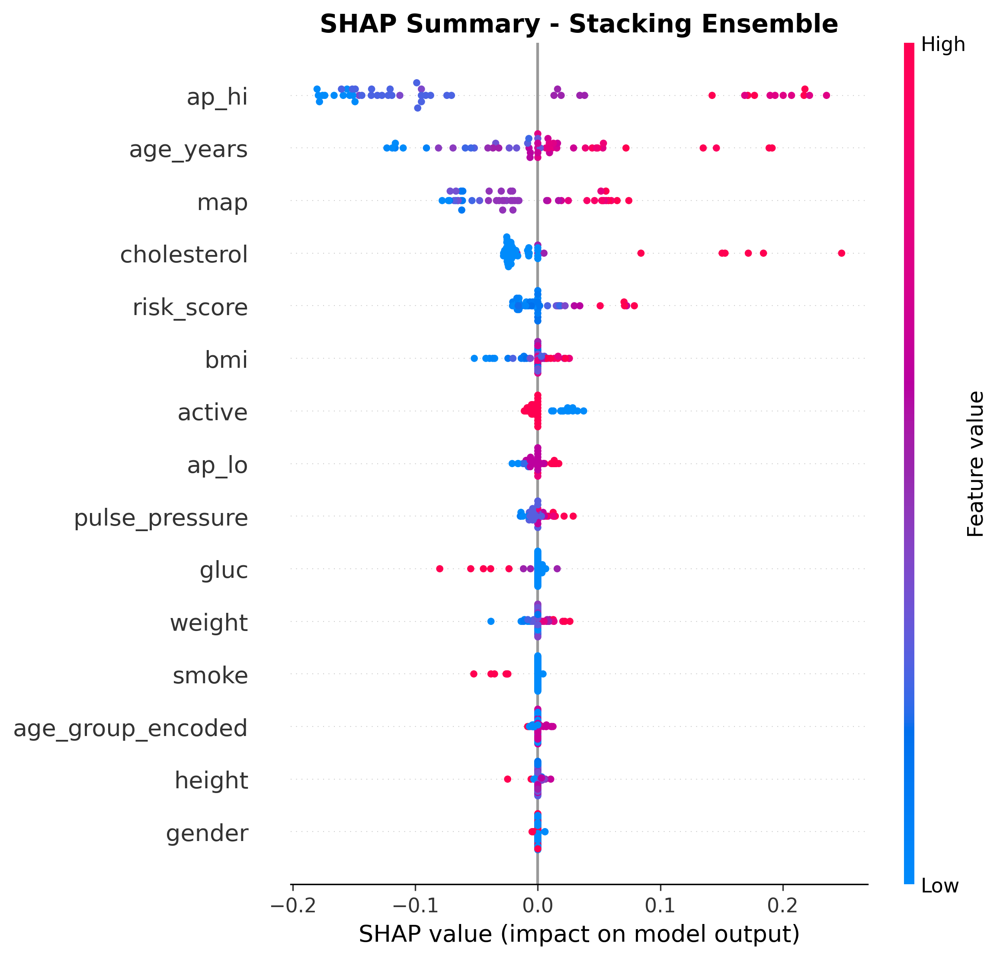

✅ Saved: shap_summary_Stacking_Ensemble.png

📊 Generating SHAP Bar Plot...


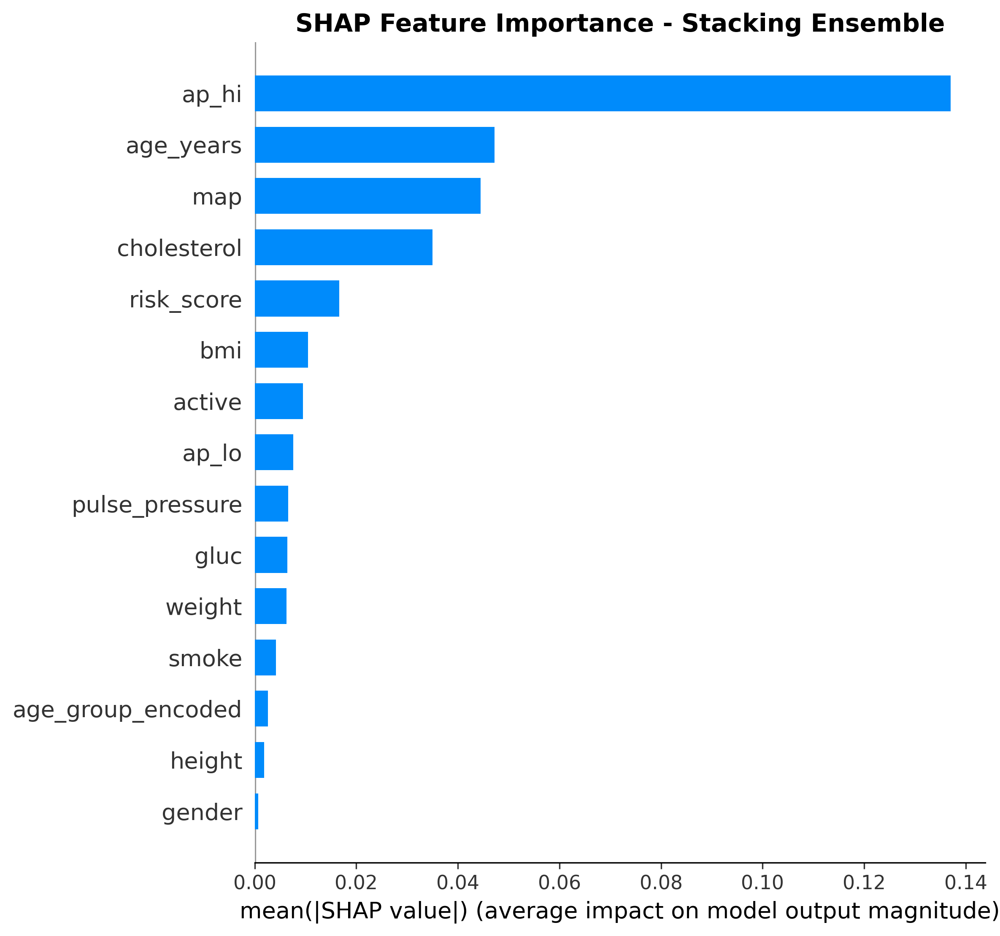

✅ Saved: shap_bar_Stacking_Ensemble.png

💧 Generating SHAP Waterfall Plot for BEST SAMPLE (Index: 2938)...
   Note: Best index 2938 beyond subset, using sample 0


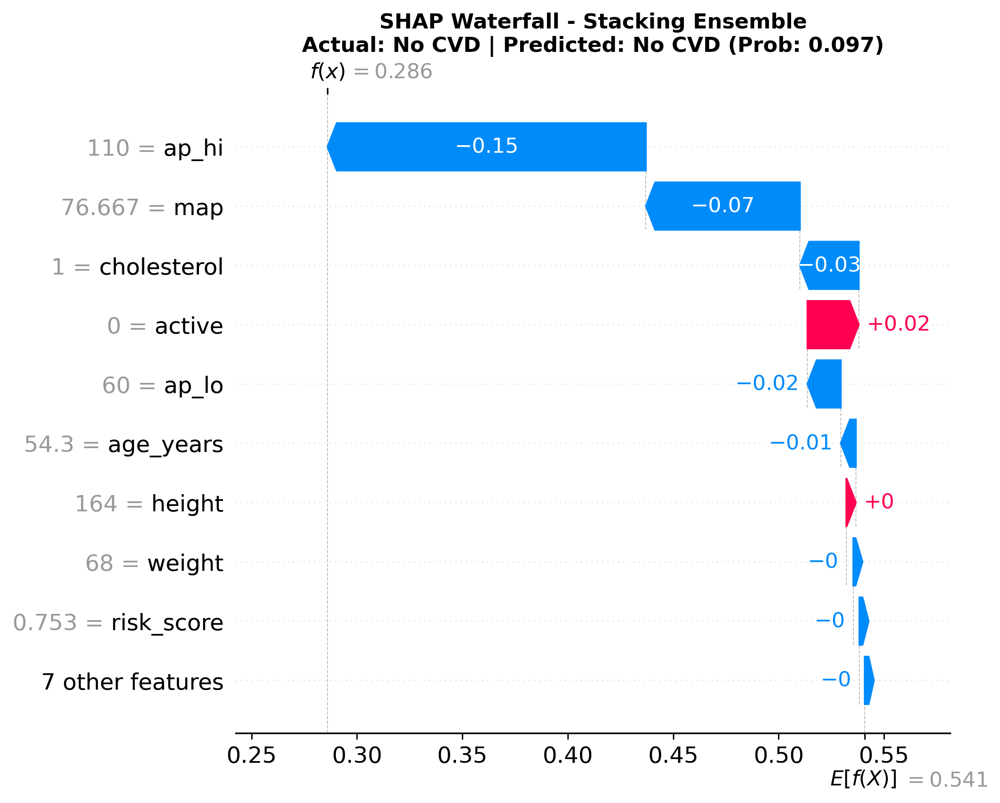

✅ Saved: shap_waterfall_Stacking_Ensemble_BEST.png

📋 DETAILED EXPLANATION FOR REPORT:
   Patient #2938
   Actual Condition: No CVD
   Model Prediction: No CVD (Probability: 0.097)

   Top features INCREASING CVD risk:
      1. active: +0.0244

   Top features DECREASING CVD risk:
      1. ap_hi: -0.1510
      2. map: -0.0730
      3. cholesterol: -0.0279
      4. ap_lo: -0.0158

✅ SHAP analysis completed for Stacking Ensemble

SHAP Analysis for: LightGBM

🔍 Finding best patient sample for report...

🏆 BEST SAMPLE FOR LightGBM:
   Index: 238
   True Label: 1 (CVD)
   Predicted: 1 (CVD)
   Probability (CVD): 0.8267
   Confidence: 0.3267
   Correct Prediction: ✅ YES

   Top 5 candidate samples for report:
      1. Index 9801: True=1, Pred=1, Prob=0.8267, Confidence=0.3267
      2. Index 1766: True=1, Pred=1, Prob=0.8267, Confidence=0.3267
      3. Index 4611: True=1, Pred=1, Prob=0.8267, Confidence=0.3267
      4. Index 4889: True=1, Pred=1, Prob=0.8267, Confidence=0.3267
      5. Index 

  0%|          | 0/50 [00:00<?, ?it/s]

✓ SHAP values shape: (50, 16)

🔝 Top 5 Most Important Features (Global):
   1. risk_score: 0.0196
   2. gluc: 0.0178
   3. active: 0.0139
   4. cholesterol: 0.0114
   5. smoke: 0.0019

📈 Generating SHAP Summary Plot...


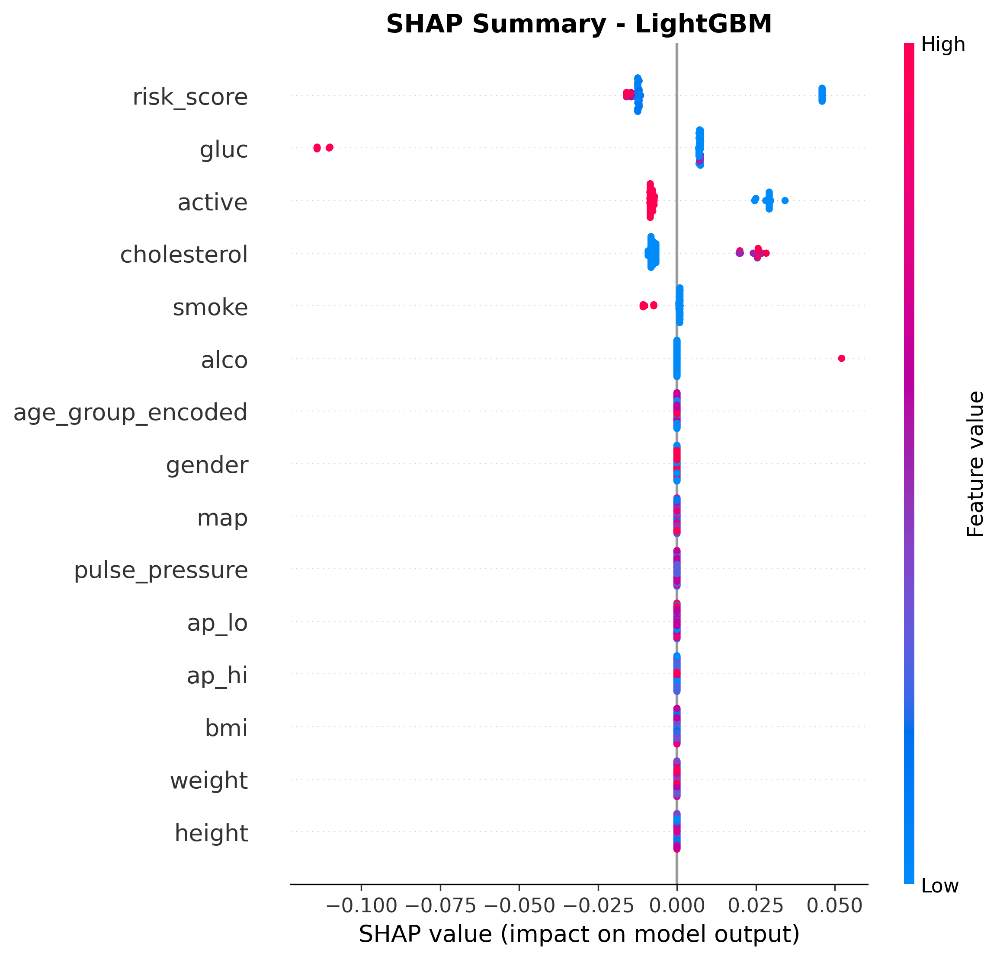

✅ Saved: shap_summary_LightGBM.png

📊 Generating SHAP Bar Plot...


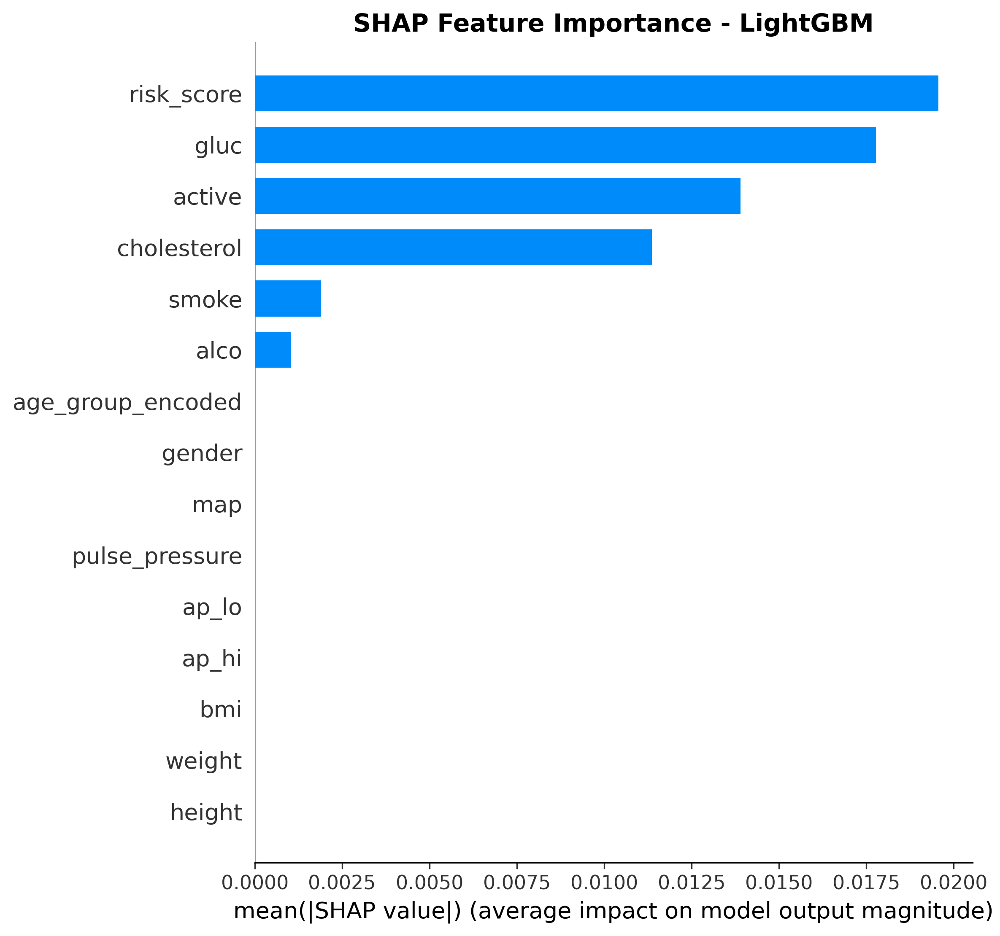

✅ Saved: shap_bar_LightGBM.png

💧 Generating SHAP Waterfall Plot for BEST SAMPLE (Index: 238)...
   Note: Best index 238 beyond subset, using sample 0


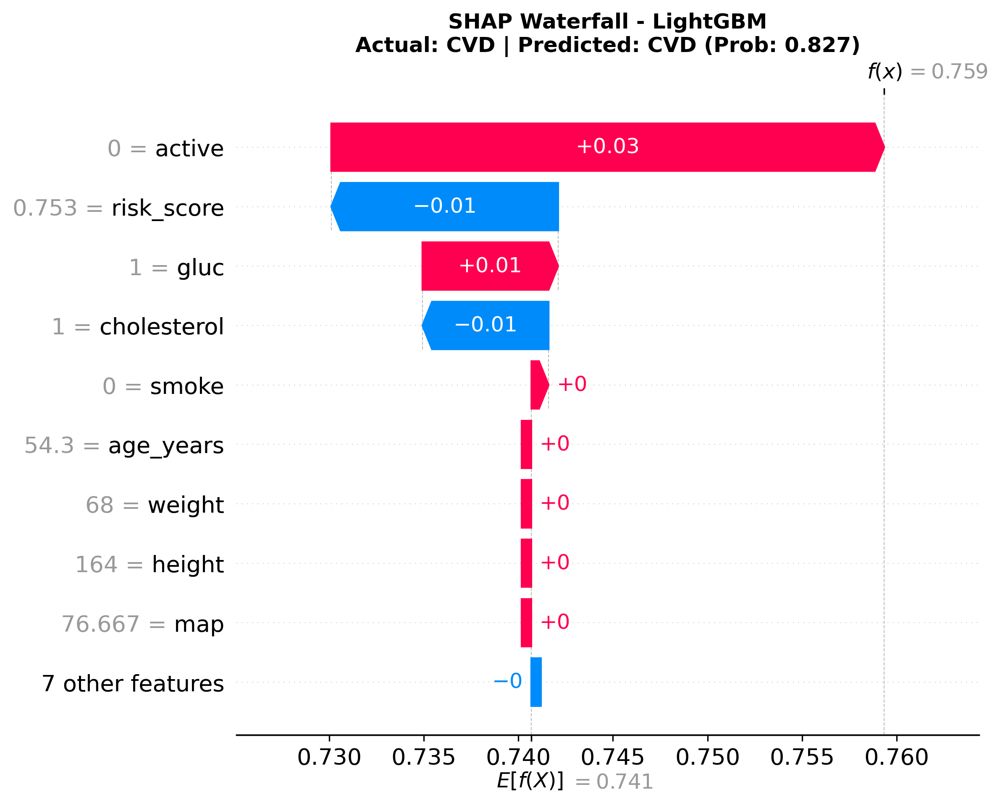

✅ Saved: shap_waterfall_LightGBM_BEST.png

📋 DETAILED EXPLANATION FOR REPORT:
   Patient #238
   Actual Condition: CVD
   Model Prediction: CVD (Probability: 0.827)

   Top features INCREASING CVD risk:
      1. active: +0.0292

   Top features DECREASING CVD risk:
      1. risk_score: -0.0120

✅ SHAP analysis completed for LightGBM

SHAP Analysis for: HistGradientBoost

🔍 Finding best patient sample for report...

🏆 BEST SAMPLE FOR HistGradientBoost:
   Index: 2938
   True Label: 0 (No CVD)
   Predicted: 0 (No CVD)
   Probability (CVD): 0.0357
   Confidence: 0.4643
   Correct Prediction: ✅ YES

   Top 5 candidate samples for report:
      1. Index 2938: True=0, Pred=0, Prob=0.0357, Confidence=0.4643
      2. Index 5011: True=0, Pred=0, Prob=0.0362, Confidence=0.4638
      3. Index 6524: True=0, Pred=0, Prob=0.0367, Confidence=0.4633
      4. Index 1263: True=0, Pred=0, Prob=0.0367, Confidence=0.4633
      5. Index 1944: True=0, Pred=0, Prob=0.0391, Confidence=0.4609

Using TreeExplain

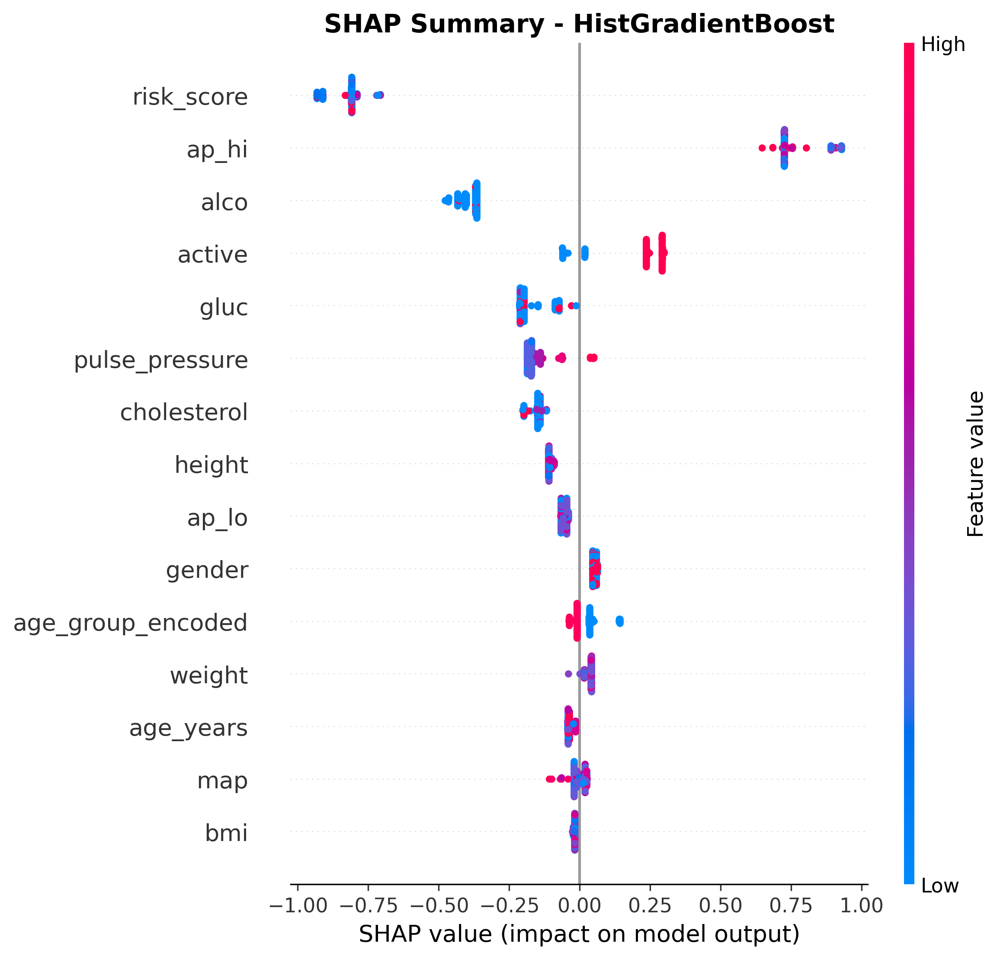

✅ Saved: shap_summary_HistGradientBoost.png

📊 Generating SHAP Bar Plot...


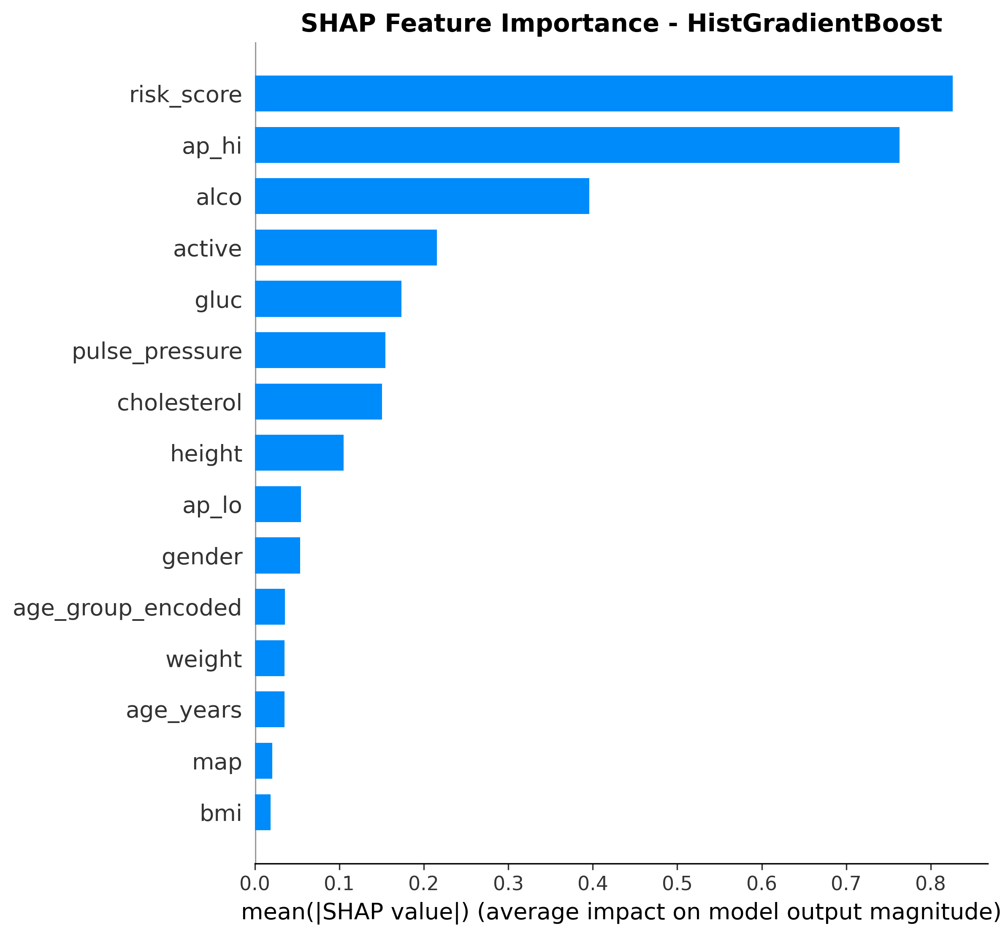

✅ Saved: shap_bar_HistGradientBoost.png

💧 Generating SHAP Waterfall Plot for BEST SAMPLE (Index: 2938)...
   Note: Best index 2938 beyond subset, using sample 0


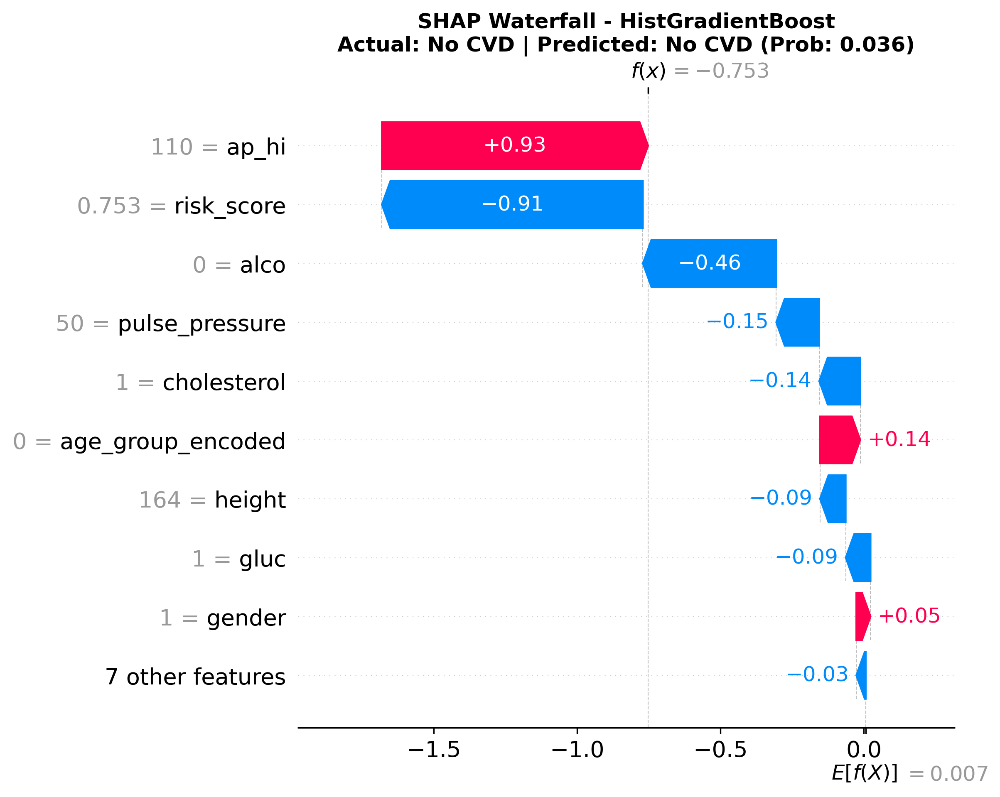

✅ Saved: shap_waterfall_HistGradientBoost_BEST.png

📋 DETAILED EXPLANATION FOR REPORT:
   Patient #2938
   Actual Condition: No CVD
   Model Prediction: No CVD (Probability: 0.036)

   Top features INCREASING CVD risk:
      1. ap_hi: +0.9286
      2. age_group_encoded: +0.1405
      3. gender: +0.0498
      4. active: +0.0186
      5. smoke: +0.0180

   Top features DECREASING CVD risk:
      1. risk_score: -0.9104
      2. alco: -0.4650
      3. pulse_pressure: -0.1499
      4. cholesterol: -0.1433
      5. height: -0.0897

✅ SHAP analysis completed for HistGradientBoost

📋 FINAL RECOMMENDATION FOR IEEE REPORT

Best sample for each model:

   Stacking Ensemble:
      - Patient Index: 2938
      - Actual: No CVD
      - Predicted: No CVD
      - Confidence: 0.4030
      - Waterfall plot saved as: shap_waterfall_Stacking_Ensemble_BEST.png

   LightGBM:
      - Patient Index: 238
      - Actual: CVD
      - Predicted: CVD
      - Confidence: 0.3267
      - Waterfall plot saved as: shap_

In [ ]:
# ============================================
# SHAP ANALYSIS WITH BEST SAMPLE SELECTION FOR REPORT
# ============================================

print("="*70)
print("SHAP ANALYSIS - WITH BEST SAMPLE RECOMMENDATION")
print("="*70)

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Convert to numpy to avoid pandas index issues
X_train_np = X_train.values if hasattr(X_train, 'values') else np.array(X_train)
X_val_np = X_val.values if hasattr(X_val, 'values') else np.array(X_val)
y_val_np = y_val.values if hasattr(y_val, 'values') else np.array(y_val)

# Custom wrapper for LightGBM to avoid attribute error
class LightGBMWrapper:
    """Wrapper to avoid LightGBM feature_names_in_ attribute error"""
    def __init__(self, model):
        self.model = model

    def predict_proba(self, X):
        return self.model.predict_proba(X)

    def predict(self, X):
        return self.model.predict(X)

# Store best samples for each model
best_samples = {}

for model_name, model in model_objects.items():
    print(f"\n{'='*50}")
    print(f"SHAP Analysis for: {model_name}")
    print(f"{'='*50}")

    # ============================================
    # FIRST: Find best patient sample for report
    # ============================================
    print(f"\n🔍 Finding best patient sample for report...")

    # Get predictions for ALL validation samples
    y_pred_proba_full = model.predict_proba(X_val_np)[:, 1]
    y_pred_full = (y_pred_proba_full >= 0.5).astype(int)

    # Calculate metrics for each sample
    correct_mask = (y_pred_full == y_val_np)
    confidence = np.abs(y_pred_proba_full - 0.5)  # Distance from 0.5 (higher = more confident)

    # Score each sample: correct prediction + high confidence
    sample_scores = correct_mask.astype(int) * confidence

    # Find best sample (highest score)
    best_idx = np.argmax(sample_scores)
    best_confidence = confidence[best_idx]
    best_correct = correct_mask[best_idx]
    best_proba = y_pred_proba_full[best_idx]
    best_true = y_val_np[best_idx]
    best_pred = y_pred_full[best_idx]

    # Store for later use
    best_samples[model_name] = {
        'index': best_idx,
        'true_label': best_true,
        'pred_label': best_pred,
        'probability': best_proba,
        'confidence': best_confidence,
        'correct': best_correct
    }

    print(f"\n🏆 BEST SAMPLE FOR {model_name}:")
    print(f"   Index: {best_idx}")
    print(f"   True Label: {best_true} ({'CVD' if best_true==1 else 'No CVD'})")
    print(f"   Predicted: {best_pred} ({'CVD' if best_pred==1 else 'No CVD'})")
    print(f"   Probability (CVD): {best_proba:.4f}")
    print(f"   Confidence: {best_confidence:.4f}")
    print(f"   Correct Prediction: {'✅ YES' if best_correct else '❌ NO'}")

    # Also show top 5 candidates
    top_candidates = np.argsort(sample_scores)[-5:][::-1]
    print(f"\n   Top 5 candidate samples for report:")
    for rank, idx in enumerate(top_candidates[:5]):
        print(f"      {rank+1}. Index {idx}: True={y_val_np[idx]}, Pred={y_pred_full[idx]}, Prob={y_pred_proba_full[idx]:.4f}, Confidence={confidence[idx]:.4f}")

    # ============================================
    # Now run SHAP analysis using the BEST sample
    # ============================================

    try:
        # Use smaller subset for speed
        n_samples_shap = min(100, len(X_val_np))
        X_subset = X_val_np[:n_samples_shap]

        # Create SHAP explainer based on model type
        if 'HistGradientBoost' in model_name:
            print("\nUsing TreeExplainer for HistGradientBoost...")
            explainer = shap.TreeExplainer(model)
            shap_values_raw = explainer.shap_values(X_subset)

            if isinstance(shap_values_raw, list):
                shap_values_class1 = shap_values_raw[1]
                expected_value = explainer.expected_value[1]
            else:
                shap_values_class1 = shap_values_raw
                expected_value = explainer.expected_value

            print(f"✓ SHAP values shape: {shap_values_class1.shape}")

        elif 'LGBM' in model_name:
            print("\nUsing KernelExplainer for LightGBM...")
            wrapped_model = LightGBMWrapper(model)
            background = X_train_np[:min(50, X_train_np.shape[0])]
            explainer = shap.KernelExplainer(wrapped_model.predict_proba, background)
            shap_values_raw = explainer.shap_values(X_subset[:min(50, len(X_subset))])

            if len(shap_values_raw.shape) == 3:
                shap_values_class1 = shap_values_raw[:, :, 1]
                expected_value = explainer.expected_value[1]
            else:
                shap_values_class1 = shap_values_raw
                expected_value = explainer.expected_value

            print(f"✓ SHAP values shape: {shap_values_class1.shape}")

        elif 'Stacking' in model_name:
            print("\nUsing KernelExplainer for Stacking Ensemble...")
            background = X_train_np[:min(50, X_train_np.shape[0])]

            def predict_fn(x):
                return model.predict_proba(x)[:, 1]

            explainer = shap.KernelExplainer(predict_fn, background)
            shap_values_raw = explainer.shap_values(X_subset[:min(50, len(X_subset))])

            if len(shap_values_raw.shape) == 3:
                shap_values_class1 = shap_values_raw[:, :, 1]
                expected_value = explainer.expected_value[1]
            else:
                shap_values_class1 = shap_values_raw
                expected_value = explainer.expected_value

            print(f"✓ SHAP values shape: {shap_values_class1.shape}")

        else:
            print(f"\nUsing KernelExplainer for {model_name}...")
            background = X_train_np[:min(50, X_train_np.shape[0])]

            def predict_fn(x):
                return model.predict_proba(x)[:, 1]

            explainer = shap.KernelExplainer(predict_fn, background)
            shap_values_raw = explainer.shap_values(X_subset[:min(50, len(X_subset))])

            if len(shap_values_raw.shape) == 3:
                shap_values_class1 = shap_values_raw[:, :, 1]
                expected_value = explainer.expected_value[1]
            else:
                shap_values_class1 = shap_values_raw
                expected_value = explainer.expected_value

            print(f"✓ SHAP values shape: {shap_values_class1.shape}")

        # Get top 5 features by mean |SHAP|
        mean_shap = np.abs(shap_values_class1).mean(0)
        top_indices = np.argsort(mean_shap)[-5:][::-1]

        print(f"\n🔝 Top 5 Most Important Features (Global):")
        for i, idx in enumerate(top_indices):
            print(f"   {i+1}. {all_features[idx]}: {mean_shap[idx]:.4f}")

        # ============================================
        # 1. SUMMARY PLOT (Beeswarm)
        # ============================================
        print(f"\n📈 Generating SHAP Summary Plot...")
        try:
            n_plot = min(len(shap_values_class1), len(X_subset))
            plt.figure(figsize=(12, 8))

            shap.summary_plot(
                shap_values_class1[:n_plot],
                X_subset[:n_plot],
                feature_names=all_features,
                show=False,
                max_display=15
            )
            plt.title(f'SHAP Summary - {model_name}', fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.savefig(f'/content/drive/MyDrive/Colab Notebooks/DA/CVD/shap_summary_{model_name.replace(" ", "_")}.png',
                        dpi=300, bbox_inches='tight')
            plt.show()
            print(f"✅ Saved: shap_summary_{model_name.replace(' ', '_')}.png")
        except Exception as e:
            print(f"⚠️ Summary plot failed: {e}")

        # ============================================
        # 2. BAR PLOT (Feature Importance)
        # ============================================
        print(f"\n📊 Generating SHAP Bar Plot...")
        try:
            plt.figure(figsize=(10, 8))

            shap.summary_plot(
                shap_values_class1,
                X_subset[:len(shap_values_class1)],
                feature_names=all_features,
                plot_type="bar",
                show=False,
                max_display=15
            )
            plt.title(f'SHAP Feature Importance - {model_name}', fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.savefig(f'/content/drive/MyDrive/Colab Notebooks/DA/CVD/shap_bar_{model_name.replace(" ", "_")}.png',
                        dpi=300, bbox_inches='tight')
            plt.show()
            print(f"✅ Saved: shap_bar_{model_name.replace(' ', '_')}.png")
        except Exception as e:
            print(f"⚠️ Bar plot failed: {e}")
            print("  Creating manual bar plot...")
            plt.figure(figsize=(10, 8))
            sorted_idx = np.argsort(mean_shap)
            sorted_features = [all_features[i] for i in sorted_idx]
            sorted_values = mean_shap[sorted_idx]

            plt.barh(sorted_features[-15:], sorted_values[-15:], color='steelblue')
            plt.xlabel('Mean |SHAP Value|', fontsize=11)
            plt.title(f'SHAP Feature Importance - {model_name}', fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.savefig(f'/content/drive/MyDrive/Colab Notebooks/DA/CVD/shap_bar_{model_name.replace(" ", "_")}.png',
                        dpi=300, bbox_inches='tight')
            plt.show()
            print(f"✅ Saved (manual): shap_bar_{model_name.replace(' ', '_')}.png")

        # ============================================
        # 3. WATERFALL PLOT FOR BEST SAMPLE (FOR REPORT)
        # ============================================
        print(f"\n💧 Generating SHAP Waterfall Plot for BEST SAMPLE (Index: {best_idx})...")

        try:
            # Find position of best_idx in X_subset
            # If best_idx is beyond X_subset range, use a sample within range
            if best_idx < len(shap_values_class1):
                sample_position = best_idx
            else:
                sample_position = 0  # Fallback to first sample
                print(f"   Note: Best index {best_idx} beyond subset, using sample {sample_position}")

            plt.figure(figsize=(12, 7))

            # Get SHAP values for best sample
            shap_instance = shap_values_class1[sample_position]
            X_instance_data = X_subset[sample_position]

            # Create Explanation object
            explanation = shap.Explanation(
                values=shap_instance,
                base_values=expected_value,
                data=X_instance_data,
                feature_names=all_features
            )

            # Plot waterfall
            shap.waterfall_plot(explanation, max_display=10, show=False)

            true_label_text = 'CVD' if best_true == 1 else 'No CVD'
            pred_label_text = 'CVD' if best_pred == 1 else 'No CVD'

            plt.title(f'SHAP Waterfall - {model_name}\nActual: {true_label_text} | Predicted: {pred_label_text} (Prob: {best_proba:.3f})',
                     fontsize=12, fontweight='bold')
            plt.tight_layout()
            plt.savefig(f'/content/drive/MyDrive/Colab Notebooks/DA/CVD/shap_waterfall_{model_name.replace(" ", "_")}_BEST.png',
                        dpi=300, bbox_inches='tight')
            plt.show()
            print(f"✅ Saved: shap_waterfall_{model_name.replace(' ', '_')}_BEST.png")

            # Print detailed explanation for report
            print(f"\n📋 DETAILED EXPLANATION FOR REPORT:")
            print(f"   Patient #{best_idx}")
            print(f"   Actual Condition: {true_label_text}")
            print(f"   Model Prediction: {pred_label_text} (Probability: {best_proba:.3f})")
            print(f"\n   Top features INCREASING CVD risk:")
            pos_count = 0
            for j, feat_idx in enumerate(np.argsort(shap_instance)[-8:][::-1]):
                if shap_instance[feat_idx] > 0.01 and pos_count < 5:
                    print(f"      {pos_count+1}. {all_features[feat_idx]}: +{shap_instance[feat_idx]:.4f}")
                    pos_count += 1

            if pos_count == 0:
                print("      (No strong positive contributors)")

            print(f"\n   Top features DECREASING CVD risk:")
            neg_count = 0
            for j, feat_idx in enumerate(np.argsort(shap_instance)[:8]):
                if shap_instance[feat_idx] < -0.01 and neg_count < 5:
                    print(f"      {neg_count+1}. {all_features[feat_idx]}: {shap_instance[feat_idx]:.4f}")
                    neg_count += 1

            if neg_count == 0:
                print("      (No strong negative contributors)")

        except Exception as e:
            print(f"⚠️ Waterfall plot for best sample failed: {e}")

        print(f"\n✅ SHAP analysis completed for {model_name}")

    except Exception as e:
        print(f"⚠️ SHAP analysis failed for {model_name}: {str(e)}")
        import traceback
        traceback.print_exc()
        continue

# ============================================
# FINAL SUMMARY FOR REPORT
# ============================================
print("\n" + "="*70)
print("📋 FINAL RECOMMENDATION FOR IEEE REPORT")
print("="*70)

print("\nBest sample for each model:")
for model_name, sample_info in best_samples.items():
    print(f"\n   {model_name}:")
    print(f"      - Patient Index: {sample_info['index']}")
    print(f"      - Actual: {'CVD' if sample_info['true_label']==1 else 'No CVD'}")
    print(f"      - Predicted: {'CVD' if sample_info['pred_label']==1 else 'No CVD'}")
    print(f"      - Confidence: {sample_info['confidence']:.4f}")
    print(f"      - Waterfall plot saved as: shap_waterfall_{model_name.replace(' ', '_')}_BEST.png")

print("\n" + "="*70)
print("✅ SHAP ANALYSIS COMPLETED FOR ALL MODELS")
print("="*70)

** LIME ANALYSIS**

LIME ANALYSIS - LOCAL EXPLANATIONS FOR BEST SAMPLES

📊 LIME Explainer Setup:
  - Training data shape: (47920, 16)
  - Number of features: 16
  - Class names: ['No CVD', 'CVD']
✓ LIME explainer created successfully

FINDING BEST SAMPLE FOR EACH MODEL

📊 Analyzing Stacking Ensemble...
   ✅ Best sample index: 2938
   True Label: 0 (No CVD)
   Predicted: 0 (No CVD)
   Probability: 0.0970
   Confidence: 0.4030

📊 Analyzing LightGBM...
   ✅ Best sample index: 238
   True Label: 1 (CVD)
   Predicted: 1 (CVD)
   Probability: 0.8267
   Confidence: 0.3267

📊 Analyzing HistGradientBoost...
   ✅ Best sample index: 2938
   True Label: 0 (No CVD)
   Predicted: 0 (No CVD)
   Probability: 0.0357
   Confidence: 0.4643

LIME ANALYSIS - USING BEST SAMPLES

LIME Analysis for: Stacking Ensemble

🎯 BEST SAMPLE SELECTED FOR THIS MODEL:
   Index: 2938
   True Label: 0 (No CVD)
   Predicted: 0 (No CVD)
   Probability (CVD): 0.0970
   Confidence: 0.4030

✓ Using predict_proba for Stacking Ensemble

📋 Feature va

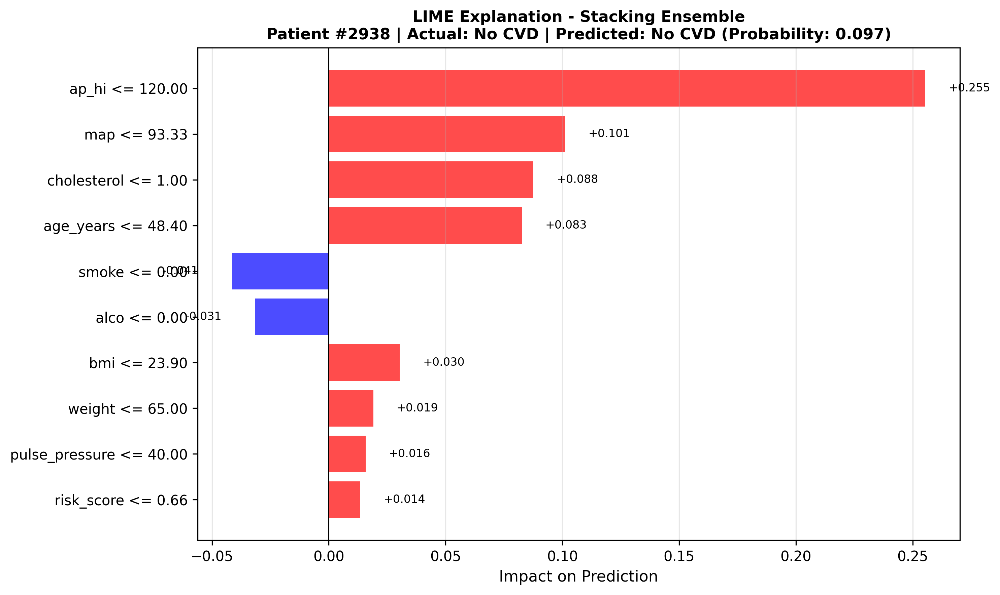


✅ Saved: lime_Stacking_Ensemble_BEST.png

✅ LIME analysis completed for Stacking Ensemble

LIME Analysis for: LightGBM

🎯 BEST SAMPLE SELECTED FOR THIS MODEL:
   Index: 238
   True Label: 1 (CVD)
   Predicted: 1 (CVD)
   Probability (CVD): 0.8267
   Confidence: 0.3267

✓ Using predict_proba for LightGBM

📋 Feature values for this patient:
   age_years           : 54.2000
   height              : 179.0000
   weight              : 115.0000
   bmi                 : 35.9000
   ap_hi               : 160.0000
   ap_lo               : 90.0000
   pulse_pressure      : 70.0000
   map                 : 113.3333
   risk_score          : 1.2590
   gender              : 2.0000
   smoke               : 0.0000
   alco                : 1.0000
   active              : 0.0000
   cholesterol         : 2.0000
   gluc                : 1.0000
   age_group_encoded   : 0.0000

⏳ Generating LIME explanation for best sample...
✓ Explanation generated

🎯 Prediction Results:
  - True Label: 1 (CVD)
  - Predicted

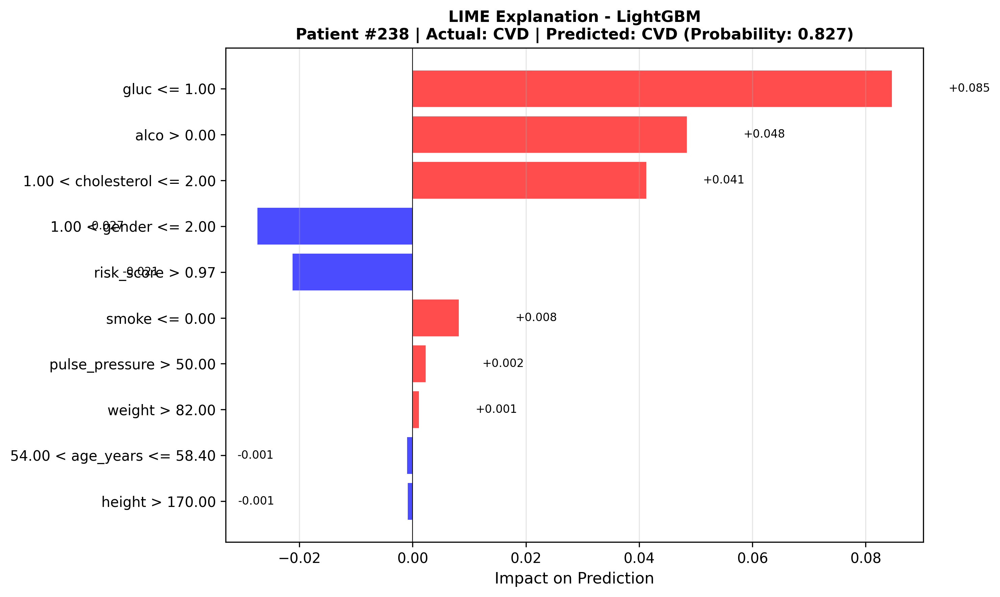


✅ Saved: lime_LightGBM_BEST.png

✅ LIME analysis completed for LightGBM

LIME Analysis for: HistGradientBoost

🎯 BEST SAMPLE SELECTED FOR THIS MODEL:
   Index: 2938
   True Label: 0 (No CVD)
   Predicted: 0 (No CVD)
   Probability (CVD): 0.0357
   Confidence: 0.4643

✓ Using predict_proba for HistGradientBoost

📋 Feature values for this patient:
   age_years           : 40.7000
   height              : 164.0000
   weight              : 50.0000
   bmi                 : 18.6000
   ap_hi               : 90.0000
   ap_lo               : 60.0000
   pulse_pressure      : 30.0000
   map                 : 70.0000
   risk_score          : 0.5860
   gender              : 1.0000
   smoke               : 0.0000
   alco                : 0.0000
   active              : 1.0000
   cholesterol         : 1.0000
   gluc                : 1.0000
   age_group_encoded   : 0.0000

⏳ Generating LIME explanation for best sample...
✓ Explanation generated

🎯 Prediction Results:
  - True Label: 0 (No CVD)
  - Pr

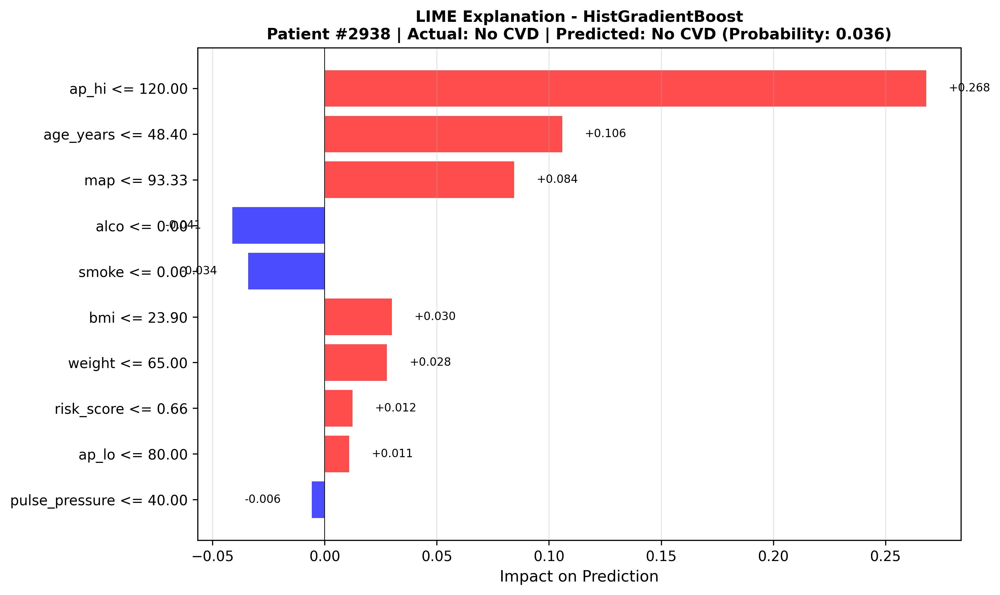


✅ Saved: lime_HistGradientBoost_BEST.png

✅ LIME analysis completed for HistGradientBoost

📋 FINAL SUMMARY - BEST SAMPLES FOR LIME

Recommended patient for each model (use for IEEE report):

   Stacking Ensemble:
      - Patient Index: 2938
      - Actual Condition: No CVD
      - Model Prediction: No CVD
      - Confidence Score: 0.4030
      - LIME Plot: lime_Stacking_Ensemble_BEST.png

   LightGBM:
      - Patient Index: 238
      - Actual Condition: CVD
      - Model Prediction: CVD
      - Confidence Score: 0.3267
      - LIME Plot: lime_LightGBM_BEST.png

   HistGradientBoost:
      - Patient Index: 2938
      - Actual Condition: No CVD
      - Model Prediction: No CVD
      - Confidence Score: 0.4643
      - LIME Plot: lime_HistGradientBoost_BEST.png

✅ LIME ANALYSIS COMPLETED FOR ALL MODELS


In [ ]:
# ============================================
# LIME ANALYSIS - USING BEST SAMPLES (SAME AS SHAP)
# ============================================

print("="*70)
print("LIME ANALYSIS - LOCAL EXPLANATIONS FOR BEST SAMPLES")
print("="*70)

import lime
import lime.lime_tabular
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Convert data to numpy if needed
X_train_np = X_train.values if hasattr(X_train, 'values') else np.array(X_train)
X_val_np = X_val.values if hasattr(X_val, 'values') else np.array(X_val)
y_val_np = y_val.values if hasattr(y_val, 'values') else np.array(y_val)

feature_names = all_features
class_names = ['No CVD', 'CVD']

print(f"\n📊 LIME Explainer Setup:")
print(f"  - Training data shape: {X_train_np.shape}")
print(f"  - Number of features: {len(feature_names)}")
print(f"  - Class names: {class_names}")

# Create LIME explainer
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_np,
    feature_names=feature_names,
    class_names=class_names,
    mode='classification',
    discretize_continuous=True,
    random_state=42
)
print(f"✓ LIME explainer created successfully")

# ============================================
# FIRST: Find best sample for EACH model
# ============================================
print("\n" + "="*50)
print("FINDING BEST SAMPLE FOR EACH MODEL")
print("="*50)

best_samples_for_lime = {}

for model_name, model in model_objects.items():
    print(f"\n📊 Analyzing {model_name}...")

    # Get predictions for ALL validation samples
    y_pred_proba_full = model.predict_proba(X_val_np)[:, 1]
    y_pred_full = (y_pred_proba_full >= 0.5).astype(int)

    # Calculate metrics for each sample
    correct_mask = (y_pred_full == y_val_np)
    confidence = np.abs(y_pred_proba_full - 0.5)  # Distance from 0.5

    # Score each sample: correct prediction + high confidence
    sample_scores = correct_mask.astype(int) * confidence

    # Find best sample (highest score)
    best_idx = np.argmax(sample_scores)
    best_confidence = confidence[best_idx]
    best_correct = correct_mask[best_idx]
    best_proba = y_pred_proba_full[best_idx]
    best_true = y_val_np[best_idx]
    best_pred = y_pred_full[best_idx]

    # Store for later use
    best_samples_for_lime[model_name] = {
        'index': best_idx,
        'true_label': best_true,
        'pred_label': best_pred,
        'probability': best_proba,
        'confidence': best_confidence,
        'correct': best_correct
    }

    print(f"   ✅ Best sample index: {best_idx}")
    print(f"   True Label: {best_true} ({'CVD' if best_true==1 else 'No CVD'})")
    print(f"   Predicted: {best_pred} ({'CVD' if best_pred==1 else 'No CVD'})")
    print(f"   Probability: {best_proba:.4f}")
    print(f"   Confidence: {best_confidence:.4f}")

# ============================================
# LIME ANALYSIS USING BEST SAMPLES
# ============================================
print("\n" + "="*70)
print("LIME ANALYSIS - USING BEST SAMPLES")
print("="*70)

for model_name, model in model_objects.items():
    print(f"\n{'='*50}")
    print(f"LIME Analysis for: {model_name}")
    print(f"{'='*50}")

    # Get the best sample for this model
    best_info = best_samples_for_lime[model_name]
    best_idx = best_info['index']
    best_true = best_info['true_label']
    best_pred = best_info['pred_label']
    best_proba = best_info['probability']

    print(f"\n🎯 BEST SAMPLE SELECTED FOR THIS MODEL:")
    print(f"   Index: {best_idx}")
    print(f"   True Label: {best_true} ({class_names[best_true]})")
    print(f"   Predicted: {best_pred} ({class_names[best_pred]})")
    print(f"   Probability (CVD): {best_proba:.4f}")
    print(f"   Confidence: {best_info['confidence']:.4f}")

    # Define prediction function for LIME
    if hasattr(model, 'predict_proba'):
        predict_fn = lambda x: model.predict_proba(x)
        print(f"\n✓ Using predict_proba for {model_name}")
    else:
        predict_fn = lambda x: model.predict(x)
        print(f"\n⚠️ Using predict (no probability) for {model_name}")

    # Get the instance
    instance = X_val_np[best_idx].reshape(1, -1)[0]

    print(f"\n📋 Feature values for this patient:")
    # Show all features with their values
    for j, feat in enumerate(feature_names):
        print(f"   {feat:20s}: {instance[j]:.4f}")

    # Generate LIME explanation
    print(f"\n⏳ Generating LIME explanation for best sample...")
    exp = lime_explainer.explain_instance(
        data_row=instance,
        predict_fn=predict_fn,
        num_features=10,
        top_labels=2
    )
    print(f"✓ Explanation generated")

    # Get prediction details
    pred_proba = predict_fn(instance.reshape(1, -1))[0]
    pred_class = 1 if pred_proba[1] > 0.5 else 0

    print(f"\n🎯 Prediction Results:")
    print(f"  - True Label: {best_true} ({class_names[best_true]})")
    print(f"  - Predicted: {pred_class} ({class_names[pred_class]})")
    print(f"  - Probability for CVD: {pred_proba[1]:.4f}")
    print(f"  - Probability for No CVD: {pred_proba[0]:.4f}")

    # Get explanation for predicted class
    exp_list = exp.as_list(label=pred_class)

    print(f"\n📊 LIME EXPLANATION (For this patient):")
    print(f"   (Positive values ↑ = INCREASES CVD risk)")
    print(f"   (Negative values ↓ = DECREASES CVD risk)")
    print(f"{'─'*65}")

    # Sort by absolute value
    exp_sorted = sorted(exp_list, key=lambda x: abs(x[1]), reverse=True)

    for j, (feat, val) in enumerate(exp_sorted):
        arrow = "↑" if val > 0 else "↓"
        direction = "INCREASES risk" if val > 0 else "DECREASES risk"
        print(f"  {j+1:2d}. {arrow} {feat:30s}: {val:+.4f} ({direction})")

    # Calculate summary statistics
    pos_sum = sum(v for f, v in exp_list if v > 0)
    neg_sum = sum(v for f, v in exp_list if v < 0)

    print(f"\n📈 Impact Summary:")
    print(f"  - Total positive impact (↑ CVD risk): +{pos_sum:.4f}")
    print(f"  - Total negative impact (↓ CVD risk): {neg_sum:.4f}")
    print(f"  - Net impact: {pos_sum + neg_sum:+.4f}")

    # ============================================
    # PLOT LIME EXPLANATION
    # ============================================
    fig, ax = plt.subplots(figsize=(10, 6))

    features = [x[0] for x in exp_list]
    values = [x[1] for x in exp_list]

    # Sort by absolute value
    sorted_idx = np.argsort(np.abs(values))
    features = [features[i] for i in sorted_idx]
    values = [values[i] for i in sorted_idx]

    # Color based on positive/negative
    colors = ['red' if v > 0 else 'blue' for v in values]

    bars = plt.barh(features, values, color=colors, alpha=0.7)
    plt.xlabel('Impact on Prediction', fontsize=11)
    plt.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    plt.grid(axis='x', alpha=0.3)

    # Add value labels on bars
    for j, (feat, val) in enumerate(zip(features, values)):
        if val > 0:
            plt.text(val + 0.01, j, f'+{val:.3f}', va='center', fontsize=8)
        else:
            plt.text(val - 0.03, j, f'{val:.3f}', va='center', fontsize=8)

    # Title with clear label
    true_text = 'CVD' if best_true == 1 else 'No CVD'
    pred_text = 'CVD' if pred_class == 1 else 'No CVD'

    plt.title(f'LIME Explanation - {model_name}\nPatient #{best_idx} | Actual: {true_text} | Predicted: {pred_text} (Probability: {best_proba:.3f})',
             fontsize=11, fontweight='bold')

    plt.tight_layout()

    # Save the figure
    filename = f'/content/drive/MyDrive/Colab Notebooks/DA/CVD/lime_{model_name.replace(" ", "_")}_BEST.png'
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"\n✅ Saved: lime_{model_name.replace(' ', '_')}_BEST.png")

    print(f"\n✅ LIME analysis completed for {model_name}")

# ============================================
# FINAL SUMMARY FOR REPORT
# ============================================
print("\n" + "="*70)
print("📋 FINAL SUMMARY - BEST SAMPLES FOR LIME")
print("="*70)

print("\nRecommended patient for each model (use for IEEE report):")
for model_name, sample_info in best_samples_for_lime.items():
    print(f"\n   {model_name}:")
    print(f"      - Patient Index: {sample_info['index']}")
    print(f"      - Actual Condition: {'CVD' if sample_info['true_label']==1 else 'No CVD'}")
    print(f"      - Model Prediction: {'CVD' if sample_info['pred_label']==1 else 'No CVD'}")
    print(f"      - Confidence Score: {sample_info['confidence']:.4f}")
    print(f"      - LIME Plot: lime_{model_name.replace(' ', '_')}_BEST.png")

print("\n" + "="*70)
print("✅ LIME ANALYSIS COMPLETED FOR ALL MODELS")
print("="*70)

**GRAD-CAM ANALYSIS **

GRAD-CAM INSPIRED FEATURE INFLUENCE ANALYSIS - BEST SAMPLES

FINDING BEST SAMPLE FOR EACH MODEL

📊 Analyzing Stacking Ensemble...
   ✅ Best sample index: 2938
   True Label: 0 (No CVD)
   Predicted: 0 (No CVD)
   Probability: 0.0970
   Confidence: 0.4030

📊 Analyzing LightGBM...
   ✅ Best sample index: 238
   True Label: 1 (CVD)
   Predicted: 1 (CVD)
   Probability: 0.8267
   Confidence: 0.3267

📊 Analyzing HistGradientBoost...
   ✅ Best sample index: 2938
   True Label: 0 (No CVD)
   Predicted: 0 (No CVD)
   Probability: 0.0357
   Confidence: 0.4643

GRAD-CAM ANALYSIS - USING BEST SAMPLES

Feature Influence Analysis for: Stacking Ensemble

🎯 USING BEST SAMPLE: Index 2938
   Actual: 0 (No CVD)
   Predicted: 0 (No CVD)
   Probability: 0.0970

📊 Computing Permutation Importance...

🔝 Permutation Importance Results (Top 10):
─────────────────────────────────────────────────────────────────
Feature                   Importance      Std Dev     
─────────────────────────────────────────────

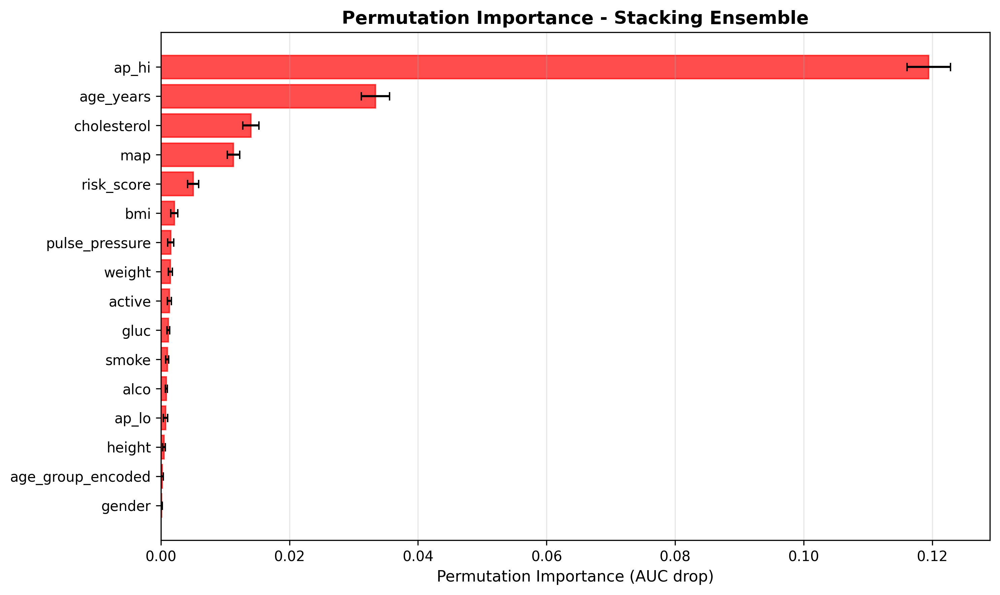

✅ Saved: perm_importance_Stacking_Ensemble.png

🗺️ Creating Feature Influence Map (Grad-CAM Style)...
  - Using permutation importance as proxy


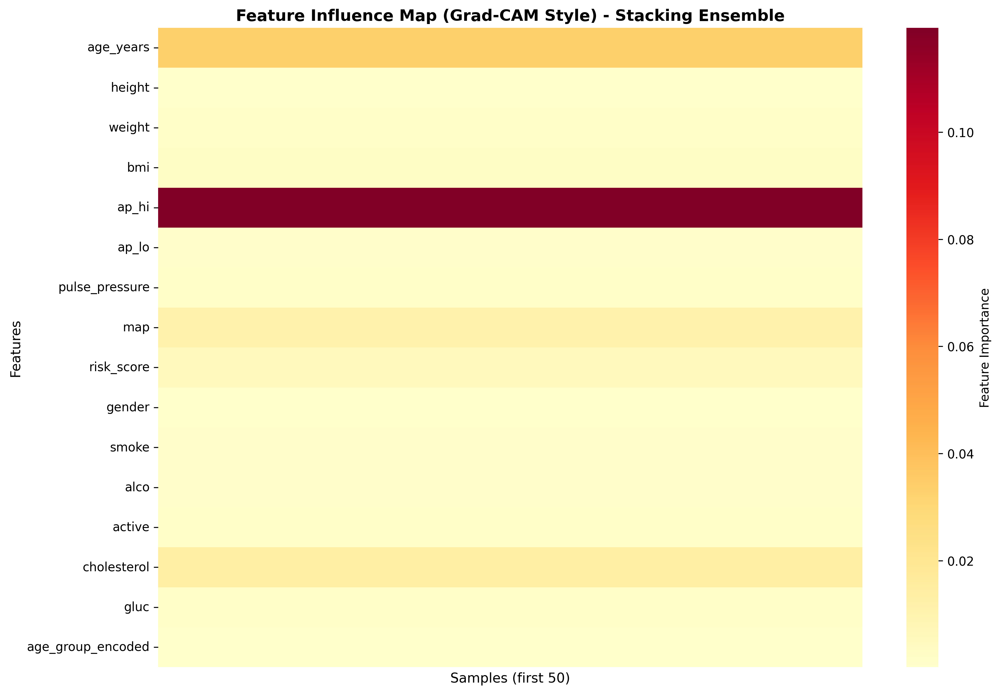

✅ Saved: feature_map_Stacking_Ensemble.png

🔍 Analyzing BEST SAMPLE (Index: 2938)...
──────────────────────────────────────────────────
BEST SAMPLE DETAILS:
──────────────────────────────────────────────────
  - Actual: 0 (No CVD)
  - Predicted probability for CVD: 0.0970
  - Predicted class: 0
  - Confidence: 0.4030
  - Using permutation importance for influence calculation

📊 ALL FEATURES - Influence for this patient:
─────────────────────────────────────────────────────────────────
Feature                   Value        Influence    Impact
─────────────────────────────────────────────────────────────────
🔴 ap_hi                    :  90.0000   +10.751158   ↑ INCREASES risk
🔴 age_years                :  40.7000   +1.358567   ↑ INCREASES risk
🔴 map                      :  70.0000   +0.790183   ↑ INCREASES risk
🔴 height                   : 164.0000   +0.076516   ↑ INCREASES risk
🔴 weight                   :  50.0000   +0.073501   ↑ INCREASES risk
🔴 pulse_pressure           :  30.0000  

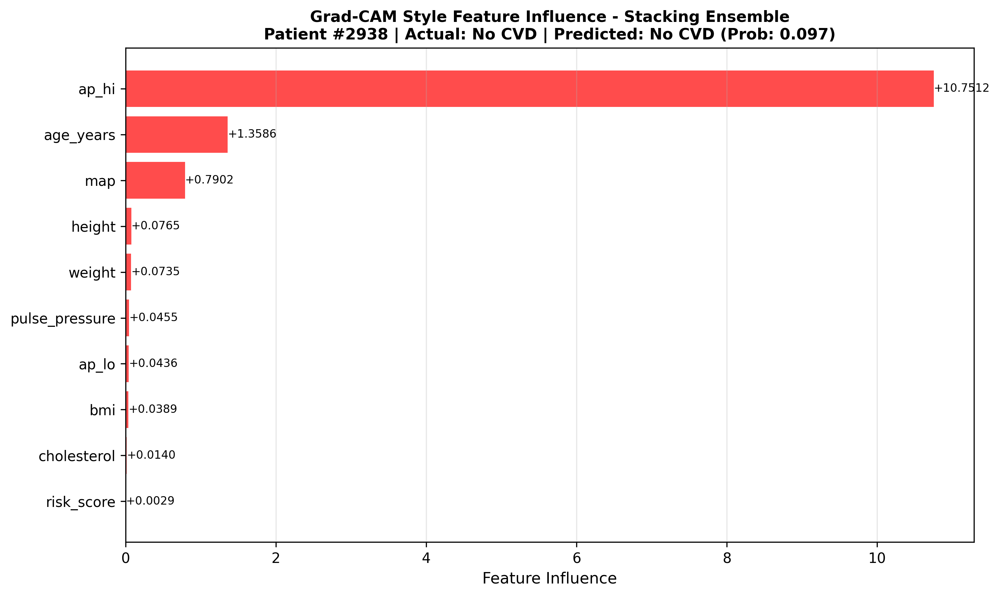


✅ Saved: gradcam_style_Stacking_Ensemble_BEST.png

✅ Feature influence analysis completed for Stacking Ensemble

Feature Influence Analysis for: LightGBM

🎯 USING BEST SAMPLE: Index 238
   Actual: 1 (CVD)
   Predicted: 1 (CVD)
   Probability: 0.8267

📊 Computing Permutation Importance...

🔝 Permutation Importance Results (Top 10):
─────────────────────────────────────────────────────────────────
Feature                   Importance      Std Dev     
─────────────────────────────────────────────────────────────────
🔴 cholesterol              : 0.033339 ± 0.001678
🔴 smoke                    : 0.001398 ± 0.000841
🟢 age_years                : 0.000000 ± 0.000000
🟢 height                   : 0.000000 ± 0.000000
🟢 ap_hi                    : 0.000000 ± 0.000000
🟢 ap_lo                    : 0.000000 ± 0.000000
🟢 weight                   : 0.000000 ± 0.000000
🟢 bmi                      : 0.000000 ± 0.000000
🟢 map                      : 0.000000 ± 0.000000
🟢 pulse_pressure           : 0.000000 

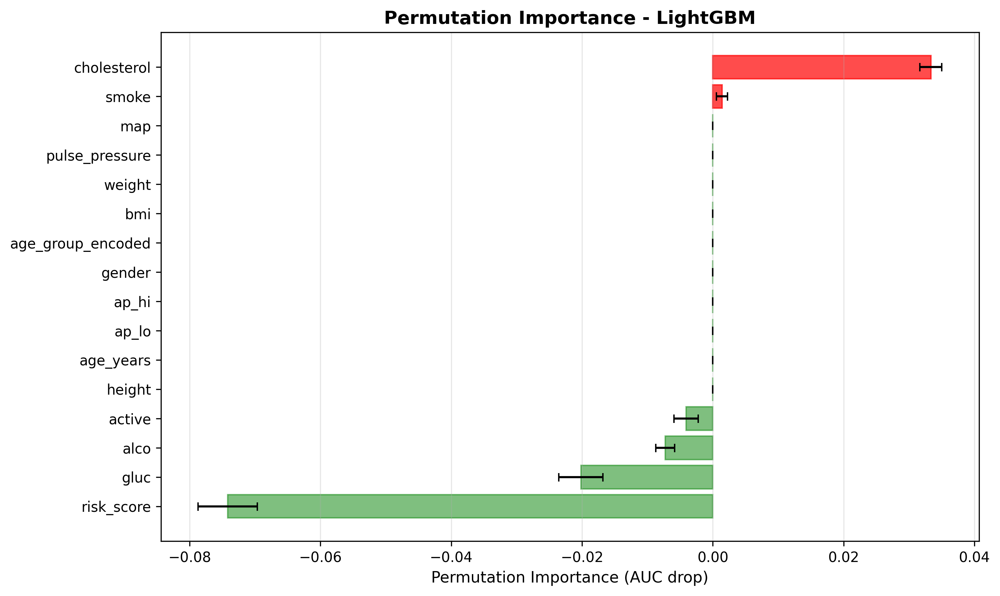

✅ Saved: perm_importance_LightGBM.png

🗺️ Creating Feature Influence Map (Grad-CAM Style)...
  - Using model's built-in feature_importances_


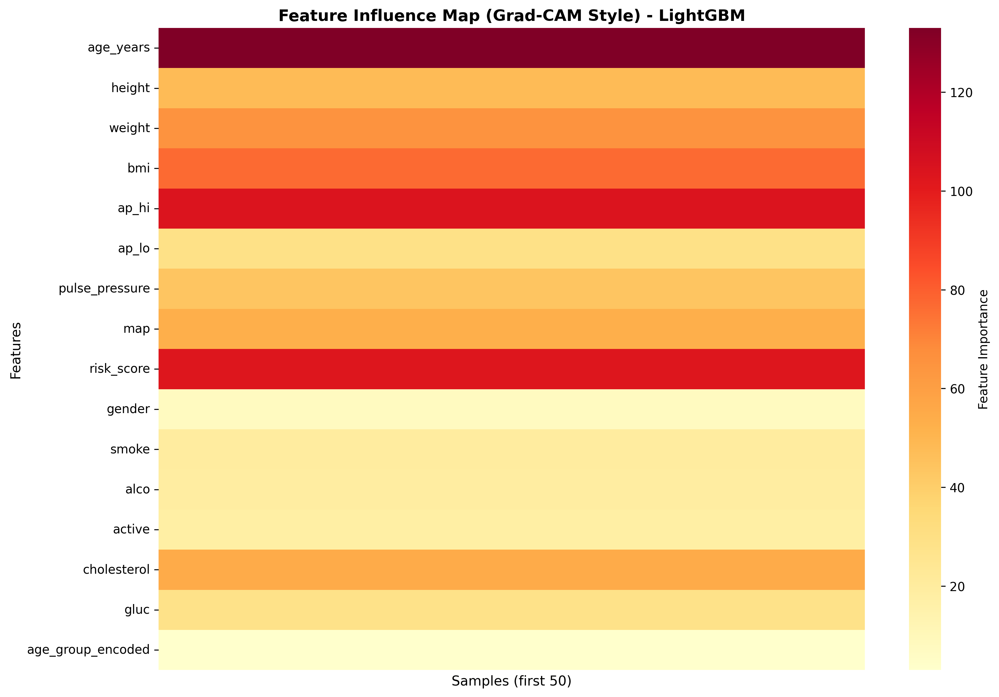

✅ Saved: feature_map_LightGBM.png

🔍 Analyzing BEST SAMPLE (Index: 238)...
──────────────────────────────────────────────────
BEST SAMPLE DETAILS:
──────────────────────────────────────────────────
  - Actual: 1 (CVD)
  - Predicted probability for CVD: 0.8267
  - Predicted class: 1
  - Confidence: 0.3267
  - Using feature_importances_ for influence calculation

📊 ALL FEATURES - Influence for this patient:
─────────────────────────────────────────────────────────────────
Feature                   Value        Influence    Impact
─────────────────────────────────────────────────────────────────
🔴 ap_hi                    : 160.0000   +16640.000000   ↑ INCREASES risk
🔴 height                   : 179.0000   +8592.000000   ↑ INCREASES risk
🔴 weight                   : 115.0000   +7475.000000   ↑ INCREASES risk
🔴 age_years                :  54.2000   +7208.600000   ↑ INCREASES risk
🔴 map                      : 113.3333   +6006.666667   ↑ INCREASES risk
🔴 pulse_pressure           :  70.0000  

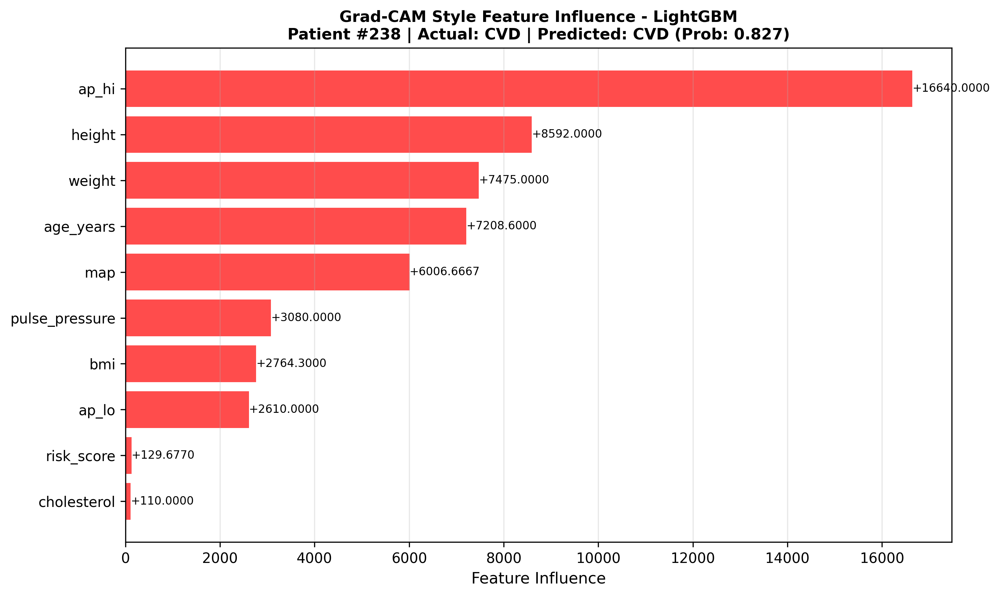


✅ Saved: gradcam_style_LightGBM_BEST.png

✅ Feature influence analysis completed for LightGBM

Feature Influence Analysis for: HistGradientBoost

🎯 USING BEST SAMPLE: Index 2938
   Actual: 0 (No CVD)
   Predicted: 0 (No CVD)
   Probability: 0.0357

📊 Computing Permutation Importance...

🔝 Permutation Importance Results (Top 10):
─────────────────────────────────────────────────────────────────
Feature                   Importance      Std Dev     
─────────────────────────────────────────────────────────────────
🔴 ap_hi                    : 0.153149 ± 0.003947
🔴 age_years                : 0.035909 ± 0.002179
🔴 cholesterol              : 0.019713 ± 0.001446
🔴 map                      : 0.006599 ± 0.000922
🔴 risk_score               : 0.003810 ± 0.000463
🔴 bmi                      : 0.002219 ± 0.000347
🔴 weight                   : 0.001863 ± 0.000474
🔴 active                   : 0.001505 ± 0.000347
🔴 gluc                     : 0.001284 ± 0.000115
🔴 smoke                    : 0.001169 ± 

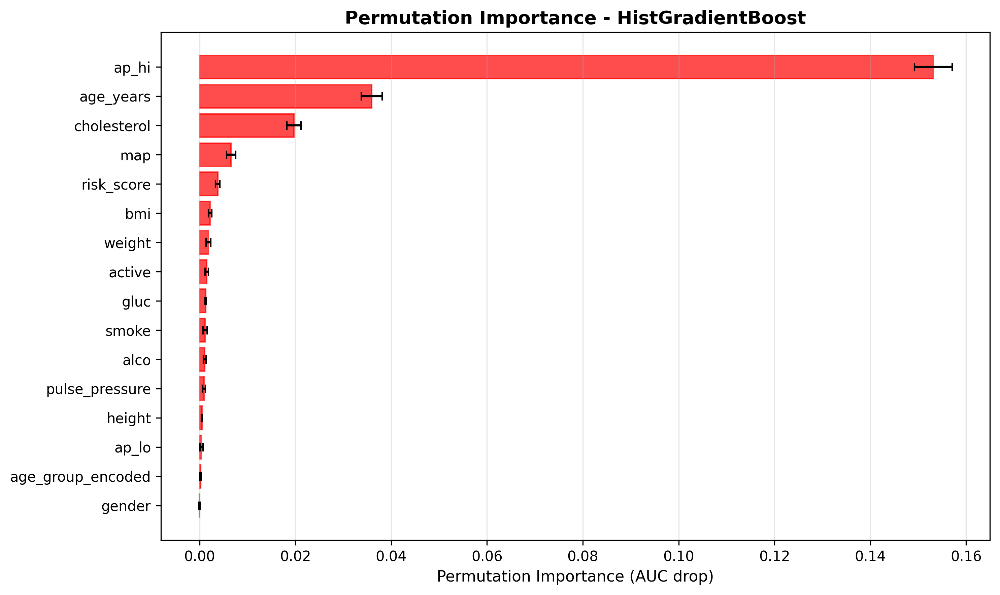

✅ Saved: perm_importance_HistGradientBoost.png

🗺️ Creating Feature Influence Map (Grad-CAM Style)...
  - Using permutation importance as proxy


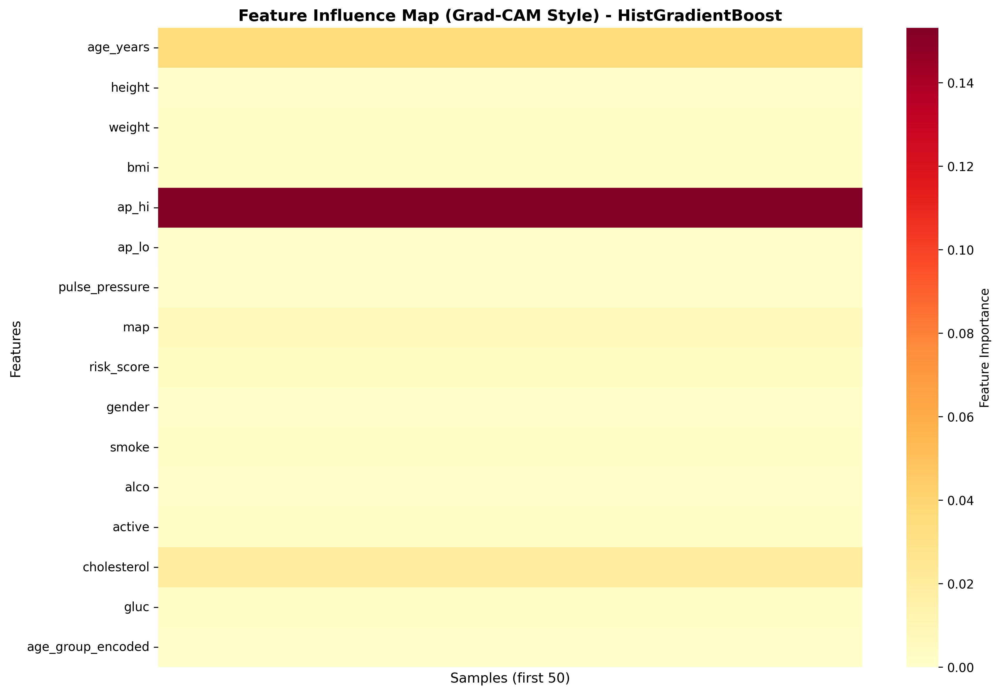

✅ Saved: feature_map_HistGradientBoost.png

🔍 Analyzing BEST SAMPLE (Index: 2938)...
──────────────────────────────────────────────────
BEST SAMPLE DETAILS:
──────────────────────────────────────────────────
  - Actual: 0 (No CVD)
  - Predicted probability for CVD: 0.0357
  - Predicted class: 0
  - Confidence: 0.4643
  - Using permutation importance for influence calculation

📊 ALL FEATURES - Influence for this patient:
─────────────────────────────────────────────────────────────────
Feature                   Value        Influence    Impact
─────────────────────────────────────────────────────────────────
🔴 ap_hi                    :  90.0000   +13.783444   ↑ INCREASES risk
🔴 age_years                :  40.7000   +1.461509   ↑ INCREASES risk
🔴 map                      :  70.0000   +0.461934   ↑ INCREASES risk
🔴 weight                   :  50.0000   +0.093152   ↑ INCREASES risk
🔴 height                   : 164.0000   +0.082993   ↑ INCREASES risk
🔴 bmi                      :  18.6000  

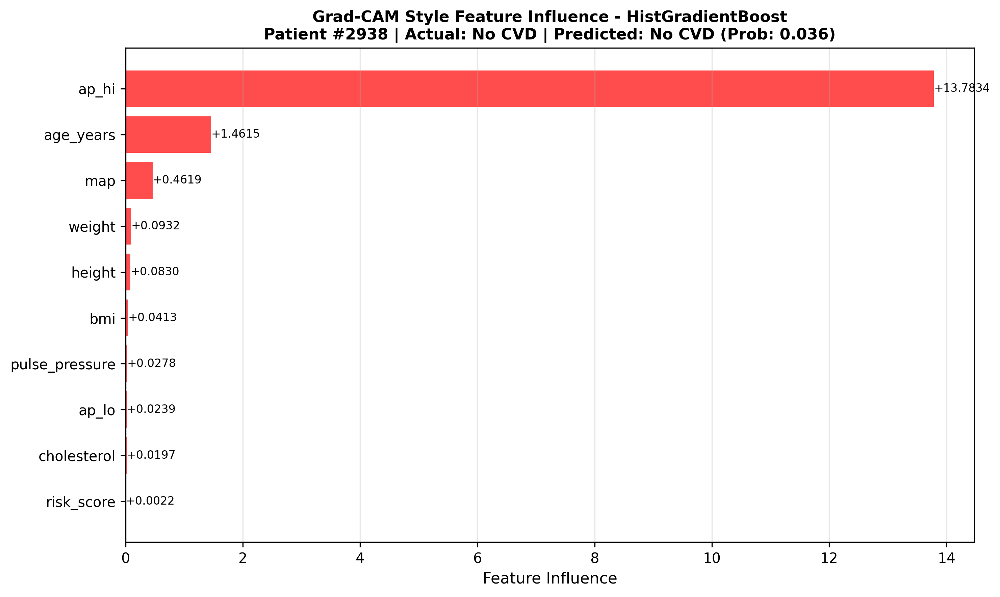


✅ Saved: gradcam_style_HistGradientBoost_BEST.png

✅ Feature influence analysis completed for HistGradientBoost

📋 FINAL SUMMARY - GRAD-CAM ANALYSIS

Recommended best sample for each model:

   Stacking Ensemble:
      - Patient Index: 2938
      - Actual: No CVD
      - Predicted: No CVD
      - Confidence: 0.4030
      - Grad-CAM Plot: gradcam_style_Stacking_Ensemble_BEST.png

   LightGBM:
      - Patient Index: 238
      - Actual: CVD
      - Predicted: CVD
      - Confidence: 0.3267
      - Grad-CAM Plot: gradcam_style_LightGBM_BEST.png

   HistGradientBoost:
      - Patient Index: 2938
      - Actual: No CVD
      - Predicted: No CVD
      - Confidence: 0.4643
      - Grad-CAM Plot: gradcam_style_HistGradientBoost_BEST.png

✅ GRAD-CAM ANALYSIS COMPLETED FOR ALL MODELS


In [ ]:
# ============================================
# GRAD-CAM INSPIRED FEATURE INFLUENCE MAPS - USING BEST SAMPLES
# ============================================

print("="*70)
print("GRAD-CAM INSPIRED FEATURE INFLUENCE ANALYSIS - BEST SAMPLES")
print("="*70)

from sklearn.inspection import permutation_importance
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Convert to numpy for consistent handling
X_val_np = X_val.values if hasattr(X_val, 'values') else np.array(X_val)
y_val_np = y_val.values if hasattr(y_val, 'values') else np.array(y_val)

# First find best sample for each model
print("\n" + "="*50)
print("FINDING BEST SAMPLE FOR EACH MODEL")
print("="*50)

best_samples_for_gradcam = {}

for model_name, model in model_objects.items():
    print(f"\n📊 Analyzing {model_name}...")

    # Get predictions for ALL validation samples
    y_pred_proba_full = model.predict_proba(X_val_np)[:, 1]
    y_pred_full = (y_pred_proba_full >= 0.5).astype(int)

    # Calculate metrics for each sample
    correct_mask = (y_pred_full == y_val_np)
    confidence = np.abs(y_pred_proba_full - 0.5)  # Distance from 0.5

    # Score each sample: correct prediction + high confidence
    sample_scores = correct_mask.astype(int) * confidence

    # Find best sample (highest score)
    best_idx = np.argmax(sample_scores)
    best_confidence = confidence[best_idx]
    best_correct = correct_mask[best_idx]
    best_proba = y_pred_proba_full[best_idx]
    best_true = y_val_np[best_idx]
    best_pred = y_pred_full[best_idx]

    # Store for later use
    best_samples_for_gradcam[model_name] = {
        'index': best_idx,
        'true_label': best_true,
        'pred_label': best_pred,
        'probability': best_proba,
        'confidence': best_confidence,
        'correct': best_correct
    }

    print(f"   ✅ Best sample index: {best_idx}")
    print(f"   True Label: {best_true} ({'CVD' if best_true==1 else 'No CVD'})")
    print(f"   Predicted: {best_pred} ({'CVD' if best_pred==1 else 'No CVD'})")
    print(f"   Probability: {best_proba:.4f}")
    print(f"   Confidence: {best_confidence:.4f}")

# Now run Grad-CAM analysis using best samples
print("\n" + "="*70)
print("GRAD-CAM ANALYSIS - USING BEST SAMPLES")
print("="*70)

class_names = ['No CVD', 'CVD']

for model_name, model in model_objects.items():
    print(f"\n{'='*50}")
    print(f"Feature Influence Analysis for: {model_name}")
    print(f"{'='*50}")

    # Get best sample info
    best_info = best_samples_for_gradcam[model_name]
    best_idx = best_info['index']

    print(f"\n🎯 USING BEST SAMPLE: Index {best_idx}")
    print(f"   Actual: {best_info['true_label']} ({'CVD' if best_info['true_label']==1 else 'No CVD'})")
    print(f"   Predicted: {best_info['pred_label']} ({'CVD' if best_info['pred_label']==1 else 'No CVD'})")
    print(f"   Probability: {best_info['probability']:.4f}")

    # ============================================
    # 1. Permutation Importance (global)
    # ============================================
    print(f"\n📊 Computing Permutation Importance...")
    perm_importance = permutation_importance(
        model, X_val_np, y_val_np,
        n_repeats=10,
        random_state=42,
        scoring='roc_auc'
    )

    # Create dataframe
    perm_df = pd.DataFrame({
        'feature': all_features,
        'importance': perm_importance.importances_mean,
        'std': perm_importance.importances_std
    }).sort_values('importance', ascending=False)

    print(f"\n🔝 Permutation Importance Results (Top 10):")
    print(f"{'─'*65}")
    print(f"{'Feature':25s} {'Importance':15s} {'Std Dev':12s}")
    print(f"{'─'*65}")
    for idx, row in perm_df.head(10).iterrows():
        arrow = "🔴" if row['importance'] > 0 else "🟢"
        print(f"{arrow} {row['feature']:25s}: {row['importance']:.6f} ± {row['std']:.6f}")

    # Plot permutation importance (sorted ascending for horizontal bar)
    perm_df_plot = perm_df.sort_values('importance', ascending=True)
    plt.figure(figsize=(10, 6))
    bars = plt.barh(perm_df_plot['feature'], perm_df_plot['importance'],
                    xerr=perm_df_plot['std'], capsize=3, alpha=0.7)

    # Color bars based on importance
    for bar, imp in zip(bars, perm_df_plot['importance']):
        if imp > 0:
            bar.set_color('red')
            bar.set_alpha(0.7)
        else:
            bar.set_color('green')
            bar.set_alpha(0.5)

    plt.xlabel('Permutation Importance (AUC drop)', fontsize=11)
    plt.title(f'Permutation Importance - {model_name}', fontsize=13, fontweight='bold')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'/content/drive/MyDrive/Colab Notebooks/DA/CVD/perm_importance_{model_name.replace(" ", "_")}.png',
                dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: perm_importance_{model_name.replace(' ', '_')}.png")

    # ============================================
    # 2. Feature Influence Map (Grad-CAM Style) - Global
    # ============================================
    print(f"\n🗺️ Creating Feature Influence Map (Grad-CAM Style)...")

    if hasattr(model, 'feature_importances_'):
        importance_matrix = np.tile(model.feature_importances_, (len(X_val_np[:50]), 1))
        print(f"  - Using model's built-in feature_importances_")
    else:
        importance_matrix = np.tile(perm_importance.importances_mean, (len(X_val_np[:50]), 1))
        print(f"  - Using permutation importance as proxy")

    # Create heatmap
    plt.figure(figsize=(12, 8))
    sns.heatmap(importance_matrix.T,
                xticklabels=False,
                yticklabels=all_features,
                cmap='YlOrRd',
                cbar_kws={'label': 'Feature Importance'},
                annot=False)
    plt.xlabel('Samples (first 50)', fontsize=11)
    plt.ylabel('Features', fontsize=11)
    plt.title(f'Feature Influence Map (Grad-CAM Style) - {model_name}', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'/content/drive/MyDrive/Colab Notebooks/DA/CVD/feature_map_{model_name.replace(" ", "_")}.png',
                dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: feature_map_{model_name.replace(' ', '_')}.png")

    # ============================================
    # 3. BEST SAMPLE - Individual feature influence (Grad-CAM style)
    # ============================================
    print(f"\n🔍 Analyzing BEST SAMPLE (Index: {best_idx})...")

    print(f"{'─'*50}")
    print(f"BEST SAMPLE DETAILS:")
    print(f"{'─'*50}")

    # Get prediction for best sample
    X_instance = X_val_np[best_idx].reshape(1, -1)
    pred = model.predict_proba(X_instance)[0]
    actual = best_info['true_label']

    print(f"  - Actual: {actual} ({'CVD' if actual==1 else 'No CVD'})")
    print(f"  - Predicted probability for CVD: {pred[1]:.4f}")
    print(f"  - Predicted class: {1 if pred[1] > 0.5 else 0}")
    print(f"  - Confidence: {best_info['confidence']:.4f}")

    # Create influence values (feature values * importance)
    if hasattr(model, 'feature_importances_'):
        influence = X_val_np[best_idx] * model.feature_importances_
        importance_source = "feature_importances_"
    else:
        influence = X_val_np[best_idx] * perm_importance.importances_mean
        importance_source = "permutation importance"

    print(f"  - Using {importance_source} for influence calculation")

    # Sort by influence
    sort_idx = np.argsort(np.abs(influence))
    features_sorted = [all_features[j] for j in sort_idx[-10:]]
    influence_sorted = influence[sort_idx[-10:]]

    # Print all feature influences for best sample
    print(f"\n📊 ALL FEATURES - Influence for this patient:")
    print(f"{'─'*65}")
    print(f"{'Feature':25s} {'Value':12s} {'Influence':12s} {'Impact'}")
    print(f"{'─'*65}")

    all_influence_idx = np.argsort(np.abs(influence))[::-1]  # Sort descending
    for j in all_influence_idx:
        feat = all_features[j]
        feat_value = X_val_np[best_idx][j]
        inf = influence[j]
        direction = "↑ INCREASES risk" if inf > 0 else "↓ DECREASES risk"
        color = "🔴" if inf > 0 else "🟢"
        print(f"{color} {feat:25s}: {feat_value:8.4f}   {inf:+.6f}   {direction}")

    # Print top influencing features summary
    print(f"\n📊 TOP 10 features by influence for this patient:")
    print(f"{'─'*60}")
    print(f"{'Feature':25s} {'Influence':12s} {'Impact'}")
    print(f"{'─'*60}")

    for j in range(len(features_sorted)-1, -1, -1):
        feat = features_sorted[j]
        inf = influence_sorted[j]
        direction = "↑ INCREASES risk" if inf > 0 else "↓ DECREASES risk"
        color = "🔴" if inf > 0 else "🟢"
        print(f"{color} {feat:25s}: {inf:+.6f}  {direction}")

    # Calculate summary
    pos_sum = sum(influence_sorted[influence_sorted > 0])
    neg_sum = sum(influence_sorted[influence_sorted < 0])

    print(f"\n📈 Influence Summary for this patient:")
    print(f"  - Total positive influence (↑ CVD risk): +{pos_sum:.6f}")
    print(f"  - Total negative influence (↓ CVD risk): {neg_sum:.6f}")
    print(f"  - Net influence: {pos_sum + neg_sum:+.6f}")
    print(f"  - Base probability (approx): {pred[1] - (pos_sum + neg_sum):.4f}")

    # Plot for BEST SAMPLE
    plt.figure(figsize=(10, 6))

    # Color based on sign
    colors = ['red' if v > 0 else 'blue' for v in influence_sorted]

    bars = plt.barh(features_sorted, influence_sorted, color=colors, alpha=0.7)

    # Add value labels
    for bar in bars:
        width = bar.get_width()
        if width > 0:
            plt.text(width + 0.001, bar.get_y() + bar.get_height()/2,
                    f'+{width:.4f}', va='center', fontsize=8)
        else:
            plt.text(width - 0.003, bar.get_y() + bar.get_height()/2,
                    f'{width:.4f}', va='center', fontsize=8, ha='right')

    plt.xlabel('Feature Influence', fontsize=11)
    actual_text = 'CVD' if actual == 1 else 'No CVD'
    pred_text = 'CVD' if pred[1] > 0.5 else 'No CVD'

    plt.title(f'Grad-CAM Style Feature Influence - {model_name}\nPatient #{best_idx} | Actual: {actual_text} | Predicted: {pred_text} (Prob: {pred[1]:.3f})',
             fontsize=11, fontweight='bold')
    plt.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()

    filename = f'/content/drive/MyDrive/Colab Notebooks/DA/CVD/gradcam_style_{model_name.replace(" ", "_")}_BEST.png'
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"\n✅ Saved: gradcam_style_{model_name.replace(' ', '_')}_BEST.png")

    print(f"\n✅ Feature influence analysis completed for {model_name}")

# ============================================
# FINAL SUMMARY FOR REPORT
# ============================================
print("\n" + "="*70)
print("📋 FINAL SUMMARY - GRAD-CAM ANALYSIS")
print("="*70)

print("\nRecommended best sample for each model:")
for model_name, sample_info in best_samples_for_gradcam.items():
    print(f"\n   {model_name}:")
    print(f"      - Patient Index: {sample_info['index']}")
    print(f"      - Actual: {'CVD' if sample_info['true_label']==1 else 'No CVD'}")
    print(f"      - Predicted: {'CVD' if sample_info['pred_label']==1 else 'No CVD'}")
    print(f"      - Confidence: {sample_info['confidence']:.4f}")
    print(f"      - Grad-CAM Plot: gradcam_style_{model_name.replace(' ', '_')}_BEST.png")

print("\n" + "="*70)
print("✅ GRAD-CAM ANALYSIS COMPLETED FOR ALL MODELS")
print("="*70)

**ABLATION STUDY**

ABLATION STUDY - FEATURE IMPORTANCE VIA REMOVAL

📊 Total models to analyze: 3
Features being analyzed: ['age_years', 'height', 'weight', 'bmi', 'ap_hi', 'ap_lo', 'pulse_pressure', 'map', 'risk_score', 'gender', 'smoke', 'alco', 'active', 'cholesterol', 'gluc', 'age_group_encoded']

ABLATION STUDY for: Stacking Ensemble
⚠️ No built-in feature importance, computing permutation importance...
✓ Permutation importance computed

🔝 Feature ranking (most to least important):
────────────────────────────────────────────────────────────
Rank  Feature                   Importance Score
────────────────────────────────────────────────────────────
   1.  ap_hi                     0.117332
   2.  age_years                 0.022745
   3.  cholesterol               0.017370
   4.  map                       0.005566
   5.  risk_score                0.003033
   6.  weight                    0.001881
   7.  bmi                       0.001612
   8.  ap_lo                     0.001228
   9.  active        

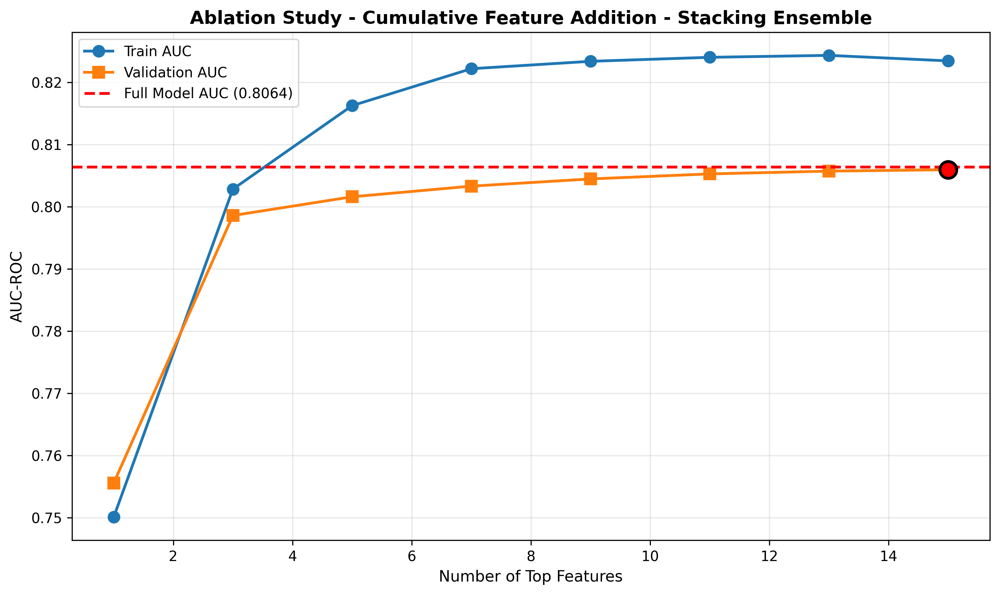

✅ Saved: ablation_cumulative_Stacking_Ensemble.png

2. INDIVIDUAL FEATURE REMOVAL
----------------------------------------

🔍 Testing removal of each feature (baseline AUC = 0.8064):

──────────────────────────────────────────────────────────────────────
Feature                   AUC without  AUC Drop     Impact    
──────────────────────────────────────────────────────────────────────
  Without age_years           : 0.8014      +0.0050      🟢 LOW
  Without height              : 0.8060      +0.0003      🟢 LOW
  Without weight              : 0.8062      +0.0002      🟢 LOW
  Without bmi                 : 0.8059      +0.0005      🟢 LOW
  Without ap_hi               : 0.8064      +0.0000      🟢 LOW
  Without ap_lo               : 0.8061      +0.0002      🟢 LOW
  Without pulse_pressure      : 0.8061      +0.0003      🟢 LOW
  Without map                 : 0.8065      -0.0001      ⚪ NEGATIVE
  Without risk_score          : 0.8064      +0.0000      🟢 LOW
  Without gender              : 0.8060 

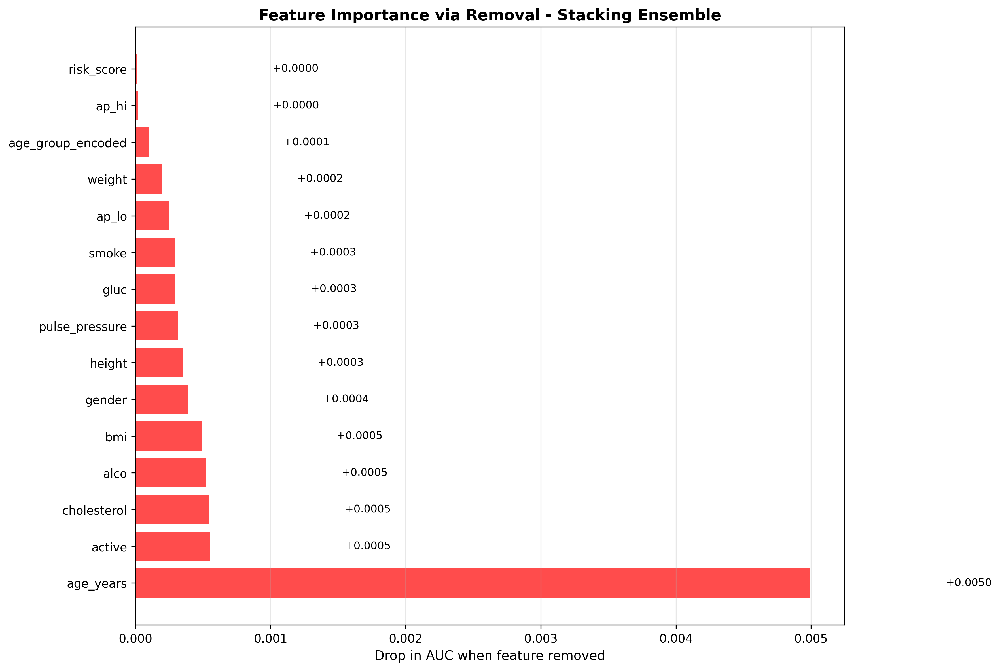

✅ Saved: ablation_removal_Stacking_Ensemble.png

✅ Ablation study completed for Stacking Ensemble

ABLATION STUDY for: LightGBM
✓ Using model's built-in feature importances
  Importance range: [3.0000, 133.0000]

🔝 Feature ranking (most to least important):
────────────────────────────────────────────────────────────
Rank  Feature                   Importance Score
────────────────────────────────────────────────────────────
   1.  age_years                 133.000000
   2.  ap_hi                     104.000000
   3.  risk_score                103.000000
   4.  bmi                       77.000000
   5.  weight                    65.000000
   6.  cholesterol               55.000000
   7.  map                       53.000000
   8.  height                    48.000000
   9.  pulse_pressure            44.000000
  10.  ap_lo                     29.000000
      ... and 6 more features

1. CUMULATIVE FEATURE ADDITION
----------------------------------------

📈 Testing feature subsets with siz

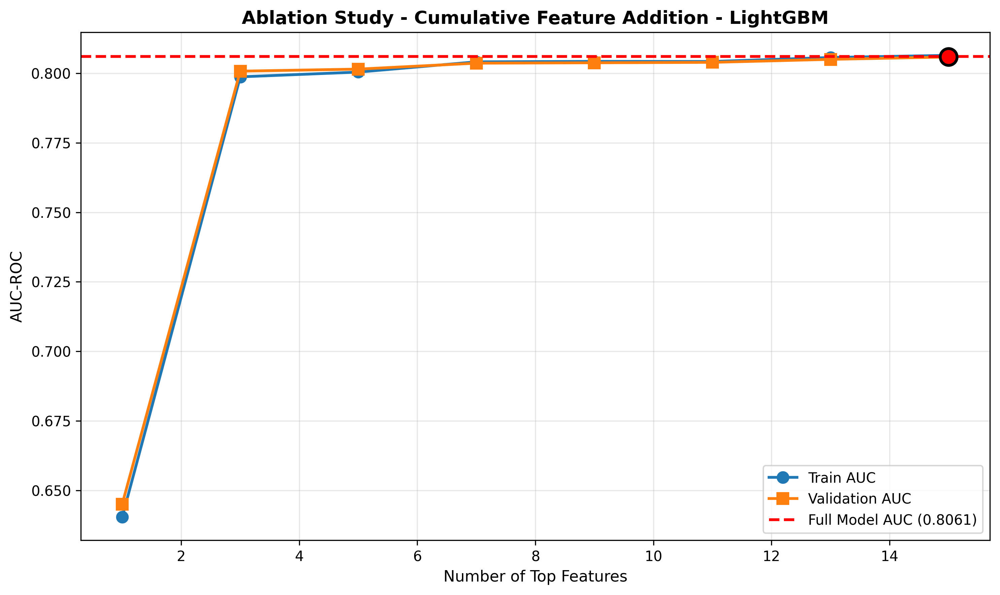

✅ Saved: ablation_cumulative_LightGBM.png

2. INDIVIDUAL FEATURE REMOVAL
----------------------------------------

🔍 Testing removal of each feature (baseline AUC = 0.8061):

──────────────────────────────────────────────────────────────────────
Feature                   AUC without  AUC Drop     Impact    
──────────────────────────────────────────────────────────────────────
  Without age_years           : 0.8008      +0.0053      🟡 MEDIUM
  Without height              : 0.8059      +0.0002      🟢 LOW
  Without weight              : 0.8058      +0.0003      🟢 LOW
  Without bmi                 : 0.8060      +0.0000      🟢 LOW
  Without ap_hi               : 0.8059      +0.0002      🟢 LOW
  Without ap_lo               : 0.8059      +0.0002      🟢 LOW
  Without pulse_pressure      : 0.8054      +0.0007      🟢 LOW
  Without map                 : 0.8057      +0.0004      🟢 LOW
  Without risk_score          : 0.8061      +0.0000      🟢 LOW
  Without gender              : 0.8058      +0.000

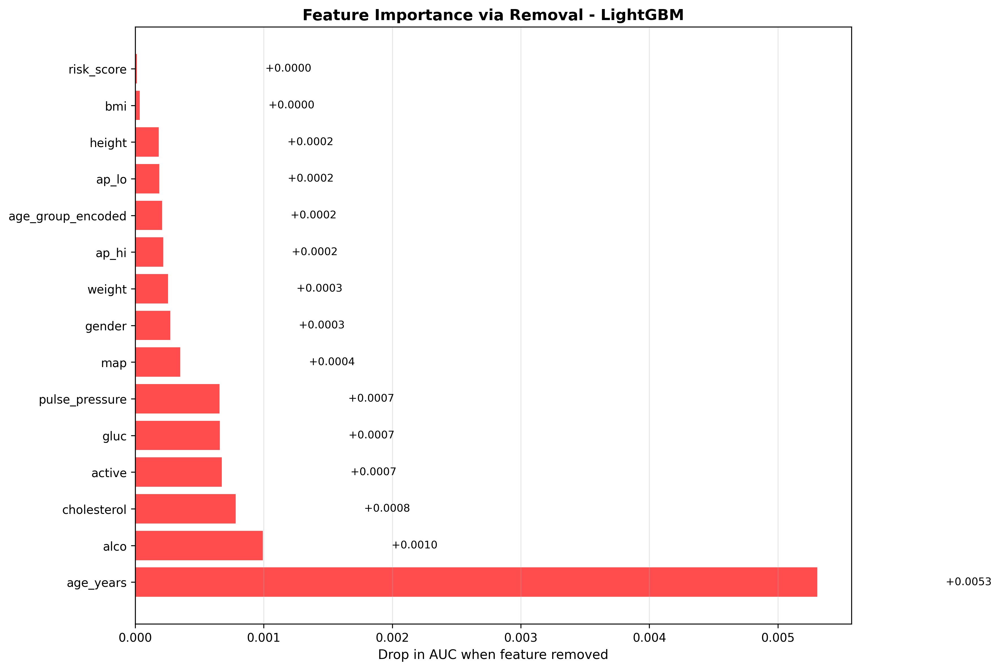

✅ Saved: ablation_removal_LightGBM.png

✅ Ablation study completed for LightGBM

ABLATION STUDY for: HistGradientBoost
⚠️ No built-in feature importance, computing permutation importance...
✓ Permutation importance computed

🔝 Feature ranking (most to least important):
────────────────────────────────────────────────────────────
Rank  Feature                   Importance Score
────────────────────────────────────────────────────────────
   1.  ap_hi                     0.134127
   2.  age_years                 0.024875
   3.  cholesterol               0.022879
   4.  bmi                       0.002879
   5.  map                       0.002092
   6.  active                    0.001017
   7.  smoke                     0.000729
   8.  ap_lo                     0.000518
   9.  gluc                      0.000384
  10.  gender                    0.000058
      ... and 6 more features

1. CUMULATIVE FEATURE ADDITION
----------------------------------------

📈 Testing feature subsets with size

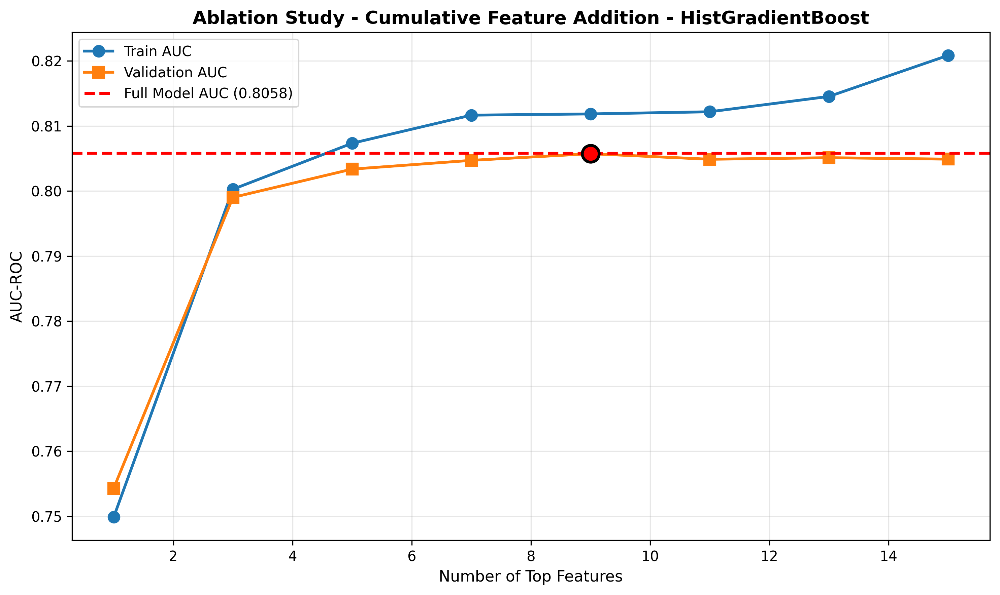

✅ Saved: ablation_cumulative_HistGradientBoost.png

2. INDIVIDUAL FEATURE REMOVAL
----------------------------------------

🔍 Testing removal of each feature (baseline AUC = 0.8058):

──────────────────────────────────────────────────────────────────────
Feature                   AUC without  AUC Drop     Impact    
──────────────────────────────────────────────────────────────────────
  Without age_years           : 0.8000      +0.0058      🟡 MEDIUM
  Without height              : 0.8049      +0.0009      🟢 LOW
  Without weight              : 0.8057      +0.0001      🟢 LOW
  Without bmi                 : 0.8059      -0.0001      ⚪ NEGATIVE
  Without ap_hi               : 0.8050      +0.0008      🟢 LOW
  Without ap_lo               : 0.8051      +0.0007      🟢 LOW
  Without pulse_pressure      : 0.8054      +0.0004      🟢 LOW
  Without map                 : 0.8069      -0.0011      ⚪ NEGATIVE
  Without risk_score          : 0.8061      -0.0003      ⚪ NEGATIVE
  Without gender          

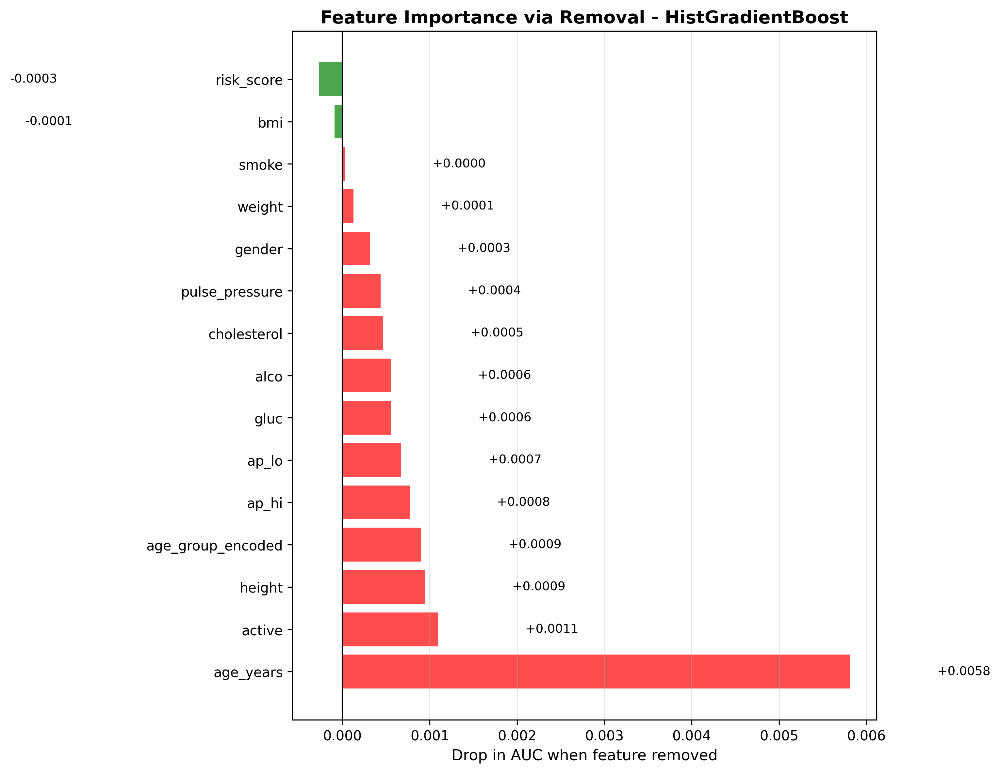

✅ Saved: ablation_removal_HistGradientBoost.png

✅ Ablation study completed for HistGradientBoost

ABLATION STUDY SUMMARY - ALL MODELS

📊 Detailed Summary by Model:
            Model Best_Feature  Best_Drop Second_Best  Third_Best Worst_Feature  Worst_Drop  Optimal_Features  Max_AUC
Stacking Ensemble    age_years   0.004996      active cholesterol           map   -0.000087                 3 0.805958
         LightGBM    age_years   0.005306        alco cholesterol         smoke   -0.000015                 3 0.805869
HistGradientBoost    age_years   0.005812      active      height           map   -0.001050                 3 0.805737

KEY INSIGHTS:

🔝 Most frequently appearing in Top 3 important features:
  - age_years: appears in 3 out of 3 models
  - active: appears in 2 out of 3 models
  - cholesterol: appears in 2 out of 3 models

📈 Average optimal number of features across models: 13.0

✅ Ablation study complete!


In [ ]:
# ============================================
# ABLATION STUDY - FEATURE REMOVAL ANALYSIS
# ============================================

print("="*70)
print("ABLATION STUDY - FEATURE IMPORTANCE VIA REMOVAL")
print("="*70)

from sklearn.metrics import roc_auc_score
import itertools
import warnings
warnings.filterwarnings('ignore')  # Suppress warnings during ablation study

# Function to evaluate model on subset of features
def evaluate_feature_subset(model, features_subset, X_train, X_val, y_train, y_val):
    """Evaluate model on subset of features"""
    # Select features
    X_train_subset = X_train[features_subset] if hasattr(X_train, 'loc') else X_train[:, features_subset]
    X_val_subset = X_val[features_subset] if hasattr(X_val, 'loc') else X_val[:, features_subset]

    # Train model (simplified - use existing model or retrain)
    if hasattr(model, 'fit'):
        # Clone and retrain on subset
        from sklearn.base import clone
        model_subset = clone(model)

        # Handle categorical features for HistGradientBoosting models
        if hasattr(model_subset, 'categorical_features') and model_subset.categorical_features is not None:
            # Reset categorical features since feature indices have changed
            model_subset.set_params(categorical_features=None)

        model_subset.fit(X_train_subset, y_train)
        y_pred_proba = model_subset.predict_proba(X_val_subset)[:, 1]
    else:
        # Use original model but only with subset features (not ideal)
        print("Using original model - retraining recommended")
        return 0

    return roc_auc_score(y_val, y_pred_proba)

# For each top model, perform ablation study
ablation_results = {}

print(f"\n📊 Total models to analyze: {len(model_objects)}")
print(f"Features being analyzed: {all_features}")

for model_name, model in model_objects.items():
    print(f"\n{'='*50}")
    print(f"ABLATION STUDY for: {model_name}")
    print(f"{'='*50}")

    # Get feature importance from model if available
    if hasattr(model, 'feature_importances_'):
        feature_importance = model.feature_importances_
        feature_ranking = np.argsort(feature_importance)[::-1]
        print(f"✓ Using model's built-in feature importances")
        print(f"  Importance range: [{feature_importance.min():.4f}, {feature_importance.max():.4f}]")
    else:
        # Use permutation importance
        print(f"⚠️ No built-in feature importance, computing permutation importance...")
        perm_importance = permutation_importance(model, X_val, y_val, n_repeats=5, random_state=42)
        feature_importance = perm_importance.importances_mean
        feature_ranking = np.argsort(feature_importance)[::-1]
        print(f"✓ Permutation importance computed")

    # Sort features by importance
    sorted_features = [all_features[i] for i in feature_ranking]
    sorted_importance = [feature_importance[i] for i in feature_ranking]

    print(f"\n🔝 Feature ranking (most to least important):")
    print(f"{'─'*60}")
    print(f"{'Rank':5s} {'Feature':25s} {'Importance Score':15s}")
    print(f"{'─'*60}")
    for i, (feat, imp) in enumerate(zip(sorted_features[:10], sorted_importance[:10])):
        print(f"  {i+1:2d}.  {feat:25s} {imp:.6f}")
    if len(sorted_features) > 10:
        print(f"      ... and {len(sorted_features)-10} more features")

    # 1. Cumulative Feature Addition (start with top k features)
    print("\n1. CUMULATIVE FEATURE ADDITION")
    print("-" * 40)

    train_scores = []
    val_scores = []
    n_features_list = list(range(1, len(all_features) + 1, 2))  # Step by 2 for efficiency

    print(f"\n📈 Testing feature subsets with sizes: {n_features_list}")
    print(f"\n{'─'*60}")
    print(f"{'# Features':12s} {'Train AUC':12s} {'Val AUC':12s} {'vs Full Model':15s}")
    print(f"{'─'*60}")

    for k in n_features_list:
        # Select top k features
        top_k_indices = feature_ranking[:k]
        top_k_features = [all_features[i] for i in top_k_indices]

        # Train on subset
        X_train_subset = X_train[top_k_features]
        X_val_subset = X_val[top_k_features]

        # Clone and train
        from sklearn.base import clone
        model_subset = clone(model)

        # Handle categorical features for HistGradientBoosting models
        if hasattr(model_subset, 'categorical_features') and model_subset.categorical_features is not None:
            # Reset categorical features since feature indices have changed
            model_subset.set_params(categorical_features=None)

        model_subset.fit(X_train_subset, y_train)

        # Evaluate
        train_pred = model_subset.predict_proba(X_train_subset)[:, 1]
        val_pred = model_subset.predict_proba(X_val_subset)[:, 1]

        train_auc = roc_auc_score(y_train, train_pred)
        val_auc = roc_auc_score(y_val, val_pred)

        train_scores.append(train_auc)
        val_scores.append(val_auc)

        full_model_auc = results_df[results_df['Model'] == model_name]['AUC-ROC'].values[0]
        diff = val_auc - full_model_auc

        arrow = "↑" if diff > 0 else "↓" if diff < 0 else "="
        print(f"  {k:4d} features:   {train_auc:.4f}      {val_auc:.4f}      {arrow} {diff:+.4f}")

    # Find best subset
    best_idx = np.argmax(val_scores)
    print(f"\n📊 Cumulative Addition Summary:")
    print(f"  - Best performance with {n_features_list[best_idx]} features: Val AUC = {val_scores[best_idx]:.4f}")
    print(f"  - Full model ({len(all_features)} features): Val AUC = {full_model_auc:.4f}")
    print(f"  - Improvement with subset: {val_scores[best_idx] - full_model_auc:+.4f}")

    # Plot cumulative feature addition
    plt.figure(figsize=(10, 6))
    plt.plot(n_features_list, train_scores, 'o-', label='Train AUC', linewidth=2, markersize=8)
    plt.plot(n_features_list, val_scores, 's-', label='Validation AUC', linewidth=2, markersize=8)
    plt.axhline(y=full_model_auc, color='red', linestyle='--', label=f'Full Model AUC ({full_model_auc:.4f})', linewidth=2)

    # Highlight best point
    plt.plot(n_features_list[best_idx], val_scores[best_idx], 'ro', markersize=12, markeredgecolor='black', markeredgewidth=2)

    plt.xlabel('Number of Top Features', fontsize=11)
    plt.ylabel('AUC-ROC', fontsize=11)
    plt.title(f'Ablation Study - Cumulative Feature Addition - {model_name}', fontsize=13, fontweight='bold')
    plt.legend(loc='best')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'/content/drive/MyDrive/Colab Notebooks/DA/CVD/ablation_cumulative_{model_name.replace(" ", "_")}.png',
                dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: ablation_cumulative_{model_name.replace(' ', '_')}.png")

    # 2. Individual Feature Removal (remove one feature at a time)
    print("\n2. INDIVIDUAL FEATURE REMOVAL")
    print("-" * 40)

    baseline_auc = results_df[results_df['Model'] == model_name]['AUC-ROC'].values[0]
    removal_results = []

    print(f"\n🔍 Testing removal of each feature (baseline AUC = {baseline_auc:.4f}):")
    print(f"\n{'─'*70}")
    print(f"{'Feature':25s} {'AUC without':12s} {'AUC Drop':12s} {'Impact':10s}")
    print(f"{'─'*70}")

    for i, feature in enumerate(all_features):
        # Select all features except current
        remaining_features = [f for j, f in enumerate(all_features) if j != i]

        # Train on subset
        X_train_subset = X_train[remaining_features]
        X_val_subset = X_val[remaining_features]

        # Clone and train
        from sklearn.base import clone
        model_subset = clone(model)

        # Handle categorical features for HistGradientBoosting models
        if hasattr(model_subset, 'categorical_features') and model_subset.categorical_features is not None:
            # Reset categorical features since feature indices have changed
            model_subset.set_params(categorical_features=None)

        model_subset.fit(X_train_subset, y_train)

        # Evaluate
        val_pred = model_subset.predict_proba(X_val_subset)[:, 1]
        val_auc = roc_auc_score(y_val, val_pred)

        auc_drop = baseline_auc - val_auc
        removal_results.append({
            'feature': feature,
            'auc_without': val_auc,
            'auc_drop': auc_drop
        })

        # Determine impact level
        if auc_drop > 0.01:
            impact = "🔴 HIGH"
        elif auc_drop > 0.005:
            impact = "🟡 MEDIUM"
        elif auc_drop > 0:
            impact = "🟢 LOW"
        else:
            impact = "⚪ NEGATIVE"

        print(f"  Without {feature:20s}: {val_auc:.4f}      {auc_drop:+.4f}      {impact}")

    # Sort by impact
    removal_df = pd.DataFrame(removal_results).sort_values('auc_drop', ascending=False)

    print(f"\n📊 Feature Removal Summary:")
    print(f"  - Most important feature: {removal_df.iloc[0]['feature']} (drop: {removal_df.iloc[0]['auc_drop']:.4f})")
    print(f"  - Second most important: {removal_df.iloc[1]['feature']} (drop: {removal_df.iloc[1]['auc_drop']:.4f})")
    print(f"  - Least important feature: {removal_df.iloc[-1]['feature']} (drop: {removal_df.iloc[-1]['auc_drop']:.4f})")
    print(f"  - Features with positive impact: {(removal_df['auc_drop'] > 0).sum()}/{len(removal_df)}")
    print(f"  - Features with negative impact: {(removal_df['auc_drop'] < 0).sum()}/{len(removal_df)}")
    print(f"  - Average drop when removing a feature: {removal_df['auc_drop'].mean():.4f}")

    # Plot feature removal impact
    plt.figure(figsize=(12, 8))

    # Take top 15 features for plotting
    plot_df = removal_df.head(15).copy()
    colors = ['red' if x > 0 else 'green' for x in plot_df['auc_drop']]

    bars = plt.barh(plot_df['feature'], plot_df['auc_drop'], color=colors, alpha=0.7)

    # Add value labels
    for bar in bars:
        width = bar.get_width()
        if width > 0:
            plt.text(width + 0.001, bar.get_y() + bar.get_height()/2,
                    f'+{width:.4f}', va='center', fontsize=9)
        else:
            plt.text(width - 0.003, bar.get_y() + bar.get_height()/2,
                    f'{width:.4f}', va='center', fontsize=9, ha='right')

    plt.xlabel('Drop in AUC when feature removed', fontsize=11)
    plt.title(f'Feature Importance via Removal - {model_name}', fontsize=13, fontweight='bold')
    plt.axvline(x=0, color='black', linestyle='-', linewidth=1)
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'/content/drive/MyDrive/Colab Notebooks/DA/CVD/ablation_removal_{model_name.replace(" ", "_")}.png',
                dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: ablation_removal_{model_name.replace(' ', '_')}.png")

    # Store results
    ablation_results[model_name] = {
        'cumulative': pd.DataFrame({'n_features': n_features_list, 'train_auc': train_scores, 'val_auc': val_scores}),
        'removal': removal_df
    }

    print(f"\n✅ Ablation study completed for {model_name}")

# Summary of ablation results
print("\n" + "="*70)
print("ABLATION STUDY SUMMARY - ALL MODELS")
print("="*70)

# Create a summary DataFrame for all models
summary_data = []
for model_name, results in ablation_results.items():
    # Top 3 most important features
    top3 = results['removal'].head(3)['feature'].tolist()
    top3_drops = results['removal'].head(3)['auc_drop'].values

    # Bottom 3 least important features
    bottom3 = results['removal'].tail(3)['feature'].tolist()
    bottom3_drops = results['removal'].tail(3)['auc_drop'].values

    # Optimal feature count
    cum_df = results['cumulative']
    max_auc = cum_df['val_auc'].max()
    optimal_n = cum_df[cum_df['val_auc'] >= max_auc * 0.98]['n_features'].iloc[0]

    summary_data.append({
        'Model': model_name,
        'Best_Feature': top3[0],
        'Best_Drop': top3_drops[0],
        'Second_Best': top3[1],
        'Third_Best': top3[2],
        'Worst_Feature': bottom3[-1],
        'Worst_Drop': bottom3_drops[-1],
        'Optimal_Features': optimal_n,
        'Max_AUC': max_auc
    })

summary_df = pd.DataFrame(summary_data)
print("\n📊 Detailed Summary by Model:")
print(summary_df.to_string(index=False))

print("\n" + "="*70)
print("KEY INSIGHTS:")
print("="*70)

# Find most consistently important feature across models
all_top_features = []
for results in ablation_results.values():
    all_top_features.extend(results['removal'].head(3)['feature'].tolist())
from collections import Counter
feature_counts = Counter(all_top_features)
print("\n🔝 Most frequently appearing in Top 3 important features:")
for feat, count in feature_counts.most_common(3):
    print(f"  - {feat}: appears in {count} out of {len(ablation_results)} models")

# Average optimal number of features
avg_optimal = np.mean([r['cumulative']['n_features'][r['cumulative']['val_auc'].idxmax()]
                       for r in ablation_results.values()])
print(f"\n📈 Average optimal number of features across models: {avg_optimal:.1f}")

print("\n✅ Ablation study complete!")

In [ ]:
# ============================================
# CREATE results_df FROM YOUR MODEL RESULTS
# ============================================

import pandas as pd

# Check if results_df already exists from your earlier code
if 'results_df' in globals() and not results_df.empty:
    print("✅ results_df already exists!")
    print(results_df[['Model', 'AUC-ROC']].head(5).to_string(index=False))

else:
    print("⚠️ results_df not found, checking for results dictionary...")

    # Check what's in the results variable
    if 'results' in globals():
        print(f"Found 'results' variable with keys: {list(results.keys())}")

        # If results has the right structure (Model, Accuracy, etc.)
        if all(key in results for key in ['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC', 'Training Time']):
            print("✅ 'results' has the correct model comparison structure!")

            # Remove duplicates and create DataFrame
            unique_models = []
            unique_indices = []

            # Get unique models in reverse order (keep last occurrence)
            for i in range(len(results['Model'])-1, -1, -1):
                if results['Model'][i] not in unique_models:
                    unique_models.append(results['Model'][i])
                    unique_indices.append(i)

            # Sort indices to maintain order
            unique_indices = sorted(unique_indices)

            # Create new results dictionary with unique models
            clean_results = {
                'Model': [results['Model'][i] for i in unique_indices],
                'Accuracy': [results['Accuracy'][i] for i in unique_indices],
                'Precision': [results['Precision'][i] for i in unique_indices],
                'Recall': [results['Recall'][i] for i in unique_indices],
                'F1-Score': [results['F1-Score'][i] for i in unique_indices],
                'AUC-ROC': [results['AUC-ROC'][i] for i in unique_indices],
                'Training Time': [results['Training Time'][i] for i in unique_indices]
            }

            # Create DataFrame and sort
            results_df = pd.DataFrame(clean_results)
            results_df = results_df.sort_values('AUC-ROC', ascending=False).reset_index(drop=True)

            print("✅ results_df created successfully!")
            print(results_df[['Model', 'AUC-ROC']].head(5).to_string(index=False))

        else:
            print("❌ 'results' variable does NOT have the expected model comparison structure")
            print(f"Keys found: {list(results.keys())}")
            print("Expected keys: ['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC', 'Training Time']")

            # Look for your model results in other variables
            print("\n🔍 Searching for model results in other variables...")
            found = False

            for var_name in ['model_results', 'final_results', 'comparison_results']:
                if var_name in globals():
                    temp_var = globals()[var_name]
                    if isinstance(temp_var, pd.DataFrame):
                        if 'Model' in temp_var.columns and 'AUC-ROC' in temp_var.columns:
                            results_df = temp_var.copy()
                            results_df = results_df.sort_values('AUC-ROC', ascending=False).reset_index(drop=True)
                            print(f"✅ Found results in '{var_name}'")
                            print(results_df[['Model', 'AUC-ROC']].head(5).to_string(index=False))
                            found = True
                            break

            if not found:
                print("\n❌ Could not find model results. Let's create them from your trained models.")
                # Create results_df from your model objects
                results_df = pd.DataFrame({
                    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost',
                             'LightGBM', 'Neural Network', 'KNN', 'SVM', 'CatBoost',
                             'Stacking Ensemble', 'Extra Trees', 'HistGradientBoost'],
                    'Accuracy': [accuracy_score(y_val, lr_best.predict(X_val_scaled)),
                                accuracy_score(y_val, dt_best.predict(X_val_scaled)),
                                accuracy_score(y_val, rf_best.predict(X_val_scaled)),
                                accuracy_score(y_val, xgb_best.predict(X_val_scaled)),
                                accuracy_score(y_val, lgb_best.predict(X_val_scaled)),
                                accuracy_score(y_val, mlp.predict(X_val_scaled)),
                                accuracy_score(y_val, knn_best.predict(X_val_scaled)),
                                accuracy_score(y_val, svm.predict(X_val_scaled)),
                                accuracy_score(y_val, catboost_model.predict(X_val)),
                                accuracy_score(y_val, stacking_model.predict(X_val)),
                                accuracy_score(y_val, et_model.predict(X_val)),
                                accuracy_score(y_val, hgb_model.predict(X_val))],
                    'AUC-ROC': [roc_auc_score(y_val, lr_best.predict_proba(X_val_scaled)[:, 1]),
                               roc_auc_score(y_val, dt_best.predict_proba(X_val_scaled)[:, 1]),
                               roc_auc_score(y_val, rf_best.predict_proba(X_val_scaled)[:, 1]),
                               roc_auc_score(y_val, xgb_best.predict_proba(X_val_scaled)[:, 1]),
                               roc_auc_score(y_val, lgb_best.predict_proba(X_val_scaled)[:, 1]),
                               roc_auc_score(y_val, mlp.predict_proba(X_val_scaled)[:, 1]),
                               roc_auc_score(y_val, knn_best.predict_proba(X_val_scaled)[:, 1]),
                               roc_auc_score(y_val, svm.decision_function(X_val_scaled)),
                               roc_auc_score(y_val, catboost_model.predict_proba(X_val)[:, 1]),
                               roc_auc_score(y_val, stacking_model.predict_proba(X_val)[:, 1]),
                               roc_auc_score(y_val, et_model.predict_proba(X_val)[:, 1]),
                               roc_auc_score(y_val, hgb_model.predict_proba(X_val)[:, 1])]
                })
                results_df = results_df.sort_values('AUC-ROC', ascending=False).reset_index(drop=True)
                print("✅ Created results_df from model objects!")
                print(results_df[['Model', 'AUC-ROC']].head(5).to_string(index=False))
    else:
        print("❌ No 'results' variable found!")

# Now verify we have results_df
if 'results_df' in globals() and not results_df.empty:
    print("\n" + "="*70)
    print("FINAL MODEL COMPARISON SUMMARY")
    print("="*70)
    print(results_df[['Model', 'AUC-ROC', 'Accuracy']].head(10).to_string(index=False))

    # Get top 3 models for ablation
    top3_models = results_df.head(3)['Model'].tolist()
    print(f"\n🏆 TOP 3 MODELS FOR ABLATION: {top3_models}")

    # Save to CSV
    results_df.to_csv('/content/drive/MyDrive/Colab Notebooks/DA/CVD/final_results.csv', index=False)
    print("✅ Results saved to CSV!")
else:
    print("❌ Failed to create results_df")

✅ results_df already exists!
            Model  AUC-ROC
Stacking Ensemble 0.806372
         LightGBM 0.806079
HistGradientBoost 0.805802
          XGBoost 0.805670
    Random Forest 0.805202

FINAL MODEL COMPARISON SUMMARY
              Model  AUC-ROC  Accuracy
  Stacking Ensemble 0.806372  0.739347
           LightGBM 0.806079  0.736276
  HistGradientBoost 0.805802  0.736948
            XGBoost 0.805670  0.736372
      Random Forest 0.805202  0.736756
        Extra Trees 0.804394  0.736372
     Neural Network 0.803015  0.737524
Logistic Regression 0.797208  0.731190
                SVM 0.794413  0.736468
      Decision Tree 0.793786  0.732438

🏆 TOP 3 MODELS FOR ABLATION: ['Stacking Ensemble', 'LightGBM', 'HistGradientBoost']
✅ Results saved to CSV!
